# Bài tập 2 - Notebook gộp

Môn 121036. Người phụ trách: **Tấn Hiệp (NT), Hồng Gấm, Huỳnh Nam, Tấn Lên, Hồng Sen**.

Hoàn thành nội bộ: **18/11/2026**. Hạn nộp: **20/11/2026**.

Phần A đã gộp thuật toán, kiểm chứng và thí nghiệm của Gấm, Nam và Lên. Phần B đã gộp thuật toán, kiểm chứng và thí nghiệm của Sen và Hiệp. Đọc `README.md`, đề Bài tập 2 và bảng phân công của nhóm.

## 0. Chuẩn bị môi trường

Cell bên dưới do Codex tạo để import thư viện và xác định đường dẫn, ngoài phần cài đặt thuật toán. Các cell cài đặt được để trống.

**Khai báo AI cho cell chuẩn bị**

- Công cụ: Codex (OpenAI).
- Mục đích: tạo bộ khung thư mục, notebook và đường dẫn dùng chung.
- Prompt nguyên văn:

> giờ bạn tạo cái sườn giúp tôi [https://github.com/NguyenTanHiep07/xla-121036](https://github.com/NguyenTanHiep07/xla-121036) làm tiếp trong này cho dễ nha tạo mấy thư mục mấy cũ ko liên quan á bỏ qua

In [53]:
from pathlib import Path
import math
import time

import numpy as np
import matplotlib.pyplot as plt

# Chuẩn bị đường dẫn, không cài đặt thuật toán.
thu_muc_chay = Path.cwd().resolve()
thu_muc_tim = (
    thu_muc_chay,
    thu_muc_chay / "bai_tap_2",
    thu_muc_chay.parent,
)
BT2_DIR = next(
    (p for p in thu_muc_tim if (p / "bt2_nhom.ipynb").is_file()),
    None,
)
if BT2_DIR is None:
    raise FileNotFoundError(
        "Chọn thư mục chạy là gốc repo, bai_tap_2 hoặc bai_tap_2/lam_viec."
    )
IMAGES_DIR = BT2_DIR.parent / "images"
print("Bài tập 2:", BT2_DIR)
print("Ảnh dùng chung:", IMAGES_DIR)


Bài tập 2: C:\Users\ad\OneDrive\XLA\NguyenTanHiep07-xla-121036-2259137\NguyenTanHiep07-xla-121036-2259137\bai_tap_2
Ảnh dùng chung: C:\Users\ad\OneDrive\XLA\NguyenTanHiep07-xla-121036-2259137\NguyenTanHiep07-xla-121036-2259137\images


## Danh mục và quy ước chung

Chỉ nhóm trưởng gộp các phần đã được duyệt. Giữ một bản định nghĩa mỗi hàm. Thống nhất ảnh xám, thang mức sáng, tọa độ (row, col), cách biểu diễn seeds, ID nhãn và quy tắc ghép điểm trước khi đưa kết quả vào báo cáo.

# Phần A - Harris cổ điển và phép đo

Nguồn bàn giao: lam_viec/bt2_gam.ipynb. Người phụ trách: Hồng Gấm. Ghi commit hoặc Pull Request đã được duyệt khi gộp.

## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `gaussian_blur(img, sigma)`

Làm mờ Gauss; được phép dùng scipy.ndimage.gaussian_filter.

In [54]:

def gaussian_blur(img, sigma):
    img = np.asarray(img, dtype=np.float64)

    if sigma <= 0:
        return img.copy()

    radius = int(np.ceil(3 * sigma))
    x = np.arange(-radius, radius + 1, dtype=np.float64)

    kernel_1d = np.exp(-(x ** 2) / (2 * sigma ** 2))
    kernel_1d /= kernel_1d.sum()

    kernel = np.outer(kernel_1d, kernel_1d)

    padded = np.pad(img, radius, mode="reflect")
    result = np.zeros_like(img)

    for i in range(kernel.shape[0]):
        for j in range(kernel.shape[1]):
            result += kernel[i, j] * padded[
                i:i + img.shape[0],
                j:j + img.shape[1]
            ]

    return result


### `structure_tensor(img, sigma_i, sigma_d)`

Trả (Mxx, Mxy, Myy), mỗi mảng cùng kích thước ảnh; có hệ số sigma_d**2 theo đề.

In [55]:

def structure_tensor(img, sigma_i, sigma_d):
    img = np.asarray(img, dtype=np.float64)

    if img.ndim != 2:
        raise ValueError("img phải là ảnh xám 2 chiều (H, W)")

    if sigma_i <= 0 or sigma_d <= 0:
        raise ValueError("sigma_i và sigma_d phải dương")

    blurred = gaussian_blur(img, sigma_d)

    Iy, Ix = np.gradient(blurred)

    factor = sigma_d ** 2

    Mxx = factor * gaussian_blur(Ix ** 2, sigma_i)
    Mxy = factor * gaussian_blur(Ix * Iy, sigma_i)
    Myy = factor * gaussian_blur(Iy ** 2, sigma_i)

    return Mxx, Mxy, Myy


### `harris_response(img, sigma_i, sigma_d, k=0.04)`

Trả đáp ứng R dạng mảng float cùng kích thước ảnh.

In [56]:

def harris_response(img, sigma_i, sigma_d, k=0.04):
    Mxx, Mxy, Myy = structure_tensor(
        img, sigma_i, sigma_d
    )

    det = Mxx * Myy - Mxy ** 2
    trace = Mxx + Myy

    R = det - k * trace ** 2

    return R


### `nms_2d(response, window=3)`

Trả mảng bool đánh dấu cực đại địa phương.

In [57]:

def nms_2d(response, window=3):
    """Đánh dấu cực đại địa phương trong cửa sổ window x window.

    Khi nhiều pixel trong cùng cửa sổ có đáp ứng bằng nhau (đồng hạng),
    chỉ giữ pixel đứng trước theo thứ tự quét (hàng trước, cột sau):
    pixel phải lớn hơn hẳn các láng giềng đứng trước nó và
    lớn hơn hoặc bằng các láng giềng đứng sau nó.
    """
    response = np.asarray(response, dtype=np.float64)

    if response.ndim != 2:
        raise ValueError("response phải là mảng 2 chiều")

    if window < 1 or window % 2 == 0:
        raise ValueError("window phải là số nguyên dương lẻ")

    radius = window // 2

    padded = np.pad(
        response,
        radius,
        mode="constant",
        constant_values=-np.inf
    )

    mask = np.isfinite(response)

    for di in range(-radius, radius + 1):
        for dj in range(-radius, radius + 1):
            if di == 0 and dj == 0:
                continue

            neighbor = padded[
                radius + di:radius + di + response.shape[0],
                radius + dj:radius + dj + response.shape[1]
            ]

            if di < 0 or (di == 0 and dj < 0):
                mask &= response > neighbor
            else:
                mask &= response >= neighbor

    return mask


### `harris_classic(img, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01)`

Trả mảng (N, 3): (row, col, response), giảm dần theo response.

In [58]:

def harris_classic(
    img,
    sigma_i=2.0,
    sigma_d=1.4,
    k=0.04,
    thresh_rel=0.01
):
    R = harris_response(img, sigma_i, sigma_d, k)

    max_response = np.max(R)

    if max_response <= 0:
        return np.empty((0, 3), dtype=np.float64)

    mask = nms_2d(R, window=3)
    mask &= R > thresh_rel * max_response
    mask &= R > 0

    rows, cols = np.where(mask)
    responses = R[rows, cols]

    points = np.column_stack((rows, cols, responses))

    order = np.argsort(-points[:, 2], kind="stable")

    return points[order]


### `repeatability(pts_a, pts_b, transform, img_shape, eps=3.0)`

Tỉ lệ trong [0, 1]. transform ánh xạ (row, col) của A sang B; chỉ tính điểm chiếu còn trong ảnh B.

In [59]:

def repeatability(pts_a, pts_b, transform, img_shape, eps=3.0):
    """Tỉ lệ điểm của A tìm lại được trong B (sai lệch <= eps px).

    transform:
      - hàm nhận MỘT điểm (row, col) của A, trả (row, col) trong B; hoặc
      - ma trận 3x3 theo quy ước OpenCV, tác động lên (x, y, 1) = (col, row, 1).
    Chỉ tính các điểm của A có ảnh chiếu nằm trong ảnh B (kích thước img_shape).
    Không có điểm nào hợp lệ thì trả 0.0.
    """
    pts_a = np.asarray(pts_a, dtype=np.float64)
    pts_b = np.asarray(pts_b, dtype=np.float64)

    if pts_a.size == 0 or pts_b.size == 0:
        return 0.0

    coords_a = pts_a.reshape(-1, pts_a.shape[-1])[:, :2]
    coords_b = pts_b.reshape(-1, pts_b.shape[-1])[:, :2]

    if callable(transform):
        projected = np.array(
            [transform(p) for p in coords_a],
            dtype=np.float64
        ).reshape(-1, 2)
    else:
        H = np.asarray(transform, dtype=np.float64)

        if H.shape != (3, 3):
            raise ValueError("transform phải là ma trận 3x3")

        xy1 = np.column_stack((
            coords_a[:, 1],
            coords_a[:, 0],
            np.ones(len(coords_a))
        ))

        mapped = (H @ xy1.T).T

        projected = np.full(
            (len(coords_a), 2),
            np.nan,
            dtype=np.float64
        )

        valid_w = (
            np.isfinite(mapped[:, 2]) &
            (np.abs(mapped[:, 2]) > 1e-12)
        )

        projected[valid_w, 0] = (
            mapped[valid_w, 1] / mapped[valid_w, 2]
        )

        projected[valid_w, 1] = (
            mapped[valid_w, 0] / mapped[valid_w, 2]
        )

    h, w = img_shape[:2]

    valid = (
        np.isfinite(projected).all(axis=1) &
        (projected[:, 0] >= 0) &
        (projected[:, 0] < h) &
        (projected[:, 1] >= 0) &
        (projected[:, 1] < w)
    )

    projected = projected[valid]

    coords_b = coords_b[
        np.isfinite(coords_b).all(axis=1)
    ]

    if len(projected) == 0 or len(coords_b) == 0:
        return 0.0

    distances = np.linalg.norm(
        projected[:, None, :] -
        coords_b[None, :, :],
        axis=2
    )

    matches = np.min(distances, axis=1) <= eps

    return float(np.mean(matches))


# Phần A1 - Harris-Laplace

Nguồn bàn giao: lam_viec/bt2_nam.ipynb. Người phụ trách: Huỳnh Nam. Ghi commit hoặc Pull Request đã được duyệt khi gộp.

## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `scale_pyramid(sigma0=1.2, xi=1.2, n_levels=10)`

Trả mảng 1D các sigma theo đặc tả.

In [60]:
def scale_pyramid(sigma0=1.2, xi=1.2, n_levels=10):
    sp = [sigma0]
    for n in range(1,n_levels):
        sn = sp[0]*xi**n
        sp.append(sn)
    return np.array(sp)

### `log_normalized(img, sigma)`

Trả độ lớn Laplacian chuẩn hóa theo tỉ lệ, sigma**2 * |Lxx + Lyy|.

In [61]:
def log_normalized(img, sigma):
    L = gaussian_blur(img,sigma)
    P = np.pad(L,1, mode="reflect")
    Lxx=[]
    Lyy=[]
    r,c=L.shape
    for x in range(1,r+1):
        Lxxa=[]
        Lyya=[]
        for n in range(0,c):
            xx = P[x,n]-2*P[x,n+1]+P[x,n+2]
            yy = P[x-1,n+1]-2*P[x,n+1]+P[x+1,n+1]
            Lxxa.append(xx)
            Lyya.append(yy)
        Lxx.append(Lxxa)
        Lyy.append(Lyya)
    return sigma**2 * np.abs(np.array(Lxx)+np.array(Lyy)) 

### `harris_laplace(img, sigmas, k=0.04, thresh_rel=0.01, log_thresh=0.0)`

Trả mảng (N, 4): (row, col, sigma, response). Giữ cực đại LoG theo trục tỉ lệ theo đề.

In [62]:
def harris_laplace(img, sigmas, k=0.04, thresh_rel=0.01, log_thresh=0.0):
    Log = [log_normalized(img,sigma) for sigma in sigmas]
    Result = []
    for n in range(len(sigmas)-1):
        R = harris_response(img,sigmas[n],0.7*sigmas[n],k)
        max_response = np.max(R)
    
        if max_response <= 0:
            continue
    
        mask = nms_2d(R, window=3)
        mask &= R > thresh_rel * max_response
        mask &= R > 0
    
        row, col = np.where(mask)
        if n==0 or n==len(sigmas)-1:
            continue
        for r,c in zip(row,col):
            M = Log[n][r,c]
            F = Log[n-1][r,c]
            B = Log[n+1][r,c]
            if M>F and M>B and M>log_thresh:
                A = r,c,sigmas[n],R[r,c]
                Result.append(A)
    if len(Result)==0:
        return np.array([]).reshape(0,4)
    Re = np.array(Result)
    order = np.argsort(-Re[:, 3], kind="stable")
    return Re[order]

# Phần A2 - ANMS

Nguồn bàn giao: lam_viec/bt2_len.ipynb. Người phụ trách: Tấn Lên. Ghi commit hoặc Pull Request đã được duyệt khi gộp.

## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `anms(points, n_keep, c_robust=0.9)`

Đầu vào (N, 3) từ Harris cổ điển; đầu ra các điểm được giữ, sắp theo bán kính giảm dần.

In [63]:
import numpy as np


def anms(points, n_keep, c_robust=0.9):
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or points.shape[1] != 3:
        raise ValueError("points phải có dạng (M, 3)")
    if not isinstance(n_keep, (int, np.integer)) or not 0 <= n_keep <= len(points):
        raise ValueError("n_keep phải là số nguyên từ 0 đến M")
    if not 0 < c_robust <= 1:
        raise ValueError("c_robust phải thuộc (0, 1]")
    if n_keep == 0:
        return points[:0].copy()

    coords = points[:, :2]
    responses = points[:, 2]
    thresholds = c_robust * responses
    radii = np.full(len(points), np.inf)

    for i, response in enumerate(responses):
        # Điểm j đủ mạnh để ức chế i khi f_i < c_robust * f_j.
        stronger = response < thresholds
        if np.any(stronger):
            distances = np.linalg.norm(coords[stronger] - coords[i], axis=1)
            radii[i] = distances.min()

    # Xếp theo bán kính giảm dần. Nếu hòa, ưu tiên response cao hơn.
    order = np.lexsort((-responses, -radii))
    return points[order[:n_keep]]

### `top_n(points, n_keep)`

Đối chứng lấy n_keep điểm mạnh nhất, đầu ra (n_keep, 3).

In [64]:
def top_n(points, n_keep):
    points = np.asarray(points, dtype=float)
    if points.ndim != 2 or points.shape[1] != 3:
        raise ValueError("points phải có dạng (M, 3)")
    if not isinstance(n_keep, (int, np.integer)) or not 0 <= n_keep <= len(points):
        raise ValueError("n_keep phải là số nguyên từ 0 đến M")

    order = np.argsort(-points[:, 2], kind="stable")
    return points[order[:n_keep]]

### Phép đo grid_occupancy dùng chung

Gộp hàm được cung cấp hoặc bản tự viết đã được duyệt từ Lên nếu phần kiểm chứng/thí nghiệm sử dụng. Ghi nguồn rõ ràng.

### 1.3 – `grid_occupancy` – tự viết theo định nghĩa đề, có ghi nguồn

Định nghĩa: số ô lưới có ít nhất một điểm chia cho tổng số ô. Một ô có nhiều điểm chỉ tính một lần; ô sát biên cũng phải được tính.

**Nguồn:** đối chiếu `Computer_Vision_45.pdf` (Tài liệu bổ trợ Bài tập 2). Mục 3.6 chỉ liệt kê các hàm phải nộp (`harris_classic`, `harris_laplace`, `anms`, `top_n`, `repeatability`, ...), **không có mã `grid_occupancy`**; mục 5.1 chỉ nêu "độ phủ lưới" là một đại lượng đo gợi ý. Vì vậy hàm dưới đây được viết theo định nghĩa trên, **không phải hàm cho sẵn của giảng viên**. Đây là hàm đo cho phần thí nghiệm, không thuộc danh sách hàm cài đặt phải nộp.

Giao diện: `grid_occupancy(points, image_shape, grid_shape=(8, 8))` → số thực trong `[0, 1]`; `image_shape=(height, width)`, `grid_shape=(n_rows, n_cols)`. Pixel `(row, col)` thuộc ô `(floor(row·n_rows/H), floor(col·n_cols/W))`; điểm nằm ngoài ảnh bị bỏ qua.

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: Claude Code (Anthropic).
- Mục đích: Viết hàm đo độ phủ lưới theo định nghĩa đề; không đụng tới `anms`, `top_n`.
- Prompt nguyên văn:

```text
bạn kiểm tra vòng 1 của lên đã làm đúng phạm vi chưa nếu chưa hay còn thiếu phần nào bạn bổ sung giúp tôi xong nói lại tôi, ko cần khai báo AI vì đây là sửa
```

In [65]:
def grid_occupancy(points, image_shape, grid_shape=(8, 8)):
    """Tỉ lệ ô lưới có ít nhất 1 điểm. points: (M, 3) hoặc (M, 2) theo (row, col, ...)."""
    h, w = int(image_shape[0]), int(image_shape[1])
    n_rows, n_cols = int(grid_shape[0]), int(grid_shape[1])
    if h <= 0 or w <= 0 or n_rows <= 0 or n_cols <= 0:
        raise ValueError('image_shape và grid_shape phải dương')
    pts = np.asarray(points, dtype=float)
    if pts.size == 0:
        return 0.0
    if pts.ndim != 2 or pts.shape[1] < 2:
        raise ValueError('points phải có dạng (M, 2) hoặc (M, 3)')
    rows, cols = pts[:, 0], pts[:, 1]
    inside = (rows >= 0) & (rows < h) & (cols >= 0) & (cols < w)
    rows, cols = rows[inside], cols[inside]
    cell_r = np.minimum((rows * n_rows / h).astype(int), n_rows - 1)
    cell_c = np.minimum((cols * n_cols / w).astype(int), n_cols - 1)
    occupied = np.zeros((n_rows, n_cols), dtype=bool)
    occupied[cell_r, cell_c] = True
    return float(occupied.sum()) / (n_rows * n_cols)

# Phần B - Region Growing và độ nhạy hạt giống

Nguồn: Hồng Sen, `lam_viec/bt2_sen.ipynb`, commit `4cb91da` (PR #43).

## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `region_growing_classic(img, seeds, T, order="stack")`

order: stack hoặc queue. Trả labels int32, -1 cho pixel chưa thuộc vùng nào.

In [66]:
def region_growing_classic(img, seeds, T, order="stack"):
    """
    Region Growing cổ điển.

    Parameters
    ----------
    img : ndarray
        Ảnh xám 2 chiều.
    seeds : iterable
        Danh sách tọa độ (row, col).
    T : float
        Ngưỡng chênh lệch cường độ.
    order : str
        "stack" (LIFO) hoặc "queue" (FIFO).

    Returns
    -------
    labels : ndarray, dtype=int32
        Nhãn vùng; -1 là pixel chưa được gán.
    """
    img = np.asarray(img, dtype=np.float64)

    if img.ndim != 2:
        raise ValueError("img phải là ảnh xám 2 chiều.")

    if not np.isfinite(img).all():
        raise ValueError("img không được chứa NaN hoặc Inf.")

    if not np.isscalar(T) or not np.isfinite(T) or T < 0:
        raise ValueError("T phải là số hữu hạn không âm.")

    if order not in ("stack", "queue"):
        raise ValueError("order chỉ nhận 'stack' hoặc 'queue'.")

    height, width = img.shape
    labels = np.full((height, width), -1, dtype=np.int32)

    seeds = [(int(r), int(c)) for r, c in seeds]

    if len(set(seeds)) != len(seeds):
        raise ValueError("Các seed không được trùng nhau.")

    for r, c in seeds:
        if not (0 <= r < height and 0 <= c < width):
            raise ValueError(f"Seed {(r, c)} nằm ngoài ảnh.")

    # Lân cận 4 hướng.
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    for region_id, (sr, sc) in enumerate(seeds):

        # Bỏ qua seed đã thuộc vùng được xử lý trước đó.
        if labels[sr, sc] != -1:
            continue

        labels[sr, sc] = region_id

        frontier = [(sr, sc)]
        head = 0

        region_sum = float(img[sr, sc])
        region_count = 1
        region_mean = region_sum

        while (frontier if order == "stack" else head < len(frontier)):

            if order == "stack":
                r, c = frontier.pop()
            else:
                r, c = frontier[head]
                head += 1

            for dr, dc in neighbors:
                nr, nc = r + dr, c + dc

                if not (0 <= nr < height and 0 <= nc < width):
                    continue

                if labels[nr, nc] != -1:
                    continue

                if abs(float(img[nr, nc]) - region_mean) <= T:
                    labels[nr, nc] = region_id

                    frontier.append((nr, nc))

                    region_sum += float(img[nr, nc])
                    region_count += 1
                    region_mean = region_sum / region_count

    return labels

### `seed_sensitivity(img, seeds, segment_fn, n_trials=20, jitter=3)`

Trả bản đồ tần suất đổi nhãn khi nhiễu vị trí hạt giống, theo định nghĩa đề.

In [67]:
def seed_sensitivity(img, seeds, segment_fn, n_trials=20, jitter=3):
    if n_trials <= 0:
        raise ValueError("n_trials phải lớn hơn 0.")
    if jitter < 0:
        raise ValueError("jitter không được âm.")

    img = np.asarray(img)
    seeds = np.asarray(seeds, dtype=np.int32)

    if img.ndim < 2:
        raise ValueError("Ảnh phải có ít nhất 2 chiều.")
    if seeds.ndim != 2 or seeds.shape[1] != 2 or len(seeds) == 0:
        raise ValueError("seeds phải có dạng danh sách (row, col).")

    height, width = img.shape[:2]

    if np.any(seeds[:, 0] < 0) or np.any(seeds[:, 0] >= height):
        raise ValueError("Seed có tọa độ row ngoài ảnh.")
    if np.any(seeds[:, 1] < 0) or np.any(seeds[:, 1] >= width):
        raise ValueError("Seed có tọa độ col ngoài ảnh.")
    if len(np.unique(seeds, axis=0)) != len(seeds):
        raise ValueError("Các seed ban đầu không được trùng nhau.")

    def get_labels(result):
        if isinstance(result, tuple):
            result = result[0]
        result = np.asarray(result)

        if result.shape != (height, width):
            raise ValueError("segment_fn phải trả về bản đồ nhãn H x W.")

        return result

    baseline = get_labels(segment_fn(img, seeds.tolist()))

    changed_count = np.zeros((height, width), dtype=np.float32)
    rng = np.random.default_rng()

    for trial in range(n_trials):
        perturbed_seeds = []
        used_positions = set()

        for seed in seeds:
            row, col = map(int, seed)
            chosen_seed = None

            for attempt in range(100):
                dr = int(rng.integers(-jitter, jitter + 1))
                dc = int(rng.integers(-jitter, jitter + 1))

                new_row = int(np.clip(row + dr, 0, height - 1))
                new_col = int(np.clip(col + dc, 0, width - 1))

                candidate = (new_row, new_col)

                if candidate not in used_positions:
                    chosen_seed = candidate
                    break

            if chosen_seed is None:
                candidate = (row, col)
                if candidate not in used_positions:
                    chosen_seed = candidate
                else:
                    raise ValueError("Không tạo được các seed riêng biệt.")

            perturbed_seeds.append(chosen_seed)
            used_positions.add(chosen_seed)

        trial_labels = get_labels(
            segment_fn(img, perturbed_seeds)
        )

        changed_count += (trial_labels != baseline)

    sensitivity_map = changed_count / n_trials

    return sensitivity_map.astype(np.float32)

# Phần B - SRG và ảnh tiến trình

Nguồn: Tấn Hiệp, `lam_viec/bt2_hiep.ipynb`, commit `8db1f8d` (PR #44).

## Cài đặt - KHÔNG dùng AI

Tự viết các hàm ở những cell trống bên dưới. Chữ ký và đầu ra trong markdown là bản nhắc đặc tả của đề; không có mã thuật toán được tạo sẵn. Không dùng AI để viết, sửa lỗi hay viết lại phần này theo quy định của đề.

### `srg(img, seeds, connectivity=4, stale="lazy", tie="insertion")`

Trả (labels, boundary_mask); mọi pixel có nhãn >= 0. Hỗ trợ hai chế độ stale và các quy tắc phá hòa theo đề.

In [68]:
from heapq import heappop, heappush

TIE_RANDOM_SEED = 0  

def _parse_seeds(seeds, h, w):
    """Mỗi hạt giống là một pixel (row, col) hoặc một tập pixel [(row, col), ...]."""
    seed_sets = []
    for seed in seeds:
        arr = np.asarray(seed)
        if arr.ndim == 1:
            arr = arr.reshape(1, -1)
        if arr.ndim != 2 or arr.shape[1] != 2 or len(arr) == 0:
            raise ValueError("Mỗi seed phải là (row, col) hoặc danh sách (row, col)")
        if not np.issubdtype(arr.dtype, np.integer):
            raise ValueError("Tọa độ seed phải là số nguyên")
        points = [(int(r), int(c)) for r, c in arr]
        for r, c in points:
            if not (0 <= r < h and 0 <= c < w):
                raise ValueError("Seed nằm ngoài ảnh")
        seed_sets.append(points)
    return seed_sets


def _srg(img, seeds, connectivity, stale, tie, n_frames):
    img = np.asarray(img, dtype=float)
    if img.ndim != 2 or img.size == 0:
        raise ValueError("img phải là ảnh xám 2D không rỗng")
    if connectivity not in (4, 8):
        raise ValueError("connectivity phải là 4 hoặc 8")
    if stale not in ("lazy", "frozen"):
        raise ValueError("stale phải là lazy hoặc frozen")
    if tie not in ("insertion", "raster", "random"):
        raise ValueError("tie không hợp lệ")

    h, w = img.shape
    seed_sets = _parse_seeds(seeds, h, w)
    all_seed_points = [p for points in seed_sets for p in points]
    if not seed_sets or len(set(all_seed_points)) != len(all_seed_points):
        raise ValueError("Cần ít nhất một seed và các seed không được trùng pixel")

    offsets = [(-1, 0), (0, -1), (0, 1), (1, 0)]
    if connectivity == 8:
        offsets += [(-1, -1), (-1, 1), (1, -1), (1, 1)]

    labels = np.full((h, w), -1, dtype=np.int32)
    boundary = np.zeros((h, w), dtype=bool)
    seed_values = []
    totals = []
    counts = []
    for i, points in enumerate(seed_sets):
        for p in points:
            labels[p] = i
        values = [img[p] for p in points]
        seed_values.append(sum(values) / len(values))
        totals.append(sum(values))
        counts.append(len(values))

    heap = []
    queued = {}
    keys = {}
    rng = np.random.default_rng(TIE_RANDOM_SEED)
    frames = []
    filled = len(all_seed_points)

    def neighbors(r, c):
        for dr, dc in offsets:
            rr, cc = r + dr, c + dc
            if 0 <= rr < h and 0 <= cc < w:
                yield rr, cc

    def key(point):
        if point not in keys:
            if tie == "insertion":
                keys[point] = len(keys)
            elif tie == "raster":
                keys[point] = point[0] * w + point[1]
            else:
                keys[point] = float(rng.random())
        return keys[point]

    region_keys = [min(key(p) for p in points) for points in seed_sets]

    def candidate(point):
        regions = {
            int(labels[p]) for p in neighbors(*point) if labels[p] >= 0
        }
        value = img[point]
        options = []
        for i in regions:
            ref = seed_values[i] if stale == "frozen" else totals[i] / counts[i]
            options.append((abs(value - ref), region_keys[i], i))
        distance, _, region = min(options)
        return distance, region, len(regions) > 1

    def enqueue(point, distance):
        entry = (distance, key(point), point)
        if queued.get(point) != entry:
            queued[point] = entry
            heappush(heap, entry)

    def add_neighbors(point):
        for p in neighbors(*point):
            if labels[p] == -1:
                distance, _, _ = candidate(p)
                enqueue(p, distance)

    def save_frames():
        while len(frames) < n_frames and filled * n_frames >= (len(frames) + 1) * img.size:
            frames.append(labels.copy())

    for point in all_seed_points:
        add_neighbors(point)
    save_frames()

    while heap:
        entry = heappop(heap)
        old_distance, _, point = entry
        if queued.get(point) != entry:
            continue
        del queued[point]

        distance, region, is_boundary = candidate(point)
        if distance != old_distance:
            enqueue(point, distance)
            continue

        labels[point] = region
        boundary[point] = is_boundary
        totals[region] += img[point]
        counts[region] += 1
        filled += 1
        save_frames()
        add_neighbors(point)

    return labels, boundary, frames


def srg(img, seeds, connectivity=4, stale="lazy", tie="insertion"):
    """Seeded Region Growing (Adams & Bischof 1994), công thức (5). Dùng heapq.

    seeds: danh sách hạt giống; mỗi hạt giống là một pixel (row, col)
           hoặc một tập pixel [(row, col), ...]. Nhãn i ứng với seeds[i].
    stale: "lazy"   -> tính lại delta khi pop, đẩy lại nếu đã cũ
           "frozen" -> delta theo giá trị (trung bình) của hạt giống
    tie:   quy tắc phá hoà tất định: "insertion" | "raster" | "random"
           ("random" dùng seed cố định TIE_RANDOM_SEED)
    -> (labels, boundary_mask); mọi pixel đều có nhãn >= 0.
    """
    labels, boundary, _ = _srg(img, seeds, connectivity, stale, tie, 0)
    return labels, boundary

### `srg_step_frames(img, seeds, n_frames=8, **kwargs)`

Trả danh sách n_frames ảnh nhãn tại các mốc tiến trình.

In [69]:
def srg_step_frames(img, seeds, n_frames=8, **kwargs):
    """Ảnh nhãn tại các mốc tiến trình (12%, 25%, ...).

    kwargs: connectivity, stale, tie như srg.
    -> danh sách n_frames mảng nhãn (bản sao), frame cuối là kết quả cuối.
    """
    if not isinstance(n_frames, (int, np.integer)) or n_frames < 1:
        raise ValueError("n_frames phải là số nguyên dương")
    connectivity = kwargs.pop("connectivity", 4)
    stale = kwargs.pop("stale", "lazy")
    tie = kwargs.pop("tie", "insertion")
    if kwargs:
        raise TypeError(f"Tham số không hợp lệ: {', '.join(kwargs)}")
    _, _, frames = _srg(img, seeds, connectivity, stale, tie, n_frames)
    return frames

## Kiểm chứng cài đặt

Mã A1-A5 và B1-B5 bên dưới là thứ tự kiểm chứng trong mục 3.7 / 4.5 của đề. Điền dữ liệu kiểm tra, số đo và output thực tế. Các ô mã hiện để trống.

### Kiểm chứng A1 - Bàn cờ tổng hợp

Giao điểm trong, sai số định vị ≤ 1 px. Người phụ trách: Gấm.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**


- Công cụ: ChatGPT (OpenAI)
- Mục đích: Hỗ trợ viết và rà soát code kiểm chứng A1, A2, A4 dựa trên 6 hàm Harris đã có
- Prompt nguyên văn: "Từ cài đặt 6 hàm của thuật toán Harris đã được cung cấp, hãy xây dựng và rà soát kiểm chứng theo yêu cầu sau:  
  A1: Kiểm chứng các giao điểm trong và sai số định vị không quá 1 px  
  A2: Báo số điểm góc phát hiện được và tính repeatability bằng phép biến đổi tọa độ chính xác  
  A4: Sử dụng cv2.cornerHarris trong cell đối chiếu và báo số điểm khớp trong khoảng 2–3 px"
- Phần đã tự sửa và kiểm tra: Kiểm tra, chạy thử và đối chiếu kết quả thực nghiệm


ban co 0/255
kich thuoc anh: (128, 128)
so diem harris: 49
so giao diem trong: 49
so giao diem trong 1 px: 49
ti le giao diem trong 1 px: 1.0
so giao diem co nhieu hon 1 diem harris: 0
sai so lon nhat (px): 0.7071
sai so trung binh (px): 0.7071

ban co 0/1
kich thuoc anh: (128, 128)
so diem harris: 49
so giao diem trong: 49
so giao diem trong 1 px: 49
ti le giao diem trong 1 px: 1.0
so giao diem co nhieu hon 1 diem harris: 0
sai so lon nhat (px): 0.7071
sai so trung binh (px): 0.7071

ban co dao mau
kich thuoc anh: (128, 128)
so diem harris: 49
so giao diem trong: 49
so giao diem trong 1 px: 49
ti le giao diem trong 1 px: 1.0
so giao diem co nhieu hon 1 diem harris: 0
sai so lon nhat (px): 0.7071
sai so trung binh (px): 0.7071


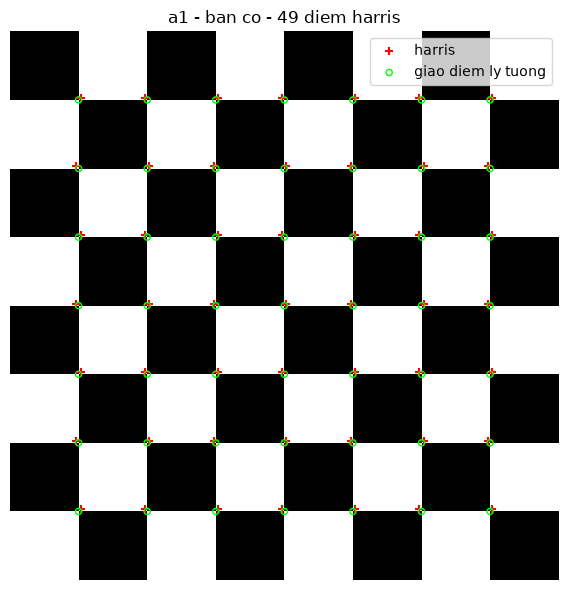

In [70]:
# a1 - ban co tong hop

cell_px = 16
so_o = 8

ban_co = np.zeros(
    (cell_px * so_o, cell_px * so_o),
    dtype=np.float64
)

for r in range(so_o):
    for c in range(so_o):
        if (r + c) % 2 == 1:
            ban_co[
                r * cell_px:(r + 1) * cell_px,
                c * cell_px:(c + 1) * cell_px
            ] = 255.0

# toa do 49 giao diem trong

giao_diem = np.array([
    (r * cell_px - 0.5, c * cell_px - 0.5)
    for r in range(1, so_o)
    for c in range(1, so_o)
], dtype=np.float64)


def danh_gia_ban_co(anh, ten):
    pts = harris_classic(
        anh,
        sigma_i=2.0,
        sigma_d=1.4,
        k=0.04,
        thresh_rel=0.01
    )

    if len(pts) > 0:
        d = np.linalg.norm(
            giao_diem[:, None, :] - pts[None, :, :2],
            axis=2
        )
        gan_nhat = d.min(axis=1)
        so_diem_gan = (d <= 1.0).sum(axis=1)
    else:
        gan_nhat = np.full(len(giao_diem), np.inf)
        so_diem_gan = np.zeros(len(giao_diem), dtype=int)

    hop_le = gan_nhat <= 1.0
    so_tim_thay = int(hop_le.sum())

    print(f"\n{ten}")
    print("kich thuoc anh:", anh.shape)
    print("so diem harris:", len(pts))
    print("so giao diem trong:", len(giao_diem))
    print("so giao diem trong 1 px:", so_tim_thay)
    print(
        "ti le giao diem trong 1 px:",
        round(so_tim_thay / len(giao_diem), 4)
    )
    print(
        "so giao diem co nhieu hon 1 diem harris:",
        int((so_diem_gan > 1).sum())
    )
    print(
        "sai so lon nhat (px):",
        round(float(gan_nhat.max()), 4)
    )
    print(
        "sai so trung binh (px):",
        round(float(gan_nhat.mean()), 4)
    )

    return pts


pts_255 = danh_gia_ban_co(
    ban_co,
    "ban co 0/255"
)

pts_01 = danh_gia_ban_co(
    ban_co / 255.0,
    "ban co 0/1"
)

pts_dao = danh_gia_ban_co(
    255.0 - ban_co,
    "ban co dao mau"
)

# hien thi ban co va cac diem

plt.figure(figsize=(6, 6))
plt.imshow(ban_co, cmap="gray")

if len(pts_255) > 0:
    plt.scatter(
        pts_255[:, 1],
        pts_255[:, 0],
        s=35,
        color="red",
        marker="+",
        label="harris"
    )

plt.scatter(
    giao_diem[:, 1],
    giao_diem[:, 0],
    s=20,
    facecolors="none",
    edgecolors="lime",
    marker="o",
    label="giao diem ly tuong"
)

plt.title(f"a1 - ban co - {len(pts_255)} diem harris")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

**Nhận xét kiểm chứng A1**

- Cả ba bản bàn cờ (0/255, 0/1 và đảo màu) đều trả đúng 49 điểm tại 49 giao điểm trong. Mỗi giao điểm có một điểm phát hiện, sai số lớn nhất 0,7071 px.
- Đạt yêu cầu sai số ≤ 1 px.

### Kiểm chứng A2 - Xoay ảnh 30 độ

Báo số điểm và repeatability bằng phép biến đổi tọa độ đúng. Người phụ trách: Gấm.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**


- Công cụ: ChatGPT (OpenAI)
- Mục đích: Hỗ trợ viết và rà soát code kiểm chứng A1, A2, A4 dựa trên 6 hàm Harris đã có
- Prompt nguyên văn: "Từ cài đặt 6 hàm của thuật toán Harris đã được cung cấp, hãy xây dựng và rà soát kiểm chứng theo yêu cầu sau:  
  A1: Kiểm chứng các giao điểm trong và sai số định vị không quá 1 px  
  A2: Báo số điểm góc phát hiện được và tính repeatability bằng phép biến đổi tọa độ chính xác  
  A4: Sử dụng cv2.cornerHarris trong cell đối chiếu và báo số điểm khớp trong khoảng 2–3 px"
- Phần đã tự sửa và kiểm tra: Kiểm tra, chạy thử và đối chiếu kết quả thực nghiệm

anh: home.jpg
kich thuoc anh: (384, 512)
goc xoay (do): 30.0
so diem anh goc: 332
so diem anh xoay: 290
so diem chieu nam trong anh xoay: 289
repeatability eps=1 px: 0.8235
repeatability eps=2 px: 0.8927
repeatability eps=3 px: 0.917
repeatability bang ma tran 3x3: 0.917
repeatability bang ham: 0.917
chenh lech hai cach tinh: 0.0


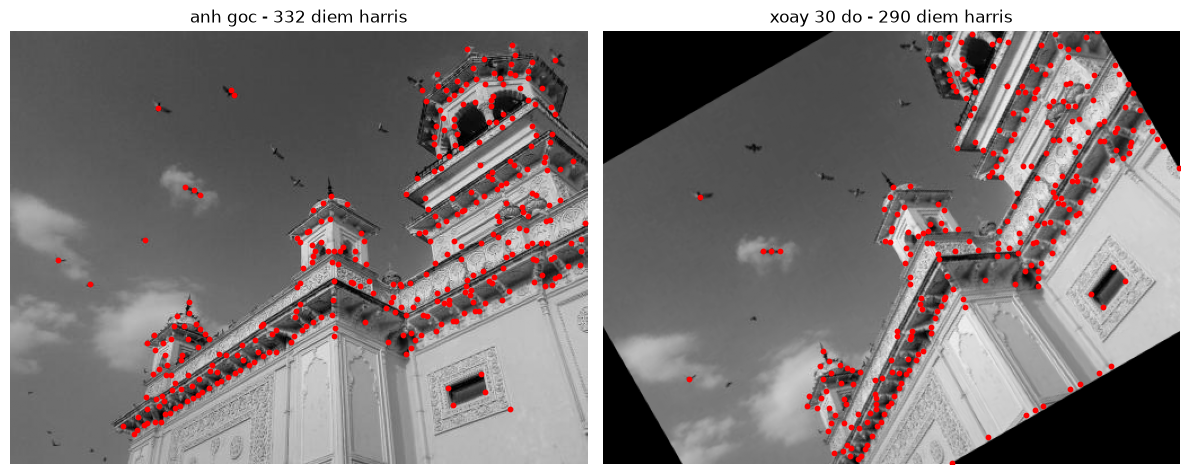

In [71]:

# a2 - xoay anh 30 do

import cv2

anh_goc = cv2.imread(
    str(IMAGES_DIR / "home.jpg"),
    cv2.IMREAD_GRAYSCALE
)

if anh_goc is None:
    raise FileNotFoundError("khong tim thay home.jpg")

anh_goc = anh_goc.astype(np.float64)
h, w = anh_goc.shape

goc = 30.0

M = cv2.getRotationMatrix2D(
    (w / 2, h / 2),
    goc,
    1.0
)

anh_xoay = cv2.warpAffine(
    anh_goc,
    M,
    (w, h)
)

H_xoay = np.vstack([
    M,
    [0.0, 0.0, 1.0]
])

pts_goc = harris_classic(anh_goc)
pts_xoay = harris_classic(anh_xoay)


def xoay_diem(p):
    # chuyen toa do row col sang x y

    x, y = p[1], p[0]

    x2 = M[0, 0] * x + M[0, 1] * y + M[0, 2]
    y2 = M[1, 0] * x + M[1, 1] * y + M[1, 2]

    return (y2, x2)


# tinh so diem chieu nam trong anh xoay

if len(pts_goc) > 0:
    chieu = np.array(
        [xoay_diem(p) for p in pts_goc[:, :2]],
        dtype=np.float64
    ).reshape(-1, 2)
else:
    chieu = np.empty((0, 2), dtype=np.float64)

trong_anh = (
    np.isfinite(chieu).all(axis=1) &
    (chieu[:, 0] >= 0) &
    (chieu[:, 0] < h) &
    (chieu[:, 1] >= 0) &
    (chieu[:, 1] < w)
)

rep_H = repeatability(
    pts_goc,
    pts_xoay,
    H_xoay,
    anh_xoay.shape,
    eps=3.0
)

rep_ham = repeatability(
    pts_goc,
    pts_xoay,
    xoay_diem,
    anh_xoay.shape,
    eps=3.0
)

print("anh:", "home.jpg")
print("kich thuoc anh:", anh_goc.shape)
print("goc xoay (do):", goc)
print("so diem anh goc:", len(pts_goc))
print("so diem anh xoay:", len(pts_xoay))
print(
    "so diem chieu nam trong anh xoay:",
    int(trong_anh.sum())
)

for e in (1.0, 2.0, 3.0):
    rep = repeatability(
        pts_goc,
        pts_xoay,
        H_xoay,
        anh_xoay.shape,
        eps=e
    )

    print(
        f"repeatability eps={e:.0f} px:",
        round(rep, 4)
    )

print(
    "repeatability bang ma tran 3x3:",
    round(rep_H, 4)
)
print(
    "repeatability bang ham:",
    round(rep_ham, 4)
)
print(
    "chenh lech hai cach tinh:",
    round(abs(rep_H - rep_ham), 8)
)

# hien thi anh goc va anh xoay

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(anh_goc, cmap="gray")

if len(pts_goc) > 0:
    ax[0].scatter(
        pts_goc[:, 1],
        pts_goc[:, 0],
        s=10,
        color="red",
        marker="o"
    )

ax[0].set_title(f"anh goc - {len(pts_goc)} diem harris")

ax[1].imshow(anh_xoay, cmap="gray")

if len(pts_xoay) > 0:
    ax[1].scatter(
        pts_xoay[:, 1],
        pts_xoay[:, 0],
        s=10,
        color="red",
        marker="o"
    )

ax[1].set_title(f"xoay 30 do - {len(pts_xoay)} diem harris")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()


**Nhận xét kiểm chứng:**

- Kết quả thực tế: Với ảnh home.jpg xoay 30°, phát hiện 332 điểm góc trên ảnh gốc và 290 điểm trên ảnh xoay, trong đó có 289 điểm chiếu hợp lệ. Repeatability lần lượt đạt 0,8235, 0,8927 và 0,9170 ở eps = 1, 2 và 3 px. Cả hai cách biến đổi tọa độ bằng ma trận 3×3 và hàm từng điểm đều cho kết quả giống nhau
- Đạt/chưa đạt và lý do: Đạt yêu cầu vì đã tính được tỷ lệ lặp lại của các điểm góc sau phép xoay, đạt 91.70% trong ngưỡng sai lệch 3 px. Hai cách biến đổi tọa độ cho kết quả thống nhất

Về lý thuyết, khi xoay ảnh, ma trận cấu trúc biến đổi theo phép đồng dạng trực giao. Định thức và vết của ma trận giữ nguyên, nên đáp ứng Harris tại vị trí tương ứng giữ nguyên trong mô hình liên tục. Ảnh số còn chịu ảnh hưởng của nội suy và biên mới do phép xoay.

Viền tạo ra sau phép xoay có thể sinh thêm điểm góc. Khi tính repeatability theo chiều ảnh gốc sang ảnh xoay, mẫu số là 289 điểm gốc chiếu vào trong ảnh.

### Kiểm chứng A3 - Phóng to 3 lần

Báo repeatability Harris cổ điển và Harris-Laplace. Người phụ trách: Nam.

Ảnh lựa chọn


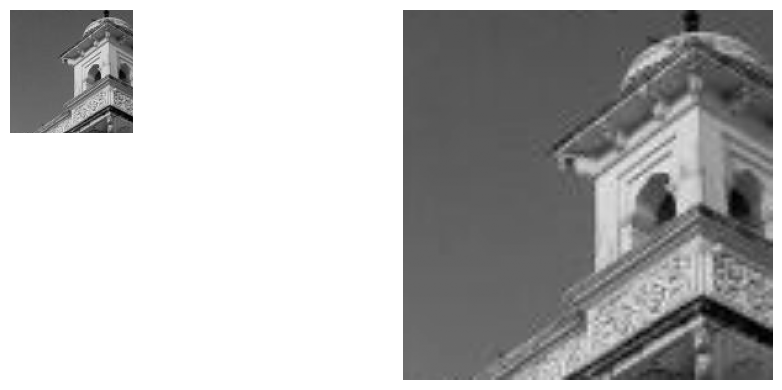

harris_classic
repeatability:  0.28125


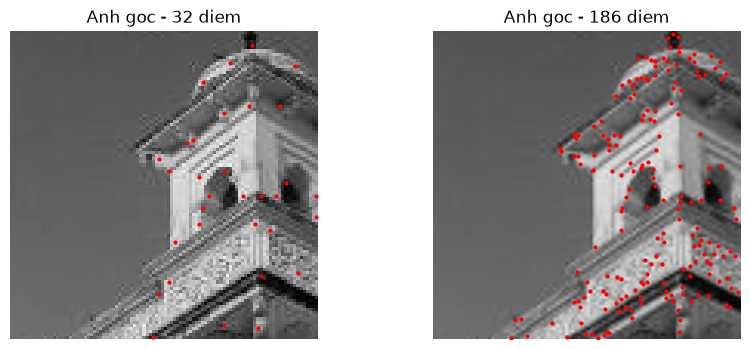

harris_laplace
repeatability:  0.6785714285714286


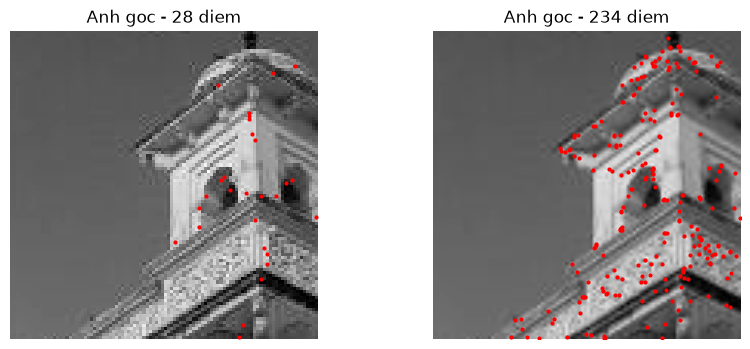

In [72]:
import cv2
def IShow(*I,T = None):
    n = len(I)
    f, ax = plt.subplots(1, n, figsize=(4 * n, 4), sharex=True, sharey=True)
    if n == 1:
        ax = [ax]
    for i, (a, Im) in enumerate(zip(ax, I)):
        a.imshow(Im.astype(np.uint8),cmap='gray',vmin=0,vmax=255)
        a.axis('off')  
        if T is not None:
            a.set_title(T[i], fontsize=9)        
    plt.tight_layout()
    plt.show()
I_O = cv2.imread(str(IMAGES_DIR / "home.jpg"), cv2.IMREAD_GRAYSCALE)
I_O = I_O.astype(np.float64)
h, w = I_O.shape
k = 100                             
r0, c0 = h // 2 - k // 2, w // 2 - k // 2
I_O = I_O[r0 : r0 + k, c0 : c0 + k]
I_RZ = cv2.resize(I_O,None,fx=3,fy=3,interpolation=cv2.INTER_LINEAR)
print("Ảnh lựa chọn")
IShow(I_O,I_RZ)
I_O_HC = harris_classic(I_O)
I_RZ_HC = harris_classic(I_RZ)
Z_3 = lambda p: (3 * p[0], 3 * p[1])
R =repeatability(I_O_HC,I_RZ_HC,Z_3,I_RZ.shape,eps=3.0)
print("harris_classic")
print("repeatability: ",R)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(I_O, cmap="gray")
ax[0].scatter(I_O_HC[:, 1], I_O_HC[:, 0], s=4, c="r")
ax[0].set_title(f"Anh goc - {len(I_O_HC)} diem")
ax[1].imshow(I_RZ, cmap="gray")
ax[1].scatter(I_RZ_HC[:, 1], I_RZ_HC[:, 0], s=4, c="r")
ax[1].set_title(f"Anh goc - {len(I_RZ_HC)} diem")
for a in ax:
    a.axis("off")
plt.show()
S = scale_pyramid(n_levels=16)
I_O_HL = harris_laplace(I_O,S)
I_RZ_HL = harris_laplace(I_RZ,S)
R =repeatability(I_O_HL,I_RZ_HL,Z_3,I_RZ.shape,eps=3.0)
print("harris_laplace")
print("repeatability: ",R)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(I_O, cmap="gray")
ax[0].scatter(I_O_HL[:, 1], I_O_HL[:, 0], s=4, c="r")
ax[0].set_title(f"Anh goc - {len(I_O_HL)} diem")
ax[1].imshow(I_RZ, cmap="gray")
ax[1].scatter(I_RZ_HL[:, 1], I_RZ_HL[:, 0], s=4, c="r")
ax[1].set_title(f"Anh goc - {len(I_RZ_HL)} diem")
for a in ax:
    a.axis("off")
plt.show()

**Nhận xét kiểm chứng:**

- Kết quả thực tế: ảnh home.jpg (ảnh xám), cắt vùng 100×100 ở giữa, phóng 3× bằng cv2.resize (nội suy song tuyến) thành ảnh 300×300. Ánh xạ tọa độ (row, col) → (3·row, 3·col); repeatability chỉ tính các điểm có ảnh chiếu nằm trong ảnh phóng, eps = 3 px cho cả hai phương pháp.
    - Harris cổ điển (σ_I = 2, σ_D = 1,4): 32 điểm ở ảnh gốc, 186 điểm ở ảnh phóng, repeatability = 0,281.
    - Harris–Laplace (tháp 16 tầng, σ₀ = 1,2, ξ = 1,2, σ từ 1,2 đến 18,5): 28 điểm ở ảnh gốc, 234 điểm ở ảnh phóng, repeatability = 0,679.
- Đạt/chưa đạt và lý do: Đạt. Harris–Laplace lặp lại tốt hơn Harris cổ điển khoảng 2,4 lần.
    - Harris cổ điển dùng cửa sổ σ_I cố định. Sau khi phóng 3×, một góc to gấp 3 so với cửa sổ, cửa sổ chỉ còn thấy một đoạn cạnh nên R không còn cực đại ở đó, và góc không được tìm lại.
    - Harris–Laplace chọn σ cho từng điểm tại cực đại của |LoG| chuẩn hóa theo trục tỉ lệ. Khi ảnh phóng 3×, cực đại này dời lên σ lớn gấp khoảng 3 lần, nên cửa sổ phủ cùng một vùng vật lý và góc được tìm lại.
    - Chọn 16 tầng thay vì 10: do bỏ tầng đầu và tầng cuối, σ dùng được là 1,44 … 15,4. Một góc có σ ở ảnh gốc cần 3σ ở ảnh phóng; với 10 tầng (σ dùng được tối đa 5,16) chỉ các góc có σ ≤ 1,72 mới tìm lại được ở cả hai ảnh.
    - Giới hạn: ảnh phóng có số điểm gấp khoảng 6–8 lần ảnh gốc, mà repeatability chỉ đếm theo chiều gốc → phóng, nên một phần điểm khớp có thể do trùng ngẫu nhiên; con số thật của cả hai phương pháp có thể thấp hơn. Ánh xạ 3x bỏ qua độ lệch 1 px do cv2.resize căn theo tâm pixel (chính xác là 3x + 1); sai số này nằm trong eps = 3 px.


### Kiểm chứng A4 - Đối chiếu OpenCV

Dùng cv2.cornerHarris trong cell đối chiếu; báo điểm khớp trong 2-3 px. Người phụ trách: Gấm.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**


- Công cụ: ChatGPT (OpenAI)
- Mục đích: Hỗ trợ viết và rà soát code kiểm chứng A1, A2, A4 dựa trên 6 hàm Harris đã có
- Prompt nguyên văn: "Từ cài đặt 6 hàm của thuật toán Harris đã được cung cấp, hãy xây dựng và rà soát kiểm chứng theo yêu cầu sau:  
  A1: Kiểm chứng các giao điểm trong và sai số định vị không quá 1 px  
  A2: Báo số điểm góc phát hiện được và tính repeatability bằng phép biến đổi tọa độ chính xác  
  A4: Sử dụng cv2.cornerHarris trong cell đối chiếu và báo số điểm khớp trong khoảng 2–3 px"
- Phần đã tự sửa và kiểm tra: Kiểm tra, chạy thử và đối chiếu kết quả thực nghiệm

anh: home.jpg
kich thuoc anh: (384, 512)
so diem harris cua nhom: 332
so diem harris opencv: 854

nguong 2 px
so diem nhom khop opencv: 244
ti le diem nhom khop opencv: 0.7349
so diem opencv khop nhom: 260
ti le diem opencv khop nhom: 0.3044

nguong 3 px
so diem nhom khop opencv: 299
ti le diem nhom khop opencv: 0.9006
so diem opencv khop nhom: 361
ti le diem opencv khop nhom: 0.4227

top 100 diem manh nhat
so diem nhom: 100
so diem opencv: 100
so diem khop trong 3 px: 48
ti le khop trong 3 px: 0.48


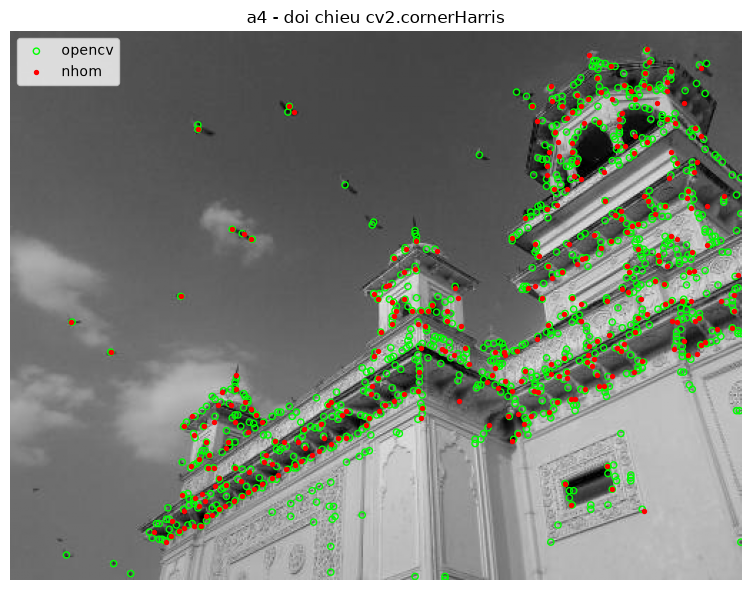

In [73]:

# a4 - doi chieu voi opencv

import cv2

anh = cv2.imread(
    str(IMAGES_DIR / "home.jpg"),
    cv2.IMREAD_GRAYSCALE
)

if anh is None:
    raise FileNotFoundError("khong tim thay home.jpg")

anh = anh.astype(np.float64)

pts_ta = harris_classic(
    anh,
    sigma_i=2.0,
    sigma_d=1.4,
    k=0.04,
    thresh_rel=0.01
)

# tinh dap ung harris bang opencv

R_cv = cv2.cornerHarris(
    anh.astype(np.float32),
    blockSize=5,
    ksize=3,
    k=0.04
).astype(np.float64)

max_cv = float(np.max(R_cv))

if max_cv > 0:
    mask_cv = nms_2d(R_cv, window=3)
    mask_cv &= np.isfinite(R_cv)
    mask_cv &= R_cv > 0.01 * max_cv
else:
    mask_cv = np.zeros(R_cv.shape, dtype=bool)

pts_cv = np.argwhere(mask_cv).astype(np.float64)

# tinh khoang cach giua hai tap diem

if len(pts_ta) > 0 and len(pts_cv) > 0:
    d = np.linalg.norm(
        pts_ta[:, None, :2] - pts_cv[None, :, :],
        axis=2
    )

    gan_ta = d.min(axis=1)
    gan_cv = d.min(axis=0)
else:
    gan_ta = np.full(len(pts_ta), np.inf)
    gan_cv = np.full(len(pts_cv), np.inf)

print("anh:", "home.jpg")
print("kich thuoc anh:", anh.shape)
print("so diem harris cua nhom:", len(pts_ta))
print("so diem harris opencv:", len(pts_cv))

for e in (2.0, 3.0):
    so_khop_ta = int((gan_ta <= e).sum())
    so_khop_cv = int((gan_cv <= e).sum())

    ti_le_ta = (
        so_khop_ta / len(pts_ta)
        if len(pts_ta) > 0 else 0.0
    )

    ti_le_cv = (
        so_khop_cv / len(pts_cv)
        if len(pts_cv) > 0 else 0.0
    )

    print(f"\nnguong {e:.0f} px")
    print("so diem nhom khop opencv:", so_khop_ta)
    print("ti le diem nhom khop opencv:", round(ti_le_ta, 4))
    print("so diem opencv khop nhom:", so_khop_cv)
    print("ti le diem opencv khop nhom:", round(ti_le_cv, 4))

# doi chieu 100 diem manh nhat

top_ta = pts_ta[:100, :2]

responses_cv = R_cv[mask_cv]
order_cv = np.argsort(-responses_cv, kind="stable")
top_cv = pts_cv[order_cv[:100]]

if len(top_ta) > 0 and len(top_cv) > 0:
    d_top = np.linalg.norm(
        top_ta[:, None, :] - top_cv[None, :, :],
        axis=2
    )

    gan_top = d_top.min(axis=1)
    so_khop_top = int((gan_top <= 3.0).sum())
    ti_le_top = float((gan_top <= 3.0).mean())
else:
    so_khop_top = 0
    ti_le_top = 0.0

print("\ntop 100 diem manh nhat")
print("so diem nhom:", len(top_ta))
print("so diem opencv:", len(top_cv))
print("so diem khop trong 3 px:", so_khop_top)
print("ti le khop trong 3 px:", round(ti_le_top, 4))

# hien thi ket qua doi chieu

plt.figure(figsize=(8, 6))
plt.imshow(anh, cmap="gray")

if len(pts_cv) > 0:
    plt.scatter(
        pts_cv[:, 1],
        pts_cv[:, 0],
        s=20,
        facecolors="none",
        edgecolors="lime",
        marker="o",
        label="opencv"
    )

if len(pts_ta) > 0:
    plt.scatter(
        pts_ta[:, 1],
        pts_ta[:, 0],
        s=8,
        color="red",
        marker="o",
        label="nhom"
    )

plt.title("a4 - doi chieu cv2.cornerHarris")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()


**Nhận xét kiểm chứng:**

- Kết quả thực tế: Trên ảnh home.jpg, thuật toán của nhóm phát hiện 332 điểm góc, trong khi OpenCV phát hiện 854 điểm. Có 244/332 điểm khớp trong ngưỡng 2 px (73.49%) và 299/332 điểm khớp trong ngưỡng 3 px (90.06%)
- Đạt/chưa đạt và lý do: Đạt yêu cầu vì đã đối chiếu được vị trí các điểm góc với cv2.cornerHarris(). Phần lớn điểm góc của thuật toán nhóm nằm gần điểm góc OpenCV trong ngưỡng 3 px, mặc dù số lượng điểm phát hiện giữa hai phương pháp còn chênh lệch

Hai cấu hình tính gradient và gộp tích đạo hàm khác nhau. OpenCV dùng Sobel 3×3 và cửa sổ hộp 5×5. Bản của nhóm làm mờ Gauss trước khi lấy đạo hàm với σD = 1,4 và gộp các tích đạo hàm với Gauss σI = 2. Các khác biệt đó thay đổi bản đồ đáp ứng và số cực đại vượt ngưỡng.

### Kiểm chứng A5 - Độ phủ ANMS

Cùng ứng viên, cùng N, so top_n và anms bằng grid_occupancy. Người phụ trách: Lên.

### 1.4 – Chuẩn bị bộ kiểm tra và hàm hỗ trợ thí nghiệm

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Chuẩn bị kiểm tra đầu ra và adapter gọi phép đo có sẵn; không cài đặt thuật toán bị cấm dùng AI.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482 " đây là nội dung phân công và hãy trình bày nhiệm vụ của Tấn Lên theo deadline trong sheeet nha.
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

In [74]:
def len_missing(names):
    return [name for name in names if not callable(globals().get(name))]

def len_check_selected(selected, candidates, n_keep):
    selected = np.asarray(selected, dtype=float)
    candidates = np.asarray(candidates, dtype=float)
    if selected.shape != (n_keep, 3):
        raise AssertionError(f'Đầu ra phải là ({n_keep}, 3), thực tế {selected.shape}.')
    if not np.isfinite(selected).all():
        raise AssertionError('Tọa độ/response đầu ra không được có NaN/Inf. Bán kính Inf không nằm trong 3 cột này.')
    # Kiểm tra đầu ra thực sự là tập con, kể cả khi đầu vào có hàng trùng.
    remaining = list(range(len(candidates)))
    for point in selected:
        index = next((j for j in remaining if np.allclose(point, candidates[j], rtol=1e-10, atol=1e-12)), None)
        if index is None:
            raise AssertionError('Đầu ra có hàng không thuộc đầu vào hoặc lặp vượt số lần có trong đầu vào.')
        remaining.remove(index)
    return selected

def len_measure_coverage(points, image_shape, grid_shape):
    # Adapter gọi hàm thật; KHÔNG cài đặt phép đo ở đây.
    value = float(grid_occupancy(points, image_shape, grid_shape=grid_shape))
    if not np.isfinite(value) or not 0 <= value <= 1:
        raise AssertionError('grid_occupancy phải trả tỉ lệ hữu hạn trong [0, 1].')
    return value

len_unit_results = []
missing = len_missing(['anms', 'top_n', 'grid_occupancy'])
print('Còn chờ cài đặt:', missing if missing else 'đã có đủ tên hàm; cần chạy kiểm tra bên dưới')

Còn chờ cài đặt: đã có đủ tên hàm; cần chạy kiểm tra bên dưới


### 2.2 – Cấu hình kiểm chứng và nguồn bàn giao

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Tạo cấu hình, hàm đọc ảnh hỗ trợ Unicode và biểu diễn điểm trên lưới. Lưới hiển thị dùng biên pixel -0.5 đến W-0.5/H-0.5.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482 " đây là nội dung phân công và hãy trình bày nhiệm vụ của Tấn Lên theo deadline trong sheeet nha.
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

**Cập nhật ngày 12/11/2026 – ChatGPT / Codex hỗ trợ:** Ghi commit Harris thực tế đã nhận; giữ trống A5_APPROVAL_REF vì chưa có kết quả/duyệt A5 của Lên.

Prompt nguyên văn cho lần cập nhật:

```text
[https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec](https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec)
```

In [75]:
# Nguồn thật: PR #30 đã được merge vào main. Chỉ A5 của Lên còn chờ duyệt.
HARRIS_SOURCE_COMMIT = '86c128c6933fcf07777f2ee3a6d6fa327128960b'
A5_APPROVAL_REF = ''  # Chỉ điền sau khi Nam/Hiệp duyệt A5; dùng cho Vòng 3.
LEN_HARRIS = dict(sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01)
LEN_GRID = (8, 8)
LEN_N = 100
LEN_C = 0.9

def len_read_gray(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f'Thiếu ảnh: {path}')
    data = np.frombuffer(path.read_bytes(), dtype=np.uint8)
    if data.size == 0:
        raise ValueError(f'Ảnh rỗng: {path}')
    gray = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise ValueError(f'Không giải mã được ảnh: {path}')
    return gray.astype(np.float64) / 255.0

def len_plot_points(ax, img, points, grid_shape, title):
    h, w = img.shape
    nr, nc = grid_shape
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    if len(points):
        ax.scatter(points[:,1], points[:,0], s=18, facecolors='none', edgecolors='red')
    for x in np.linspace(-0.5, w-0.5, nc+1):
        ax.axvline(x, color='deepskyblue', linewidth=0.5)
    for y in np.linspace(-0.5, h-0.5, nr+1):
        ax.axhline(y, color='deepskyblue', linewidth=0.5)
    ax.set_xlim(-0.5,w-0.5); ax.set_ylim(h-0.5,-0.5)
    ax.set_title(title); ax.set_xlabel('col'); ax.set_ylabel('row')

print('Nguồn Harris:', HARRIS_SOURCE_COMMIT or 'CHỜ BÀN GIAO / DUYỆT')
print('Phê duyệt A5:', A5_APPROVAL_REF or 'CHƯA CÓ')

Nguồn Harris: 86c128c6933fcf07777f2ee3a6d6fa327128960b
Phê duyệt A5: CHƯA CÓ


### 2.3 – Hai loại ảnh và ứng viên Harris cố định

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Tạo dữ liệu thử lặp lại được, đọc ảnh thật trong repo và gọi Harris đã bàn giao để cố định cùng tập ứng viên.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482 " đây là nội dung phân công và hãy trình bày nhiệm vụ của Tấn Lên theo deadline trong sheeet nha.
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

**Cập nhật ngày 12/11/2026 – ChatGPT / Codex hỗ trợ:** Chạy Harris đã bàn giao trên ảnh tổng hợp và home.jpg, kiểm tra giao diện và hiển thị toàn bộ ứng viên thật; chưa gọi là kết quả ANMS/Top-N.

Prompt nguyên văn cho lần cập nhật:

```text
[https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec](https://github.com/NguyenTanHiep07/xla-121036/tree/main/bai_tap_2/lam_viec)
```

**Khai báo AI cho lần cập nhật cell bên dưới**

- Công cụ:
- Mục đích:
- Prompt nguyên văn:
- Phần đã tự sửa và kiểm tra:

Tổng hợp cụm góc | số ứng viên M = 284 | số mức response khác nhau = 255
Ảnh home.jpg | số ứng viên M = 332 | số mức response khác nhau = 332


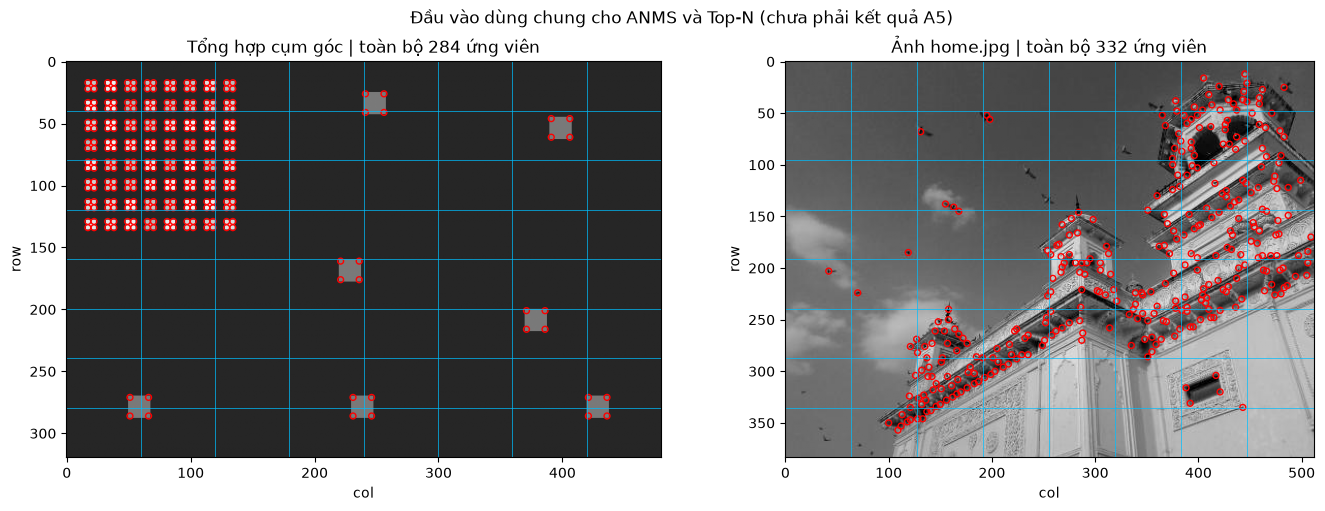

In [76]:
# ===== 2.3 – Hai loại ảnh và ứng viên Harris cố định (bản sửa) =====
# Ảnh tổng hợp: một cụm 64 ô vuông sáng (tương phản mạnh) ở góc trên trái và 7 ô vuông mờ nằm rải rác.
# Mỗi ô sáng có độ sáng KHÁC NHAU (0,70 -> 0,95) để các góc trong cụm không có đáp ứng bằng hệt nhau.
# Bản cũ dùng cùng một độ sáng 0,95 cho mọi ô nên 256 góc mạnh có response bằng nhau,
# không góc nào mạnh hơn góc khác 11% -> cả 256 điểm đều có r = vô cùng, ANMS trùng Top-N.
bo_sinh_do_sang = np.random.default_rng(12)          # cố định để chạy lại ra cùng ảnh
synthetic = np.full((320, 480), 0.15, dtype=float)
for row in range(16, 144, 16):
    for col in range(16, 144, 16):
        synthetic[row:row + 8, col:col + 8] = bo_sinh_do_sang.uniform(0.70, 0.95)
for row, col in [(25, 240), (45, 390), (160, 220), (200, 370), (270, 50), (270, 230), (270, 420)]:
    synthetic[row:row + 18, col:col + 18] = 0.48

len_images = {'Tổng hợp cụm góc': synthetic}
real_path = IMAGES_DIR / 'home.jpg'
if real_path.is_file():
    len_images['Ảnh home.jpg'] = len_read_gray(real_path)
else:
    print('CHƯA CÓ ảnh thật:', real_path)

len_candidates = {}
for name, img in len_images.items():
    points = np.asarray(harris_classic(img.copy(), **LEN_HARRIS), dtype=float)
    assert points.ndim == 2 and points.shape[1] == 3 and np.isfinite(points).all()
    assert np.all(points[:, 2] > 0) and np.all(np.diff(points[:, 2]) <= 0)
    len_candidates[name] = points.copy()
    so_muc_response = len(np.unique(np.round(points[:, 2] / points[:, 2].max(), 9)))
    print(f'{name} | số ứng viên M = {len(points)} | số mức response khác nhau = {so_muc_response}')

fig, axes = plt.subplots(1, len(len_candidates), figsize=(7 * len(len_candidates), 5),
                         squeeze=False, constrained_layout=True)
for ax, (name, points) in zip(axes[0], len_candidates.items()):
    len_plot_points(ax, len_images[name], points, LEN_GRID, f'{name} | toàn bộ {len(points)} ứng viên')
fig.suptitle('Đầu vào dùng chung cho ANMS và Top-N (chưa phải kết quả A5)')
plt.show()

### 2.4 – So sánh A5: cùng ứng viên, cùng N và cùng lưới

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Dựng kiểm chứng A5 và đo hai đầu ra thật; không tự điền kết quả khi chưa có thuật toán.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482  
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

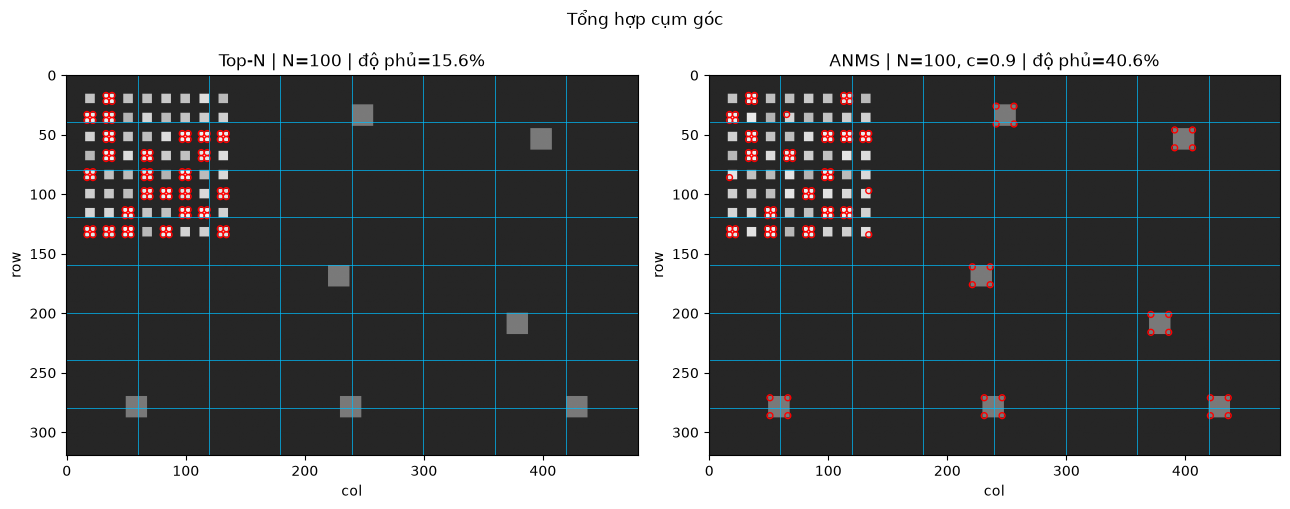

Tổng hợp cụm góc: M=284, N=100, grid=(8, 8), Top-N=0.1562, ANMS=0.4062, chênh lệch=+25.00 điểm phần trăm.


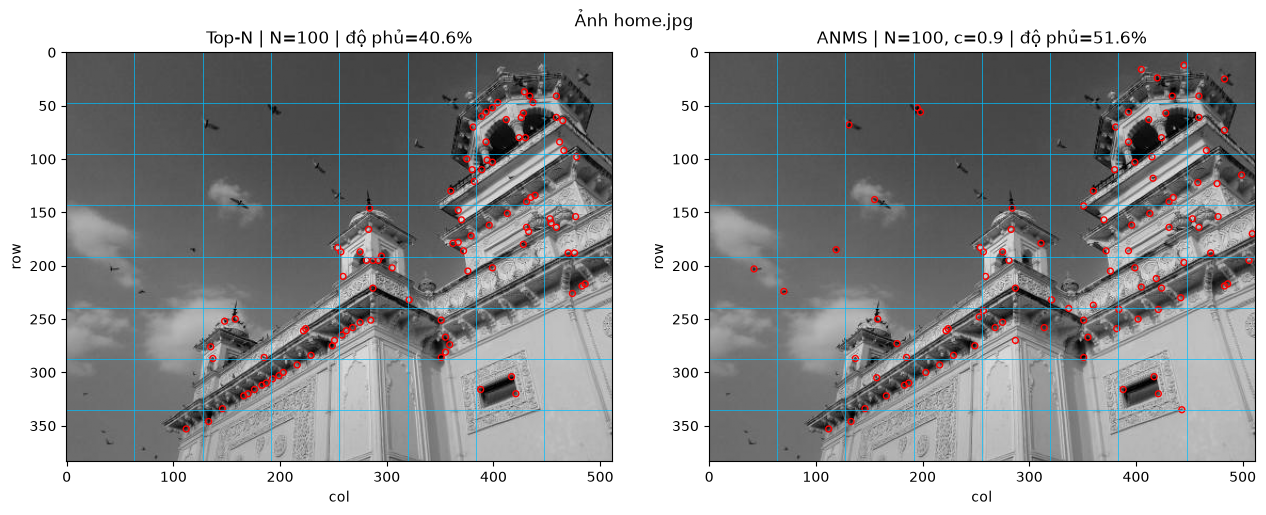

Ảnh home.jpg: M=332, N=100, grid=(8, 8), Top-N=0.4062, ANMS=0.5156, chênh lệch=+10.94 điểm phần trăm.
Số ảnh đã đo A5: 2
Độ phủ lớn hơn không đồng nghĩa định vị góc chính xác hơn.


In [77]:
len_a5_rows = []
missing = len_missing(['anms','top_n','grid_occupancy'])
if missing or not len_candidates:
    print('CHƯA CHẠY A5. Hàm thiếu:', missing, '| số tập ứng viên:', len(len_candidates))
else:
    for name, points in len_candidates.items():
        if len(points) < 2:
            print(name, ': quá ít ứng viên để so sánh.'); continue
        n = min(LEN_N, len(points))
        img = len_images[name]
        top = len_check_selected(top_n(points.copy(), n), points, n)
        kept = len_check_selected(anms(points.copy(), n, c_robust=LEN_C), points, n)
        cov_top = len_measure_coverage(top, img.shape, LEN_GRID)
        cov_anms = len_measure_coverage(kept, img.shape, LEN_GRID)
        len_a5_rows.append(dict(image=name, candidates=len(points), n=n,
                               c_robust=LEN_C, top=cov_top, anms=cov_anms))
        fig, axes = plt.subplots(1,2,figsize=(13,5))
        len_plot_points(axes[0],img,top,LEN_GRID,f'Top-N | N={n} | độ phủ={cov_top:.1%}')
        len_plot_points(axes[1],img,kept,LEN_GRID,f'ANMS | N={n}, c={LEN_C} | độ phủ={cov_anms:.1%}')
        fig.suptitle(name); plt.tight_layout(); plt.show()
        print(f'{name}: M={len(points)}, N={n}, grid={LEN_GRID}, '
              f'Top-N={cov_top:.4f}, ANMS={cov_anms:.4f}, '
              f'chênh lệch={(cov_anms-cov_top)*100:+.2f} điểm phần trăm.')

print('Số ảnh đã đo A5:', len(len_a5_rows))
print('Độ phủ lớn hơn không đồng nghĩa định vị góc chính xác hơn.')

**Nhận xét kiểm chứng:**

- Tổng hợp cụm góc (284 ứng viên, N = 100, lưới 8×8) có độ phủ Top-N 0,1562 và ANMS 0,4062, chênh lệch +25,00 điểm phần trăm.
- Ảnh home.jpg (332 ứng viên, N = 100, lưới 8×8) có độ phủ Top-N 0,4062 và ANMS 0,5156, chênh lệch +10,94 điểm phần trăm.

Cả hai chọn từ cùng tập ứng viên Harris. ANMS có thể giữ góc yếu nằm xa các góc đủ mạnh vì bán kính ức chế của góc đó lớn. Độ phủ đo mức phân bố trên lưới. Vị trí từng góc giữ nguyên qua bước chọn điểm.


### Dữ liệu chung cho B1–B4 và so sánh Region Growing với SRG

In [78]:
import cv2

image_path = IMAGES_DIR / "uneven_lighting.jpg"
test_img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
if test_img is None:
    raise FileNotFoundError(str(image_path))

test_seeds = [(50, 360), (120, 120)]
T_test = 15

### Kiểm chứng B1 - Phân hoạch đầy đủ

Kiểm tra mọi labels của SRG >= 0. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng cell kiểm chứng kết quả phân hoạch ảnh bằng SRG
- Prompt nguyên văn: Hãy hỗ trợ kiểm tra kết quả SRG, bao gồm kích thước bản đồ nhãn, kiểu dữ liệu, số pixel chưa được gán nhãn và kích thước bản đồ biên. Đối chiếu kết quả với yêu cầu kiểm chứng B1.
- Phần đã tự sửa và kiểm tra: Đã chạy cell, kiểm tra các điều kiện assert. Kết quả: 307.200 pixel đều được gán nhãn, không còn pixel chưa gán nhãn. B1: PASS.

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

In [79]:
labels_srg, boundary_mask = srg(
    test_img,
    test_seeds,
    connectivity=4,
    stale="lazy",
    tie="insertion"
)

unassigned_count = np.count_nonzero(labels_srg < 0)

print("Image shape:", test_img.shape)
print("Labels shape:", labels_srg.shape)
print("Labels dtype:", labels_srg.dtype)
print("Các nhãn xuất hiện:", np.unique(labels_srg))
print("Unassigned pixels:", unassigned_count)
print("Boundary pixels:", np.count_nonzero(boundary_mask))

assert labels_srg.shape == test_img.shape
assert labels_srg.dtype == np.int32
assert boundary_mask.shape == test_img.shape
assert np.all(labels_srg >= 0)

print("B1: PASS")

Image shape: (480, 640)
Labels shape: (480, 640)
Labels dtype: int32
Các nhãn xuất hiện: [0 1]
Unassigned pixels: 0
Boundary pixels: 1045
B1: PASS


**Nhận xét kiểm chứng:**

- Kết quả thực tế: SRG phân hoạch toàn bộ ảnh thành 2 vùng, không còn pixel chưa được gán nhãn. Có 1.045 pixel biên.
- Đạt/chưa đạt và lý do: Đạt. Kích thước bản đồ nhãn khớp ảnh đầu vào, kiểu dữ liệu đúng int32 và tất cả pixel đều có nhãn hợp lệ.

### Kiểm chứng B2 - Số vùng

Kiểm tra số nhãn phân biệt bằng số hạt giống hợp lệ. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng cell kiểm tra số vùng SRG có bằng số hạt giống hay không.
- Prompt nguyên văn: Hãy hỗ trợ viết cell kiểm chứng B2, đếm số nhãn phân biệt trong kết quả SRG, so sánh với số lượng hạt giống và kiểm tra điều kiện hai số bằng nhau.
- Phần đã tự sửa và kiểm tra:Đã chạy cell với 2 hạt giống. Kết quả có 2 vùng, nhãn [0, 1]. B2: PASS. 

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

In [80]:
# B2 - Kiểm chứng số vùng bằng số seed

num_regions = len(np.unique(labels_srg))
num_seeds = len(test_seeds)

print("Số seed:", num_seeds)
print("Số vùng thực tế:", num_regions)
print("Các nhãn:", np.unique(labels_srg))

assert num_regions == num_seeds

print("B2: PASS")

Số seed: 2
Số vùng thực tế: 2
Các nhãn: [0 1]
B2: PASS


**Nhận xét kiểm chứng:**

- Kết quả thực tế: Có 2 seed và 2 vùng được tạo ra, tương ứng nhãn 0 và 1.
- Đạt/chưa đạt và lý do: Đạt. Số vùng thực tế bằng số seed ban đầu.

### Kiểm chứng B3 - Đảo thứ tự hạt giống

So kết quả sau khi thống nhất lại ý nghĩa ID nhãn; ghi quy tắc phá hòa. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ thiết kế cell kiểm chứng ảnh hưởng của thứ tự hạt giống và quy tắc phá hòa đến kết quả SRG.
- Prompt nguyên văn: Hãy hỗ trợ xây dựng cell kiểm chứng B3 bằng cách đảo thứ tự hạt giống, quy đổi ID nhãn về thứ tự ban đầu rồi đếm số pixel thay đổi. Kiểm tra trên ảnh thật và ảnh phẳng với các quy tắc tie insertion, raster và random.
- Phần đã tự sửa và kiểm tra: Đã chạy thử trên ảnh thật và ảnh phẳng, so sánh số pixel khác nhau giữa kết quả ban đầu và kết quả sau khi đảo thứ tự hạt giống.

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

In [81]:
# ===== B3 - Bất biến thứ tự hạt giống =====
# Chạy srg với danh sách hạt giống và với chính danh sách đó đảo ngược, rồi đưa ID nhãn
# của lần đảo về ID của lần gốc trước khi so (seed thứ i của lần đảo là seed thứ n-1-i của lần gốc).


def doi_nhan_ve_thu_tu_goc(nhan_dao, so_hat):
    """Lần đảo: nhãn k ứng với seed gốc thứ (so_hat - 1 - k)."""
    nhan_goc = np.full_like(nhan_dao, -1)
    for k in range(so_hat):
        nhan_goc[nhan_dao == k] = so_hat - 1 - k
    return nhan_goc


def so_sanh_dao_thu_tu(anh, cac_hat, **cau_hinh):
    nhan_xuoi, _ = srg(anh, cac_hat, **cau_hinh)
    nhan_dao, _ = srg(anh, list(reversed(cac_hat)), **cau_hinh)
    nhan_dao = doi_nhan_ve_thu_tu_goc(nhan_dao, len(cac_hat))
    assert (nhan_dao >= 0).all()
    return int(np.count_nonzero(nhan_xuoi != nhan_dao))


# 1) Ảnh thật uneven_lighting.jpg, hai hạt giống như B1, đủ 3 quy tắc phá hòa
print(f"Ảnh thật {test_img.shape}, seeds = {test_seeds}, liên thông 4, stale = lazy")
for luat_hoa in ("insertion", "raster", "random"):
    so_khac = so_sanh_dao_thu_tu(test_img, test_seeds, connectivity=4, stale="lazy", tie=luat_hoa)
    print(f"  tie = {luat_hoa:<9}: {so_khac} pixel khác ({100 * so_khac / test_img.size:.4f}%)")

# 2) Ảnh phẳng: mọi delta bằng nhau, chỉ còn quy tắc phá hòa quyết định
anh_phang = np.full((40, 60), 128.0)
hat_phang = [(20, 15), (20, 45)]
print(f"\nẢnh phẳng 40x60, seeds = {hat_phang}, liên thông 4, stale = lazy")
for luat_hoa in ("insertion", "raster", "random"):
    so_khac = so_sanh_dao_thu_tu(anh_phang, hat_phang, connectivity=4, stale="lazy", tie=luat_hoa)
    print(f"  tie = {luat_hoa:<9}: {so_khac} pixel khác ({100 * so_khac / anh_phang.size:.2f}%)")

print("\nB3: DONE")

Ảnh thật (480, 640), seeds = [(50, 360), (120, 120)], liên thông 4, stale = lazy
  tie = insertion: 0 pixel khác (0.0000%)
  tie = raster   : 0 pixel khác (0.0000%)
  tie = random   : 0 pixel khác (0.0000%)

Ảnh phẳng 40x60, seeds = [(20, 15), (20, 45)], liên thông 4, stale = lazy
  tie = insertion: 40 pixel khác (1.67%)
  tie = raster   : 0 pixel khác (0.00%)
  tie = random   : 1297 pixel khác (54.04%)

B3: DONE


**Nhận xét kiểm chứng B3**

- Sau khi đảo thứ tự hạt giống, đổi ID nhãn về thứ tự gốc trước khi đếm pixel khác nhau. Bảng phía trên dùng bản SRG chung của Hiệp với `TIE_RANDOM_SEED = 0`.
- Trên ảnh phẳng, mọi δ bằng nhau. Quy tắc phá hòa có thể làm thay đổi thứ tự kết nạp và hình dạng vùng khi đổi thứ tự hạt giống.

### Kiểm chứng B4 - Stack, queue và SRG

Cùng ảnh, cùng seeds; báo số pixel khác nhau trong từng cặp. Người phụ trách: Sen.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng cell so sánh kết quả phân vùng của Region Growing sử dụng stack, queue và SRG.
- Prompt nguyên văn: Hãy hỗ trợ xây dựng cell kiểm chứng B4 để so sánh Region Growing với stack, Region Growing với queue và SRG trên cùng ảnh, cùng hạt giống và cùng ngưỡng T. Tính số pixel khác nhau giữa từng cặp phương pháp và hiển thị kết quả trực quan bằng ba hình ảnh.
- Phần đã tự sửa và kiểm tra: Đã chạy cell, kiểm tra số pixel khác nhau giữa từng cặp phương pháp và hiển thị ba kết quả phân vùng để đối chiếu.

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

Ảnh (480, 640) = 307200 pixel, seeds = [(50, 360), (120, 120)], T = 15, SRG: liên thông 4, lazy, insertion
  stack : pixel -1 =  188647, diện tích theo nhãn = {0: 56298, 1: 62255}
  queue : pixel -1 =  186944, diện tích theo nhãn = {0: 58673, 1: 61583}
  SRG   : pixel -1 =       0, diện tích theo nhãn = {0: 120309, 1: 186891}

cặp               tổng khác     khác nhãn khi cả hai đã gán   chỉ một bên gán
stack vs queue         9773                      0 / 114518              9773
stack vs SRG         188649                      2 / 118553            188647
queue vs SRG         186944                      0 / 120256            186944


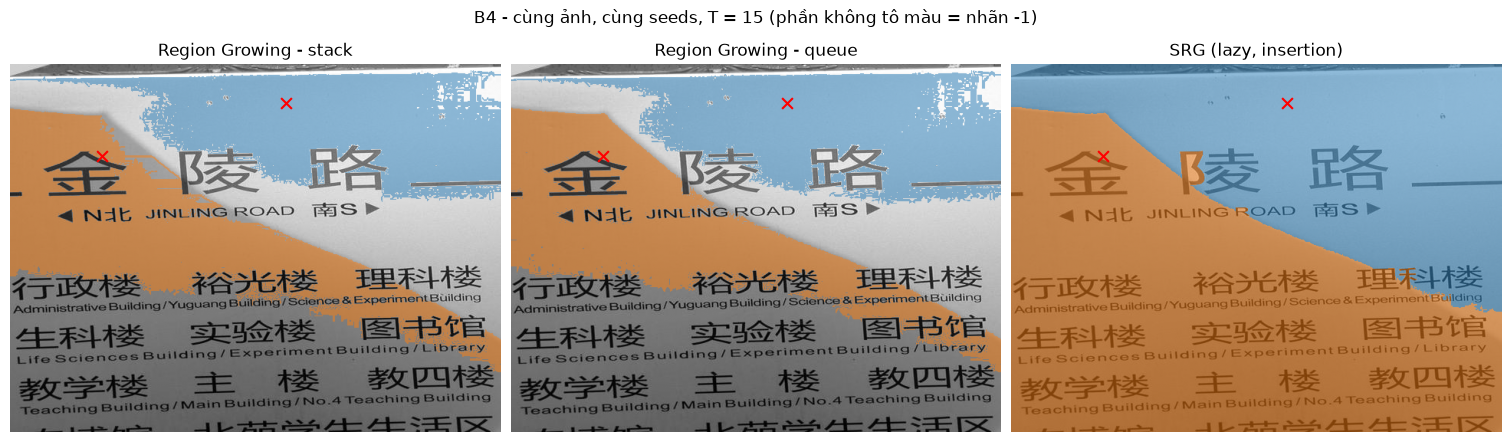

B4: DONE


In [82]:
# ===== B4 - So Region Growing (stack / queue) với SRG =====
# Cùng ảnh, cùng seeds, cùng ngưỡng T. ID nhãn của cả ba phương pháp đều là chỉ số seed trong danh sách,
# nên đã thẳng hàng, không cần đổi ID. Region Growing để -1 ở pixel không thuộc vùng nào còn SRG
# thì gán hết, nên tách riêng hai phần: pixel -1 và pixel khác nhãn trên phần cả hai đều đã gán.
T_B4 = T_test
nhan_stack = region_growing_classic(test_img, test_seeds, T=T_B4, order="stack")
nhan_queue = region_growing_classic(test_img, test_seeds, T=T_B4, order="queue")
nhan_srg, bien_srg = srg(test_img, test_seeds, connectivity=4, stale="lazy", tie="insertion")

print(f"Ảnh {test_img.shape} = {test_img.size} pixel, seeds = {test_seeds}, T = {T_B4}, "
      f"SRG: liên thông 4, lazy, insertion")
for ten, nhan in (("stack", nhan_stack), ("queue", nhan_queue), ("SRG", nhan_srg)):
    dien_tich = {k: int((nhan == k).sum()) for k in range(len(test_seeds))}
    print(f"  {ten:<6}: pixel -1 = {int((nhan == -1).sum()):>7}, diện tích theo nhãn = {dien_tich}")


def so_sanh_cap(nhan_a, nhan_b):
    tong_khac = int(np.count_nonzero(nhan_a != nhan_b))
    ca_hai_da_gan = (nhan_a >= 0) & (nhan_b >= 0)
    khac_khi_ca_hai_gan = int(np.count_nonzero((nhan_a != nhan_b) & ca_hai_da_gan))
    chi_mot_ben_gan = int(np.count_nonzero((nhan_a >= 0) != (nhan_b >= 0)))
    return tong_khac, khac_khi_ca_hai_gan, int(ca_hai_da_gan.sum()), chi_mot_ben_gan


print(f"\n{'cặp':<16}{'tổng khác':>11}{'khác nhãn khi cả hai đã gán':>32}{'chỉ một bên gán':>18}")
for ten, a, b in (("stack vs queue", nhan_stack, nhan_queue),
                  ("stack vs SRG", nhan_stack, nhan_srg),
                  ("queue vs SRG", nhan_queue, nhan_srg)):
    tong, khac_gan, so_gan, mot_ben = so_sanh_cap(a, b)
    print(f"{ten:<16}{tong:>11}{f'{khac_gan} / {so_gan}':>32}{mot_ben:>18}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
for ax, (ten, nhan) in zip(axes, (("Region Growing - stack", nhan_stack),
                                  ("Region Growing - queue", nhan_queue),
                                  ("SRG (lazy, insertion)", nhan_srg))):
    ax.imshow(test_img, cmap="gray")
    ax.imshow(np.ma.masked_less(nhan, 0), cmap="tab10", alpha=0.5, vmin=0, vmax=9)
    for r, c in test_seeds:
        ax.scatter(c, r, marker="x", s=60, c="red")
    ax.set_title(ten)
    ax.axis("off")
fig.suptitle(f"B4 - cùng ảnh, cùng seeds, T = {T_B4} (phần không tô màu = nhãn -1)")
plt.show()
print("B4: DONE")

**Nhận xét kiểm chứng B4**

- **stack vs queue** có 9.773 pixel khác, gồm 9.773 pixel chỉ một bên gán và 0/114.518 pixel khác nhãn trên phần cả hai đã gán.
- **stack vs SRG** có 188.649 pixel khác, gồm 188.647 pixel chỉ một bên gán và 2/118.553 pixel khác nhãn trên phần cả hai đã gán.
- **queue vs SRG** có 186.944 pixel khác, gồm 186.944 pixel chỉ một bên gán và 0/120.256 pixel khác nhãn trên phần cả hai đã gán.

Cả ba phương pháp dùng cùng ảnh và cùng hạt giống. Stack và queue dùng T = 15. Sự khác biệt chủ yếu nằm ở độ phủ vì SRG gán nhãn toàn ảnh.

### Kiểm chứng B5 - Ảnh phẳng, hai seeds

Mô tả hình dạng vùng với quy tắc phá hòa. Người phụ trách: Hiệp.

**Khai báo AI cho cell kiểm chứng B5**

- Công cụ: Claude (Anthropic).
- Mục đích: Hỗ trợ viết cell kiểm chứng B5 và vẽ ảnh tiến trình SRG.
- Prompt nguyên văn:
 > Viết cell kiểm chứng B5 bằng `srg` và `srg_step_frames` có sẵn. Dùng ảnh phẳng với hai hạt giống, so sánh ba quy tắc phá hòa ở liên thông 4 và 8. Kiểm ảnh được gán nhãn đầy đủ, có đúng hai vùng và chạy lại cho cùng kết quả. So sánh `lazy` với `frozen`, vẽ 8 mốc tiến trình và thử đổi seed của `random` để xem diện tích vùng thay đổi thế nào.
- Phần đã tự sửa và kiểm tra: không có

Cấu hình: ảnh 40x60, mọi pixel = 128.0, hạt giống = [(20, 15), (20, 45)], TIE_RANDOM_SEED = 0

cấu hình                    S0    S1  hộp bao vùng 0    hộp bao vùng 1     chia dọc  khớp gần nhất %  biên  t (ms)
lazy/insertion/4          1240  1160  r0-39,c0-30       r0-39,c31-59             31            100.0    40    59.5
frozen/insertion/4        1240  1160  r0-39,c0-30       r0-39,c31-59             31            100.0    40    80.1
lazy/raster/4             2399     1  r0-39,c0-59       r20-20,c45-45          None             50.9     4    87.7
frozen/raster/4           2399     1  r0-39,c0-59       r20-20,c45-45          None             50.9     4    54.4
lazy/random/4             1746   654  r0-39,c0-59       r0-28,c22-59           None             74.2    72    52.6
frozen/random/4           1746   654  r0-39,c0-59       r0-28,c22-59           None             74.2    72    74.1
lazy/insertion/8          1276  1124  r0-39,c0-36       r0-39,c31-59           None             99.5

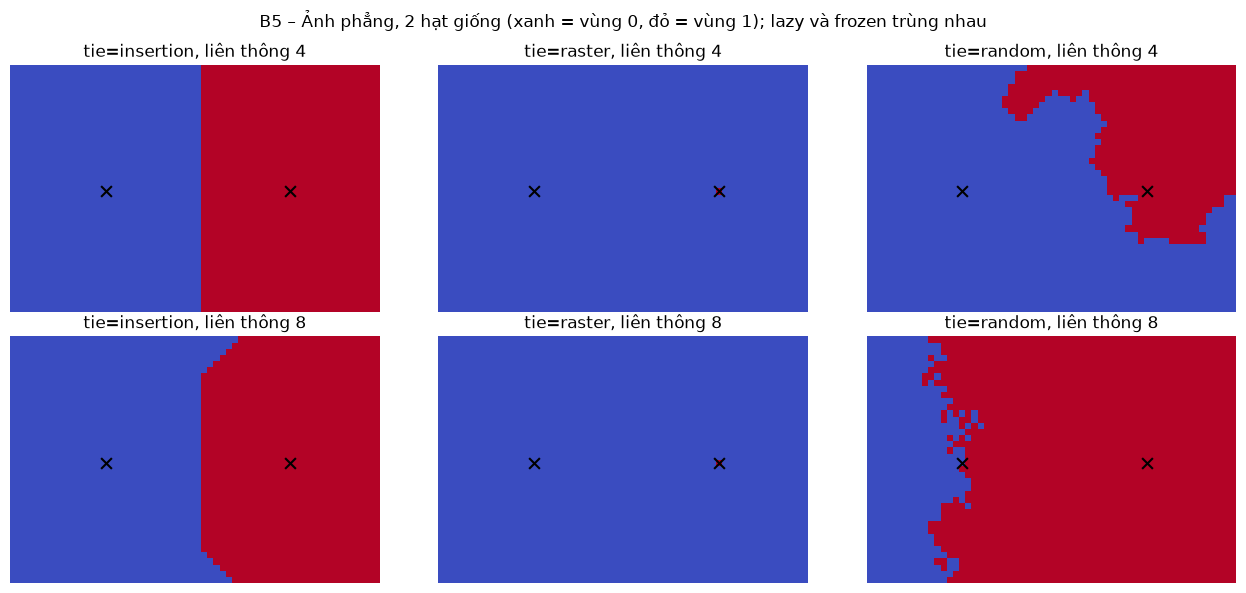

ĐẠT: 12 cấu hình đều phủ hết ảnh, đúng 2 vùng, chạy lại cho cùng kết quả.
tie                mốc 1         mốc 2         mốc 3         mốc 4         mốc 5         mốc 6         mốc 7         mốc 8
insertion        155/145       313/287       479/421       605/595       789/711       928/872     1078/1022     1240/1160   lazy == frozen ở cả 8 mốc: True
raster             299/1         599/1         899/1        1199/1        1499/1        1799/1        2099/1        2399/1   lazy == frozen ở cả 8 mốc: True
random            241/59        540/60       754/146       934/266      1175/325      1339/461      1550/550      1746/654   lazy == frozen ở cả 8 mốc: True
(mỗi ô: số pixel vùng 0 / vùng 1 tại mốc đó)


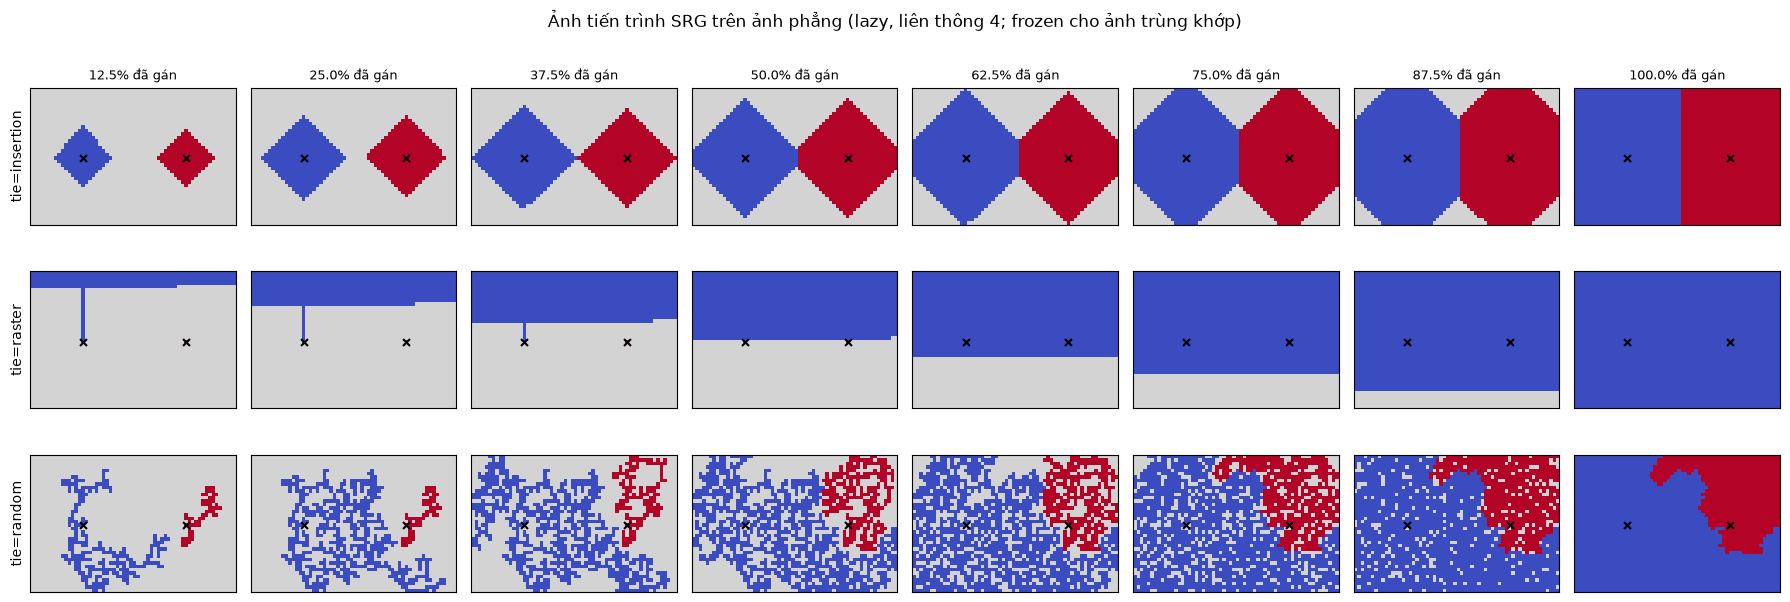

tie=random, liên thông 4, TIE_RANDOM_SEED = 0..9
Diện tích vùng 0: [1746, 950, 952, 1410, 561, 1590, 1041, 1708, 1790, 1]
Nhỏ nhất 1, lớn nhất 1790 trên 2400 pixel


In [83]:
CAO, RONG = 40, 60
GIA_TRI_PHANG = 128.0
anh_phang = np.full((CAO, RONG), GIA_TRI_PHANG)
hat_giong_phang = [(20, 15), (20, 45)]          
CAC_LUAT_HOA = ("insertion", "raster", "random")
CAC_CHE_DO_CU = ("lazy", "frozen")
CAC_LIEN_THONG = (4, 8)

print(f"Cấu hình: ảnh {CAO}x{RONG}, mọi pixel = {GIA_TRI_PHANG}, hạt giống = {hat_giong_phang}, "
      f"TIE_RANDOM_SEED = {TIE_RANDOM_SEED}")


def khoang_cach_toi_hat(hat, lien_thong):
    """Số bước ngắn nhất tới hạt trên ảnh không vật cản: 4 -> |dr|+|dc|, 8 -> max(|dr|,|dc|)."""
    hang, cot = np.indices((CAO, RONG))
    dr, dc = np.abs(hang - hat[0]), np.abs(cot - hat[1])
    return dr + dc if lien_thong == 4 else np.maximum(dr, dc)


def mo_ta_hinh_dang(nhan, bien, lien_thong):
    """Các số đo mô tả hình dạng hai vùng (chỉ dùng numpy)."""
    mo_ta = {}
    for i in range(len(hat_giong_phang)):
        hang, cot = np.nonzero(nhan == i)
        mo_ta[f"S{i}"] = hang.size
        mo_ta[f"hop{i}"] = f"r{hang.min()}-{hang.max()},c{cot.min()}-{cot.max()}"
    cot_chuyen = [np.argmax(h == 1) if (np.diff(h) >= 0).all() and h[-1] == 1 else -1 for h in nhan]
    mo_ta["chia_doc_tai_cot"] = cot_chuyen[0] if len(set(cot_chuyen)) == 1 and cot_chuyen[0] > 0 else None
    d0 = khoang_cach_toi_hat(hat_giong_phang[0], lien_thong)
    d1 = khoang_cach_toi_hat(hat_giong_phang[1], lien_thong)
    ro_rang = d0 != d1
    gan_nhat = (d1 < d0).astype(np.int32)
    mo_ta["khop_hat_gan_nhat_%"] = 100 * (nhan[ro_rang] == gan_nhat[ro_rang]).mean()
    mo_ta["so_pixel_bien"] = int(bien.sum())
    return mo_ta

ket_qua_b5 = {}
print(f"\n{'cấu hình':<24}{'S0':>6}{'S1':>6}  {'hộp bao vùng 0':<18}{'hộp bao vùng 1':<18}"
      f"{'chia dọc':>9}{'khớp gần nhất %':>17}{'biên':>6}{'t (ms)':>8}")
for lien_thong in CAC_LIEN_THONG:
    for luat in CAC_LUAT_HOA:
        for che_do in CAC_CHE_DO_CU:
            t0 = time.perf_counter()
            nhan, bien = srg(anh_phang, hat_giong_phang, connectivity=lien_thong, stale=che_do, tie=luat)
            t_ms = 1000 * (time.perf_counter() - t0)
            cau_hinh = f"{che_do}/{luat}/{lien_thong}"
            assert (nhan >= 0).all(), f"{cau_hinh}: còn pixel chưa gán"
            assert set(np.unique(nhan)) == {0, 1}, f"{cau_hinh}: số vùng khác 2"
            nhan_lai, _ = srg(anh_phang, hat_giong_phang, connectivity=lien_thong, stale=che_do, tie=luat)
            assert (nhan_lai == nhan).all(), f"{cau_hinh}: chạy lại cho kết quả khác"
            ket_qua_b5[(lien_thong, luat, che_do)] = nhan
            m = mo_ta_hinh_dang(nhan, bien, lien_thong)
            print(f"{cau_hinh:<24}{m['S0']:>6}{m['S1']:>6}  {m['hop0']:<18}{m['hop1']:<18}"
                  f"{str(m['chia_doc_tai_cot']):>9}{m['khop_hat_gan_nhat_%']:>17.1f}{m['so_pixel_bien']:>6}{t_ms:>8.1f}")

for lien_thong in CAC_LIEN_THONG:
    for luat in CAC_LUAT_HOA:
        so_khac = int((ket_qua_b5[(lien_thong, luat, "lazy")] != ket_qua_b5[(lien_thong, luat, "frozen")]).sum())
        print(f"liên thông {lien_thong}, tie={luat:<9}: số pixel khác nhau lazy vs frozen = {so_khac}")

for a, b in (("insertion", "raster"), ("insertion", "random"), ("raster", "random")):
    so_khac = int((ket_qua_b5[(4, a, "lazy")] != ket_qua_b5[(4, b, "lazy")]).sum())
    print(f"{a} vs {b}: {so_khac} pixel khác nhau ({100 * so_khac / anh_phang.size:.1f}%)")

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for hang_hinh, lien_thong in enumerate(CAC_LIEN_THONG):
    for cot_hinh, luat in enumerate(CAC_LUAT_HOA):
        ax = axes[hang_hinh, cot_hinh]
        ax.imshow(ket_qua_b5[(lien_thong, luat, "lazy")], cmap="coolwarm", vmin=0, vmax=1)
        for r, c in hat_giong_phang:
            ax.scatter(c, r, marker="x", s=60, c="black")
        ax.set_title(f"tie={luat}, liên thông {lien_thong}")
        ax.axis("off")
fig.suptitle("B5 – Ảnh phẳng, 2 hạt giống (xanh = vùng 0, đỏ = vùng 1); lazy và frozen trùng nhau")
plt.tight_layout()
plt.show()
print("ĐẠT: 12 cấu hình đều phủ hết ảnh, đúng 2 vùng, chạy lại cho cùng kết quả.")

SO_ANH_TIEN_TRINH = 8
anh_tien_trinh = {}
for luat in CAC_LUAT_HOA:
    for che_do in CAC_CHE_DO_CU:
        cac_anh = srg_step_frames(anh_phang, hat_giong_phang, n_frames=SO_ANH_TIEN_TRINH,
                                  connectivity=4, stale=che_do, tie=luat)
        assert len(cac_anh) == SO_ANH_TIEN_TRINH
        assert (cac_anh[-1] >= 0).all(), f"{che_do}/{luat}: ảnh cuối còn pixel chưa gán"
        assert (cac_anh[-1] == ket_qua_b5[(4, luat, che_do)]).all(), "ảnh cuối khác kết quả srg"
        anh_tien_trinh[(luat, che_do)] = cac_anh

print(f"{'tie':<10}" + "".join(f"{f'mốc {k}':>14}" for k in range(1, SO_ANH_TIEN_TRINH + 1)))
for luat in CAC_LUAT_HOA:
    trung = all((a == b).all() for a, b in zip(anh_tien_trinh[(luat, "lazy")], anh_tien_trinh[(luat, "frozen")]))
    dong = "".join(f"{f'{(f == 0).sum()}/{(f == 1).sum()}':>14}" for f in anh_tien_trinh[(luat, "lazy")])
    print(f"{luat:<10}{dong}   lazy == frozen ở cả 8 mốc: {trung}")
print("(mỗi ô: số pixel vùng 0 / vùng 1 tại mốc đó)")

fig, axes = plt.subplots(len(CAC_LUAT_HOA), SO_ANH_TIEN_TRINH, figsize=(18, 6.5))
for hang_hinh, luat in enumerate(CAC_LUAT_HOA):
    for k, (ax, anh) in enumerate(zip(axes[hang_hinh], anh_tien_trinh[(luat, "lazy")]), start=1):
        ax.imshow(np.ma.masked_less(anh, 0), cmap="coolwarm", vmin=0, vmax=1)
        ax.set_facecolor("lightgray")          
        for r, c in hat_giong_phang:
            ax.scatter(c, r, marker="x", s=25, c="black")
        ax.set_xticks([]); ax.set_yticks([])
        if hang_hinh == 0:
            ax.set_title(f"{100 * (anh >= 0).mean():.1f}% đã gán", fontsize=9)
        if k == 1:
            ax.set_ylabel(f"tie={luat}", fontsize=10)
fig.suptitle("Ảnh tiến trình SRG trên ảnh phẳng (lazy, liên thông 4; frozen cho ảnh trùng khớp)")
plt.tight_layout()
plt.show()

HAT_NGAU_NHIEN_GOC = TIE_RANDOM_SEED
dien_tich_vung_0 = []
for hat_nn in range(10):
    TIE_RANDOM_SEED = hat_nn                   
    nhan, _ = srg(anh_phang, hat_giong_phang, connectivity=4, stale="lazy", tie="random")
    assert (nhan >= 0).all() and set(np.unique(nhan)) == {0, 1}
    dien_tich_vung_0.append(int((nhan == 0).sum()))
TIE_RANDOM_SEED = HAT_NGAU_NHIEN_GOC           
print("tie=random, liên thông 4, TIE_RANDOM_SEED = 0..9")
print("Diện tích vùng 0:", dien_tich_vung_0)
print(f"Nhỏ nhất {min(dien_tich_vung_0)}, lớn nhất {max(dien_tich_vung_0)} trên {anh_phang.size} pixel")

**Nhận xét kiểm chứng B5**

- **Kết quả thực tế:** Cả 12 cấu hình đều gán đủ 2.400 pixel vào đúng hai vùng và cho cùng bản đồ nhãn khi chạy lại. Với liên thông 4 và `TIE_RANDOM_SEED = 0`:
  - `insertion`: Hai vùng ban đầu lan theo dạng hình thoi. Kết quả cuối chia dọc tại cột 31, với 1.240 pixel ở vùng 0 và 1.160 ở vùng 1. Các pixel gần một hạt hơn hẳn đều được gán đúng hạt gần nhất. Khi hai vùng có cùng δ tại một pixel, vùng có khóa hạt nhỏ hơn được chọn. Vì vậy, ở chế độ `insertion`, cột 30 cách đều hai hạt thuộc vùng 0.
  - `raster`: Vùng 0 lan lên hàng trên rồi chiếm gần hết ảnh. Vùng 1 chỉ còn pixel hạt giống, với diện tích hai vùng là 2.399 và 1 pixel.
  - `random`: Đường biên phụ thuộc vào khóa ngẫu nhiên. Vùng 0 có 1.746 pixel và vùng 1 có 654 pixel. Khi đổi seed ngẫu nhiên từ 0 đến 9, diện tích vùng 0 dao động từ 1 đến 1.790 pixel.
- **Đạt:** `lazy` và `frozen` cho cùng bản đồ nhãn ở cả 6 cặp cấu hình. Với liên thông 4, hai chế độ cũng trùng nhau tại cả 8 mốc tiến trình cho từng quy tắc phá hòa. Trên ảnh phẳng, mọi δ đều bằng 0 nên cách phá hòa quyết định thứ tự lan và hình dạng vùng. Sự khác biệt giữa `lazy` và `frozen` sẽ được kiểm tra trên ảnh chuyển màu ở Vòng 3.

## Thí nghiệm - A1: Harris-Laplace so với Harris cổ điển

Tự chọn dữ liệu, trục quét, số đo và kết luận. Theo mục 5.1, mỗi cặp cần bằng chứng khác biệt, quét tham số có ý nghĩa và giải thích cơ chế. Nếu thực tế dùng AI hỗ trợ cell thí nghiệm, ghi prompt nguyên văn ngay phía trên cell đó.

**Khai báo AI cho cell bên dưới (khung hàm phụ trợ cho thí nghiệm)**

- Công cụ: Claude (Anthropic), qua Claude Code.
- Mục đích: viết các hàm phụ trợ cho thí nghiệm A1: đọc, cắt, phóng ảnh; đổi tọa độ cho `repeatability`; chạy và đo hai phương pháp trên một cặp ảnh; quét một trục tham số và vẽ đường cong; vẽ điểm; ghép cặp điểm khớp, tỉ số σ, |LoG| theo σ tại một điểm, đếm ứng viên và điểm giữ lại theo tầng. Các hàm chỉ gọi lại hàm đã cài đặt, không chọn ảnh hay giá trị tham số.
- Prompt nguyên văn:

> giúp tôi viết phần khung phần thí nghiệm gồm các hàm con dùng để phục vụ cho thí nghiệm. Không cho sẵn ảnh hoặc thông số


- Phần đã tự sửa và kiểm tra:


In [84]:
import time
import cv2

# ---------- 1. Chuẩn bị dữ liệu ----------

# Đọc ảnh xám float64; V = None (cả ảnh) hoặc (r0, c0, h, w) để cắt
def ImRead(Name, V = None):
    I = cv2.imread(str(IMAGES_DIR / Name), cv2.IMREAD_GRAYSCALE)
    assert I is not None, f"Không đọc được ảnh: {Name}"
    I = I.astype(np.float64)
    if V is not None:
        r0, c0, h, w = V
        I = I[r0:r0 + h, c0:c0 + w]
    return I

# Vùng h x w nằm giữa ảnh có kích thước Sh -> (r0, c0, h, w)
def MidBox(Sh, h, w):
    H, W = Sh[:2]
    return (H // 2 - h // 2, W // 2 - w // 2, h, w)

# Phóng (s > 1) hoặc thu (s < 1) ảnh, nội suy song tuyến
def Zoom(I, s):
    return cv2.resize(I, None, fx=s, fy=s, interpolation=cv2.INTER_LINEAR)

# Đổi (row, col) ảnh gốc -> ảnh phóng s lần
# Ctr = True: theo tâm pixel của cv2.resize, x' = s*x + (s-1)/2 ; Ctr = False: x' = s*x
def ZMap(s, Ctr = True):
    d = (s - 1) / 2 if Ctr else 0.0
    return lambda p: (s * p[0] + d, s * p[1] + d)

# ---------- 2. Chạy và đo một cặp ảnh ----------

# Chạy 2 phương pháp trên A và B, đo repeatability A -> B
# Kw_HC, Kw_HL: dict tham số thêm cho harris_classic / harris_laplace
def Cmp(A, B, Tf, eps, S, Kw_HC = None, Kw_HL = None):
    Kw_HC = Kw_HC or {}
    Kw_HL = Kw_HL or {}
    F = {
        "harris_classic": lambda I: harris_classic(I, **Kw_HC),
        "harris_laplace": lambda I: harris_laplace(I, S, **Kw_HL),
    }
    Res = {}
    for N, f in F.items():
        t0 = time.perf_counter()
        pA, pB = f(A), f(B)
        Res[N] = {"A": pA, "B": pB,
                  "rep": repeatability(pA, pB, Tf, B.shape, eps=eps),
                  "t": time.perf_counter() - t0}
    return Res

def PrRes(Res):
    for N, v in Res.items():
        print(f"{N:15s} điểm A = {len(v['A']):4d}  điểm B = {len(v['B']):4d}  "
              f"repeatability = {v['rep']:.3f}  ({v['t']:.1f} s)")

# ---------- 3. Quét tham số ----------

# V: các giá trị cần thử; Mk(v): hàm tự viết, trả dict đối số cho Cmp
def Sweep(V, Mk, Ax = "giá trị"):
    Tb = {"V": list(V), "harris_classic": [], "harris_laplace": [], "Res": []}
    for v in V:
        Res = Cmp(**Mk(v))
        Tb["Res"].append(Res)
        for N in ("harris_classic", "harris_laplace"):
            Tb[N].append(Res[N]["rep"])
        print(f"{Ax} = {v}:  HC {Res['harris_classic']['rep']:.3f} | "
              f"HL {Res['harris_laplace']['rep']:.3f}")
    return Tb

# Đường repeatability theo trục quét
def CShow(Tb, X, T = "", M = ("harris_classic", "harris_laplace")):
    plt.figure(figsize=(6, 4))
    for N in M:
        plt.plot(Tb["V"], Tb[N], marker="o", label=N)
    plt.xlabel(X)
    plt.ylabel("repeatability")
    plt.ylim(0, 1.05)
    plt.title(T)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

# ---------- 4. Hiển thị điểm ----------

# Điểm trên A và B; Sg = True: tô màu theo sigma (chỉ cho Harris-Laplace)
def PShow(A, B, pA, pB, T = "", Sg = False):
    f, ax = plt.subplots(1, 2, figsize=(11, 5))
    for a, I, p, N in ((ax[0], A, pA, "Ảnh A"), (ax[1], B, pB, "Ảnh B")):
        a.imshow(I, cmap="gray")
        if len(p):
            if Sg:
                sc = a.scatter(p[:, 1], p[:, 0], c=p[:, 2], s=12, cmap="viridis")
                f.colorbar(sc, ax=a, label="σ")
            else:
                a.scatter(p[:, 1], p[:, 0], s=12, c="r")
        a.set_title(f"{N} - {len(p)} điểm")
        a.axis("off")
    f.suptitle(T)
    plt.tight_layout()
    plt.show()

# ---------- 5. Phân tích cơ chế ----------

# Ghép điểm A (chiếu vào trong B) với điểm B gần nhất nếu <= eps (cùng tiêu chí repeatability)
# -> mảng (K, 2): (chỉ số trong pA, chỉ số trong pB)
def Match(pA, pB, Tf, Sh, eps):
    if len(pA) == 0 or len(pB) == 0:
        return np.empty((0, 2), dtype=int)
    P = np.array([Tf(p) for p in pA[:, :2]], dtype=np.float64)
    h, w = Sh[:2]
    In = (P[:, 0] >= 0) & (P[:, 0] < h) & (P[:, 1] >= 0) & (P[:, 1] < w)
    D = np.linalg.norm(P[:, None, :] - pB[None, :, :2], axis=2)
    j = D.argmin(axis=1)
    Ok = In & (D[np.arange(len(pA)), j] <= eps)
    return np.column_stack((np.nonzero(Ok)[0], j[Ok]))

# sigma_B / sigma_A của các cặp khớp (Harris-Laplace, cột 2 là sigma)
def SgRatio(pA, pB, Pr):
    return pB[Pr[:, 1], 2] / pA[Pr[:, 0], 2]

# Bản đồ |LoG| cho mỗi sigma
def LogMaps(I, S):
    return [log_normalized(I, s) for s in S]

# |LoG| tại pixel (r, c) qua các tầng
def LogAt(Lm, r, c):
    return np.array([m[int(round(r)), int(round(c))] for m in Lm])

# Các đường |LoG| theo sigma (trục sigma thang log: phóng s lần = dịch ngang cố định)
def LogShow(Ss, Ys, Ns, T = ""):
    plt.figure(figsize=(6, 4))
    for s, y, n in zip(Ss, Ys, Ns):
        plt.plot(s, y, marker="o", label=n)
    plt.xscale("log")
    plt.xlabel("σ (thang log)")
    plt.ylabel("|LoG| chuẩn hóa")
    plt.title(T)
    plt.grid(alpha=0.3, which="both")
    plt.legend()
    plt.show()

# Số ứng viên Harris (giai đoạn 1) và số điểm giữ lại (sau LoG) mỗi tầng
# d phải khớp tỉ lệ sigma_d / sigma_i trong harris_laplace; Kw: k, thresh_rel
def LvCount(I, S, pts, d = 0.7, **Kw):
    Cd, Kp = [], []
    for s in S:
        Cd.append(len(harris_classic(I, sigma_i=s, sigma_d=d * s, **Kw)))
        Kp.append(int(np.isclose(pts[:, 2], s).sum()) if len(pts) else 0)
    return np.array(Cd), np.array(Kp)

# ---------- Cách dùng (tự điền ảnh và giá trị) ----------
# A = ImRead("<tên ảnh>", V=...)
# def Mk(v):
#     B = Zoom(A, v)
#     return dict(A=A, B=B, Tf=ZMap(v), eps=..., S=scale_pyramid(...))
# Tb = Sweep([...], Mk, Ax="<tên trục>")
# CShow(Tb, "<tên trục>")

### Thiết kế và bằng chứng khác biệt

Nêu ảnh nào, vì sao chọn, giữ cố định điều kiện gì và đo đại lượng nào. Trình bày kết quả của hai phương pháp.

Ảnh được chọn là cards.png.

Nguồn :https://github.com/opencv/opencv/blob/5.x/samples/data/cards.png.

Lý do : đây là ảnh có khá nhiều kích thước và tỉ lệ góc khác nhau. Nhưng nếu để ảnh gốc thì có thể khiến cho thời gian xử lý tăng khá lớn nên 150 là mức đủ để có nhiều góc và vừa chạy không quá lâu

Giữ cố định 150x150 phóng gấp đôi eps = 3 Nlevel = 16 tham số 2 bên mặc định và đo repeatability với số điểm ảnh

ảnh gốc


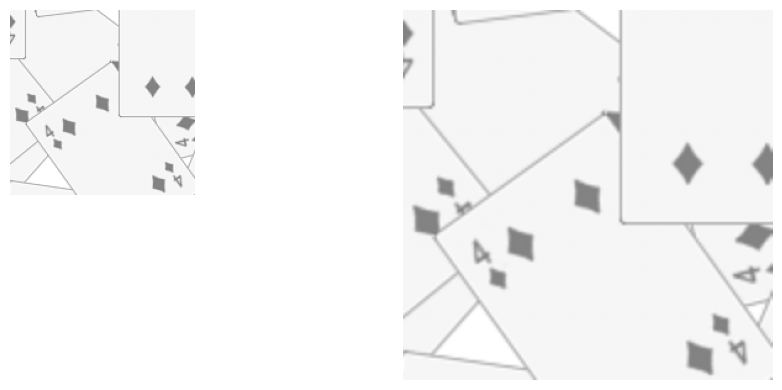

harris_classic  điểm A =   47  điểm B =   82  repeatability = 0.766  (0.1 s)
harris_laplace  điểm A =   45  điểm B =  123  repeatability = 0.956  (26.9 s)


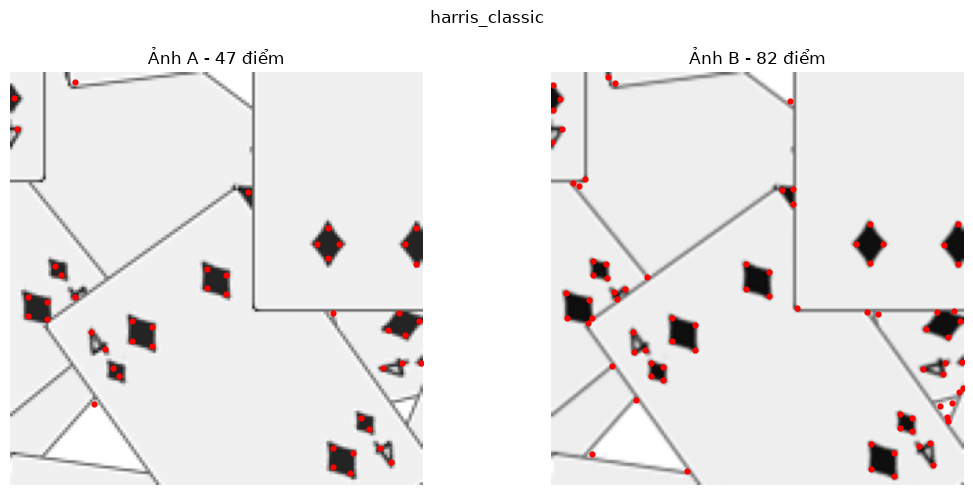

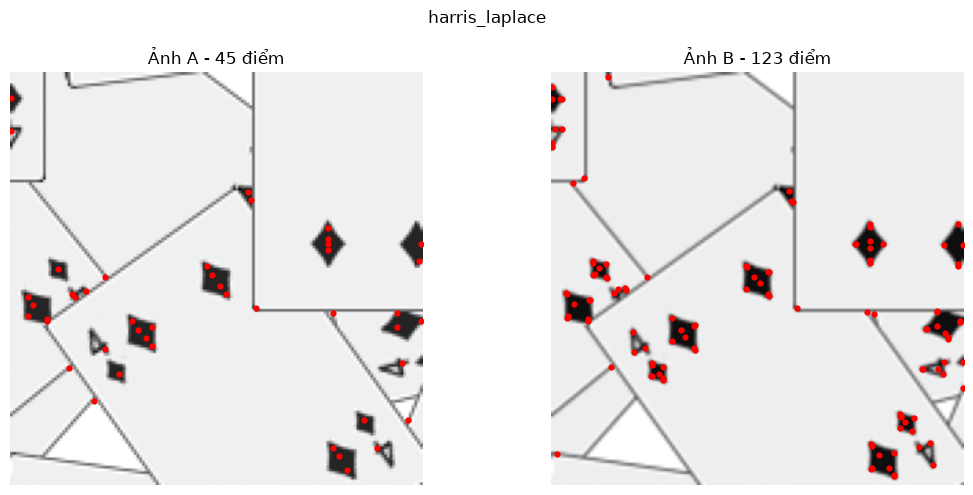

In [85]:
A = ImRead("cards.png")
A = ImRead("cards.png",MidBox(A.shape,150,150))
A_Z = Zoom(A,2)
print("ảnh gốc")
IShow(A,A_Z)
Res = Cmp(A,A_Z,ZMap(2),3,scale_pyramid(n_levels=16))
PrRes(Res)
PShow(A, A_Z, Res["harris_classic"]["A"],Res["harris_classic"]["B"], T = "harris_classic" )
PShow(A, A_Z, Res["harris_laplace"]["A"],Res["harris_laplace"]["B"], T = "harris_laplace" )


**Nhận xét từ số liệu đã chạy:**
Harris Laplace tìm lại được 95.6% so với Classic là 76.6% khi phóng x2 khác biệt ở khả năng thay đổi sigma và lọc LoG của Laplace làm khả năng tìm lại góc nhiều hơn


### Quét tham số

Ghi trục quét, giá trị thử và các điều kiện giữ cố định; trình bày đường cong hoặc điểm chuyển hành vi.

hệ số phóng = 1.0:  HC 1.000 | HL 1.000
hệ số phóng = 1.25:  HC 1.000 | HL 0.822
hệ số phóng = 1.5:  HC 1.000 | HL 0.844
hệ số phóng = 1.75:  HC 0.894 | HL 0.844
hệ số phóng = 2.0:  HC 0.766 | HL 0.956
hệ số phóng = 2.25:  HC 0.511 | HL 0.733
hệ số phóng = 2.5:  HC 0.447 | HL 0.867
hệ số phóng = 2.75:  HC 0.234 | HL 0.733
hệ số phóng = 3.0:  HC 0.340 | HL 0.733
 giá trị | HC rep    A    B | HL rep    A    B
     1.0 |  1.000   47   47 |  1.000   45   45
    1.25 |  1.000   47   69 |  0.822   45   75
     1.5 |  1.000   47   72 |  0.844   45  100
    1.75 |  0.894   47   76 |  0.844   45  120
     2.0 |  0.766   47   82 |  0.956   45  123
    2.25 |  0.511   47   90 |  0.733   45  130
     2.5 |  0.447   47   96 |  0.867   45  146
    2.75 |  0.234   47  107 |  0.733   45  153
     3.0 |  0.340   47  116 |  0.733   45  152

 phóng | số tầng tương ứng | lệch tầng |  HL - HC
  1.00 |              0.00 |      0.00 |   +0.000
  1.25 |              1.22 |      0.22 |   -0.178
  1.50 |       

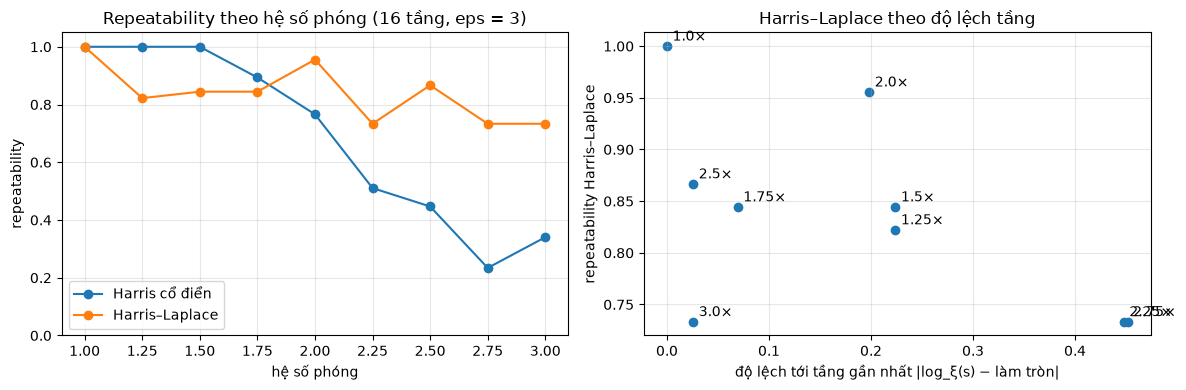

In [86]:
S16 = scale_pyramid(n_levels=16)

def PrTb(Tb):
    print(f"{'giá trị':>8} | {'HC rep':>6} {'A':>4} {'B':>4} | {'HL rep':>6} {'A':>4} {'B':>4}")
    for v, R in zip(Tb["V"], Tb["Res"]):
        hc, hl = R["harris_classic"], R["harris_laplace"]
        print(f"{v:>8} | {hc['rep']:6.3f} {len(hc['A']):4d} {len(hc['B']):4d} | "
              f"{hl['rep']:6.3f} {len(hl['A']):4d} {len(hl['B']):4d}")

def Mk_Z(v):
    B = Zoom(A, v)
    return dict(A=A, B=B, Tf=ZMap(v), eps=3, S=S16)

XI = 1.2
he_so_phong = [1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 2.75, 3.0]
bang_phong = Sweep(he_so_phong, Mk_Z, Ax="hệ số phóng")
PrTb(bang_phong)

so_tang = np.log(he_so_phong) / np.log(XI)
do_lech_tang = np.abs(so_tang - np.round(so_tang))
print(f"\n{'phóng':>6} | {'số tầng tương ứng':>17} | {'lệch tầng':>9} | {'HL - HC':>8}")
for s, t, l, hc, hl in zip(he_so_phong, so_tang, do_lech_tang,
                           bang_phong["harris_classic"], bang_phong["harris_laplace"]):
    print(f"{s:6.2f} | {t:17.2f} | {l:9.2f} | {hl - hc:+8.3f}")

hinh, truc = plt.subplots(1, 2, figsize=(12, 4))
for ten, nhan in (("harris_classic", "Harris cổ điển"), ("harris_laplace", "Harris–Laplace")):
    truc[0].plot(he_so_phong, bang_phong[ten], "o-", label=nhan)
truc[0].set_xlabel("hệ số phóng"); truc[0].set_ylabel("repeatability")
truc[0].set_ylim(0, 1.05); truc[0].grid(alpha=0.3); truc[0].legend()
truc[0].set_title("Repeatability theo hệ số phóng (16 tầng, eps = 3)")
truc[1].scatter(do_lech_tang, bang_phong["harris_laplace"])
for s, l, r in zip(he_so_phong, do_lech_tang, bang_phong["harris_laplace"]):
    truc[1].annotate(f"{s}×", (l, r), textcoords="offset points", xytext=(4, 4))
truc[1].set_xlabel("độ lệch tới tầng gần nhất |log_ξ(s) − làm tròn|")
truc[1].set_ylabel("repeatability Harris–Laplace")
truc[1].grid(alpha=0.3)
truc[1].set_title("Harris–Laplace theo độ lệch tầng")
plt.tight_layout()
plt.show()

**Khai báo AI cho cell bên dưới (quét số tầng)**

- Công cụ: Claude (Anthropic), qua Claude Code.
- Mục đích: viết cell quét số tầng của tháp (giữ ảnh, phóng 2×, eps như phần 1) và vẽ đường cong.
- Prompt nguyên văn:


> Viết giúp tôi phần quét tham số này […] với 3 kiểu hệ gồm HỆ SỐ PHÓNG , SỐ TẦNG và LOG_THRESH

- Phần đã tự sửa và kiểm tra: chưa sửa. Claude đã chạy thử cell trên một vùng nhỏ của `cards.png`.

số tầng = 8:  HC 0.766 | HL 0.581
số tầng = 10:  HC 0.766 | HL 0.689
số tầng = 16:  HC 0.766 | HL 0.956
số tầng = 18:  HC 0.766 | HL 0.956
 giá trị | HC rep    A    B | HL rep    A    B
       8 |  0.766   47   82 |  0.581   43  105
      10 |  0.766   47   82 |  0.689   45  112
      16 |  0.766   47   82 |  0.956   45  123
      18 |  0.766   47   82 |  0.956   45  123


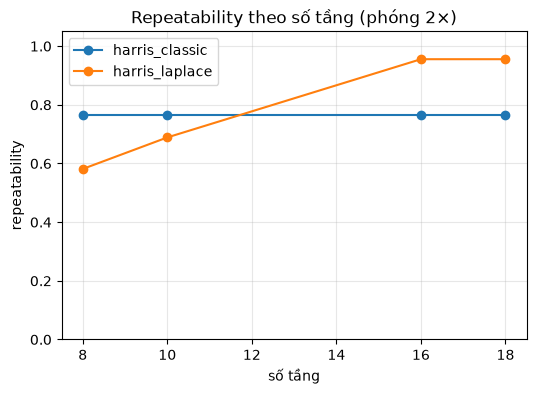

In [87]:
# Quét SỐ TẦNG
# Giữ cố định: ảnh A, phóng 2× (A_Z của phần 1), eps = 3, σ0 = 1,2, ξ = 1,2, tham số mặc định
# Harris cổ điển không dùng tháp nên đường của nó nằm ngang (đối chứng)
def Mk_N(v):
    return dict(A=A, B=A_Z, Tf=ZMap(2), eps=3, S=scale_pyramid(n_levels=v))

V_N = [8, 10, 16, 18]   # 16 = cấu hình phần 1
Tb_N = Sweep(V_N, Mk_N, Ax="số tầng")
PrTb(Tb_N)
CShow(Tb_N, "số tầng", T="Repeatability theo số tầng (phóng 2×)")

**Khai báo AI cho cell bên dưới (quét log_thresh)**

- Công cụ: Claude (Anthropic), qua Claude Code.
- Mục đích: viết cell quét `log_thresh` (giữ ảnh, phóng 2×, eps, tháp 16 tầng như phần 1); ngưỡng chọn theo phân vị của |LoG| tại các điểm Harris–Laplace trên ảnh gốc; vẽ đường cong.
- Prompt nguyên văn:

> Viết giúp tôi phần quét tham số này […] với 3 kiểu hệ gồm HỆ SỐ PHÓNG , SỐ TẦNG và LOG_THRESH

- Phần đã tự sửa và kiểm tra: chưa sửa. Claude đã chạy thử cell trên một vùng nhỏ của `cards.png`.

Phân vị: [0, 20, 40, 60]
Ngưỡng |LoG| tương ứng: [0.0, 34.3, 41.9, 47.5]
log_thresh = 0.0:  HC 0.766 | HL 0.956
log_thresh = 34.3:  HC 0.766 | HL 0.917
log_thresh = 41.9:  HC 0.766 | HL 0.778
log_thresh = 47.5:  HC 0.766 | HL 0.944
 giá trị | HC rep    A    B | HL rep    A    B
     0.0 |  0.766   47   82 |  0.956   45  123
    34.3 |  0.766   47   82 |  0.917   36   65
    41.9 |  0.766   47   82 |  0.778   27   27
    47.5 |  0.766   47   82 |  0.944   18   17


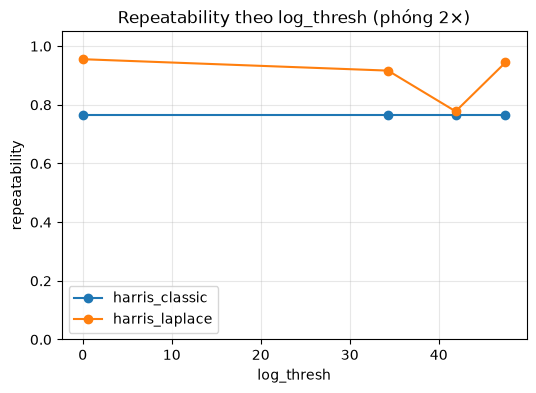

In [88]:
# Quét LOG_THRESH
# Giữ cố định: ảnh A, phóng 2×, eps = 3, tháp 16 tầng, các tham số khác mặc định
# Ngưỡng lấy theo phân vị của |LoG| tại các điểm Harris-Laplace trên ảnh gốc (kết quả phần 1),
# nên ngưỡng ở phân vị q loại khoảng q% số điểm của ảnh gốc
pA = Res["harris_laplace"]["A"]
Lm = LogMaps(A, S16)
M = np.array([Lm[int(np.argmin(np.abs(S16 - p[2])))][int(p[0]), int(p[1])] for p in pA])
Q = [0, 20, 40, 60]
V_L = [0.0] + [round(float(np.percentile(M, q)), 1) for q in Q[1:]]
print("Phân vị:", Q)
print("Ngưỡng |LoG| tương ứng:", V_L)

def Mk_L(v):
    return dict(A=A, B=A_Z, Tf=ZMap(2), eps=3, S=S16, Kw_HL={"log_thresh": v})

Tb_L = Sweep(V_L, Mk_L, Ax="log_thresh")
PrTb(Tb_L)
CShow(Tb_L, "log_thresh", T="Repeatability theo log_thresh (phóng 2×)")

**Nhận xét từ số liệu đã chạy:**



### Giải thích kết quả

Điền kết quả đo, giải thích đại lượng nào thay đổi, ở bước nào và vì sao. Báo cả trường hợp chưa cải thiện.

(1) Ảnh gốc: 307 ứng viên ở tầng 1..14 -> giữ 45 điểm

(2) Số điểm Harris-Laplace theo σ (phóng 2×, 16 tầng)
tầng      σ |  gốc | phóng
   0   1.20 |    0 |     0
   1   1.44 |   18 |     6
   2   1.73 |    7 |    17
   3   2.07 |    2 |    40
   4   2.49 |    6 |    27
   5   2.99 |    1 |    13
   6   3.58 |    9 |     2
   7   4.30 |    1 |     1
   8   5.16 |    1 |     6
   9   6.19 |    0 |     1
  10   7.43 |    0 |     9
  11   8.92 |    0 |     0
  12  10.70 |    0 |     1
  13  12.84 |    0 |     0
  14  15.41 |    0 |     0
  15  18.49 |    0 |     0
σ lớn nhất được chọn: ảnh gốc 5.16 | ảnh phóng 10.70

(3) Phóng 1.5×: 38/45 cặp khớp; σ_B/σ_A -> số cặp: {1.0: 2, 1.2: 7, 1.44: 15, 1.73: 12, 2.07: 2}
(3) Phóng 2.0×: 43/45 cặp khớp; σ_B/σ_A -> số cặp: {0.69: 1, 1.2: 1, 1.44: 3, 1.73: 10, 2.07: 28}

(4) Cặp (96, 49) -> (192, 97): σ được chọn 3.58 (gốc) và 7.43 (phóng); đỉnh |LoG| 69.1 và 73.7


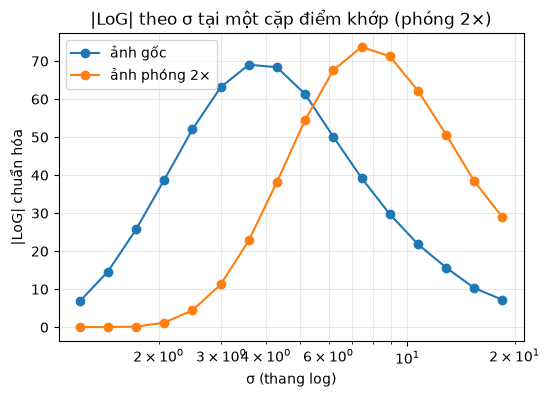


(5) harris_classic: thật 0.766 | chiếu lệch 15 px: TB 0.107, lớn nhất 0.200
(5) harris_laplace: thật 0.956 | chiếu lệch 15 px: TB 0.076, lớn nhất 0.182


In [89]:
hlA, hlB = Res["harris_laplace"]["A"], Res["harris_laplace"]["B"]

Cd, Kp = LvCount(A, S16, hlA)
print(f"(1) Ảnh gốc: {Cd[1:-1].sum()} ứng viên ở tầng 1..{len(S16) - 2} -> giữ {Kp.sum()} điểm")

print("\n(2) Số điểm Harris-Laplace theo σ (phóng 2×, 16 tầng)")
print(f"{'tầng':>4} {'σ':>6} | {'gốc':>4} | {'phóng':>5}")
for n, s in enumerate(S16):
    print(f"{n:4d} {s:6.2f} | {int(np.isclose(hlA[:, 2], s).sum()):4d} | "
          f"{int(np.isclose(hlB[:, 2], s).sum()):5d}")
print(f"σ lớn nhất được chọn: ảnh gốc {hlA[:, 2].max():.2f} | ảnh phóng {hlB[:, 2].max():.2f}")

print()
for v in (1.5, 2.0):
    R = bang_phong["Res"][bang_phong["V"].index(v)]["harris_laplace"]
    Pr = Match(R["A"], R["B"], ZMap(v), Zoom(A, v).shape, 3)
    gia_tri, so_cap = np.unique(np.round(SgRatio(R["A"], R["B"], Pr), 2), return_counts=True)
    cnt = dict(zip(gia_tri.tolist(), so_cap.tolist()))
    print(f"(3) Phóng {v}×: {len(Pr)}/{len(R['A'])} cặp khớp; σ_B/σ_A -> số cặp:",
          dict(sorted(cnt.items())))

LmA, LmB = LogMaps(A, S16), LogMaps(A_Z, S16)
Pr2 = Match(hlA, hlB, ZMap(2), A_Z.shape, 3)
h, w = A.shape
i, j = next((i, j) for i, j in Pr2
            if 10 <= hlA[i, 0] < h - 10 and 10 <= hlA[i, 1] < w - 10)
yA, yB = LogAt(LmA, *hlA[i, :2]), LogAt(LmB, *hlB[j, :2])
print(f"\n(4) Cặp ({int(hlA[i, 0])}, {int(hlA[i, 1])}) -> ({int(hlB[j, 0])}, {int(hlB[j, 1])}): "
      f"σ được chọn {hlA[i, 2]:.2f} (gốc) và {hlB[j, 2]:.2f} (phóng); "
      f"đỉnh |LoG| {yA.max():.1f} và {yB.max():.1f}")
LogShow([S16, S16], [yA, yB], ["ảnh gốc", "ảnh phóng 2×"],
        T="|LoG| theo σ tại một cặp điểm khớp (phóng 2×)")

print()
Z2 = ZMap(2)
for N in ("harris_classic", "harris_laplace"):
    pA, pB = Res[N]["A"], Res[N]["B"]
    v = [repeatability(pA, pB, lambda p, a=a: (Z2(p)[0] + 15 * np.sin(a), Z2(p)[1] + 15 * np.cos(a)),
                       A_Z.shape, eps=3)
         for a in np.radians(np.arange(0, 360, 30))]
    print(f"(5) {N}: thật {Res[N]['rep']:.3f} | chiếu lệch 15 px: TB {np.mean(v):.3f}, lớn nhất {np.max(v):.3f}")

**Khai báo AI cho cell nhận xét bên dưới**

- Công cụ: Claude (Anthropic), qua Claude Code.
- Mục đích: viết nhận xét giải thích cơ chế từ số liệu của các cell quét tham số và cell số liệu giải thích.
- Prompt nguyên văn:

> viết giúp tôi phần giải thích

- Phần đã tự sửa và kiểm tra: đối chiếu các con số với output của các cell phía trên.

**Nhận xét từ số liệu đã chạy:**

Harris–Laplace có hai bước: bước 1 chạy Harris ở mọi tầng σ; bước 2 chỉ giữ một điểm khi |LoG| chuẩn hóa σ²|Lxx + Lyy| tại **cùng pixel** đạt cực đại theo trục σ. Bước 2 lọc rất mạnh: ở ảnh gốc, 307 ứng viên của tầng 1–14 chỉ còn 45 điểm (số liệu (1)). Đại lượng quyết định các kết quả dưới đây là **σ được chọn cho từng điểm** ở bước 2.

**1. Vì sao Harris–Laplace tìm lại góc tốt hơn khi phóng ảnh (phần 1, phóng 2×: 0,956 so với 0,766)**
- Đại lượng: σ tại cực đại |LoG|; bước 2.
- Đường |LoG| theo σ tại một cặp điểm khớp (hình, số liệu (4)): ảnh gốc đạt đỉnh ở σ = 3,58, ảnh phóng 2× ở σ = 7,43. Hai đường cùng hình dạng, dịch đúng 4 tầng (1,2⁴ = 2,07 ≈ 2), và đỉnh cao gần bằng nhau (69,1 và 73,7) nhờ hệ số σ². Vì đỉnh dịch theo hệ số phóng, cửa sổ σ_I = σ_n to theo vật nên vẫn bắt đúng góc.
- Trên toàn bộ cặp khớp ở 2×: 28/43 cặp có σ_B/σ_A = 2,07 (số liệu (3)).
- Harris cổ điển dùng σ_I = 2 cố định cho mọi góc nên ở 2× chỉ còn 0,766.
- Đối chứng: khi cố ý chiếu lệch 15 px, repeatability chỉ còn 0,107 (Harris cổ điển) và 0,076 (Harris–Laplace) (số liệu (5)), nên khác biệt không đến từ trúng ngẫu nhiên.

**2. Quét số tầng (Harris–Laplace: 0,581 → 0,689 → 0,956 → 0,956 ở 8, 10, 16, 18 tầng)**
- Đại lượng: dải σ của tháp. Do bỏ tầng đầu và tầng cuối, σ dùng được tới 1,2^(N−1): 3,58 (8 tầng), 5,16 (10), 15,41 (16), 22,19 (18).
- Bước: bước 2 chỉ giữ điểm có đỉnh |LoG| nằm trong dải.
- Vì sao: ở ảnh phóng 2×, σ được chọn lên tới 10,70 (số liệu (2)). Với 8–10 tầng, đỉnh |LoG| của các góc lớn ở ảnh phóng vượt khỏi dải nên bị loại; Harris–Laplace khi đó còn **thua** Harris cổ điển (0,766). Cần ít nhất 14 tầng để dải chứa σ = 10,70; từ đó thêm tầng không đổi gì, nên 16 và 18 tầng đều cho 0,956 (bão hòa).

**3. Quét hệ số phóng (Harris cổ điển 1,000 / 1,000 / 0,766; Harris–Laplace 1,000 / 0,844 / 0,956 ở 1,0× / 1,5× / 2,0×)**
- 1,0×: cả hai bằng 1,000 — kiểm tra quy trình đo đúng.
- 2,0×: Harris cổ điển giảm vì cửa sổ cố định, Harris–Laplace giữ được (giải thích ở mục 1).
- 1,5×: Harris–Laplace chỉ đạt 0,844, thấp hơn ở 2× và thấp hơn Harris cổ điển. Nhiều khả năng do σ rời rạc theo bước ξ = 1,2: tỉ số σ_B/σ_A chỉ nhận lũy thừa của 1,2. Phóng 2× ≈ 1,2^3,8, gần tròn 4 tầng; phóng 1,5× ≈ 1,2^2,2, nằm giữa 2 và 3 tầng. Số liệu (3): ở 1,5× không có cặp nào có tỉ số 1,5, các cặp chia ra 1,44 (15 cặp) và 1,73 (12 cặp), và chỉ 38/45 điểm khớp. Harris cổ điển ở 1,5× chưa bị ảnh hưởng vì góc mới to thêm 50%, cửa sổ σ_I = 2 vẫn đủ thấy.

**4. Quét log_thresh (Harris–Laplace: 0,956 / 0,917 / 0,778 / 0,944 ở ngưỡng 0 / 34,3 / 41,9 / 47,5) — chưa cải thiện**
- Đại lượng: |LoG| tại tầng được chọn; bước 2 thêm điều kiện |LoG| > log_thresh.
- Ngưỡng loại điểm đúng như thiết kế (ảnh gốc 45 → 36 → 27 → 18 điểm) nhưng không làm repeatability tăng.
- Vì sao: theo lý thuyết, |LoG| chuẩn hóa tại hai điểm tương ứng bằng nhau; thực tế lệch nhẹ (69,1 so với 73,7 ở số liệu (4)) do nội suy khi phóng và σ rời rạc. Ngưỡng cứng vì vậy cắt hai ảnh không đều: có lúc giữ điểm ở ảnh gốc nhưng cắt mất điểm tương ứng ở ảnh phóng (ngưỡng 41,9: ảnh phóng chỉ còn 27 điểm, repeatability tụt còn 0,778). Ở ngưỡng 47,5 chỉ còn 18 điểm mạnh nhất, ổn định, nên tăng lại 0,944.
- Kết luận: trên ảnh này log_thresh chỉ làm ít điểm đi, không cải thiện repeatability; dao động một phần do mẫu nhỏ (mỗi điểm ≈ 4–5%).

**Giới hạn:** một ảnh, vùng 150×150 (45–47 điểm ở ảnh gốc); eps = 3 px cố định; repeatability chỉ tính theo chiều ảnh gốc → ảnh phóng.

## Thí nghiệm - A2: ANMS so với Top-N của Harris một tỉ lệ

Tự chọn dữ liệu, trục quét, số đo và kết luận. Theo mục 5.1, mỗi cặp cần bằng chứng khác biệt, quét tham số có ý nghĩa và giải thích cơ chế. Nếu thực tế dùng AI hỗ trợ cell thí nghiệm, ghi prompt nguyên văn ngay phía trên cell đó.

### Thiết kế và bằng chứng khác biệt

Nêu ảnh nào, vì sao chọn, giữ cố định điều kiện gì và đo đại lượng nào. Trình bày kết quả của hai phương pháp.

Thiết kế hai trục quét để thấy được xu hướng, không chỉ vài ảnh rời:
- Quét `c_robust`: 0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 1.00; giữ cùng N, ảnh, ứng viên Harris và lưới. Top-N chỉ là đường đối chứng không phụ thuộc c.
- Quét N: 25, 50, 75, 100, 150, 200; giữ c=0.9 và toàn bộ điều kiện còn lại. Loại giá trị N vượt số ứng viên và công bố rõ các giá trị không chạy.

Ảnh tổng hợp kiểm tra mức tập trung của các điểm mạnh; ảnh thật kiểm tra khả năng áp dụng. Không suy rộng kết quả hai ảnh thành bảo đảm cho mọi ảnh. Với lưới 8×8, độ phủ có thể bão hòa khi các ô đã được lấp đầy; thêm điểm lúc đó không nhất thiết tăng chỉ số.


### 3.1 – Quét c_robust và vẽ đường cong độ phủ

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Dựng vòng lặp quét c_robust, giữ cùng dữ liệu và số điểm, chỉ thực thi sau phê duyệt A5.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482  
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

Nguồn kiểm chứng A5: https://github.com/NguyenTanHiep07/xla-121036/pull/37


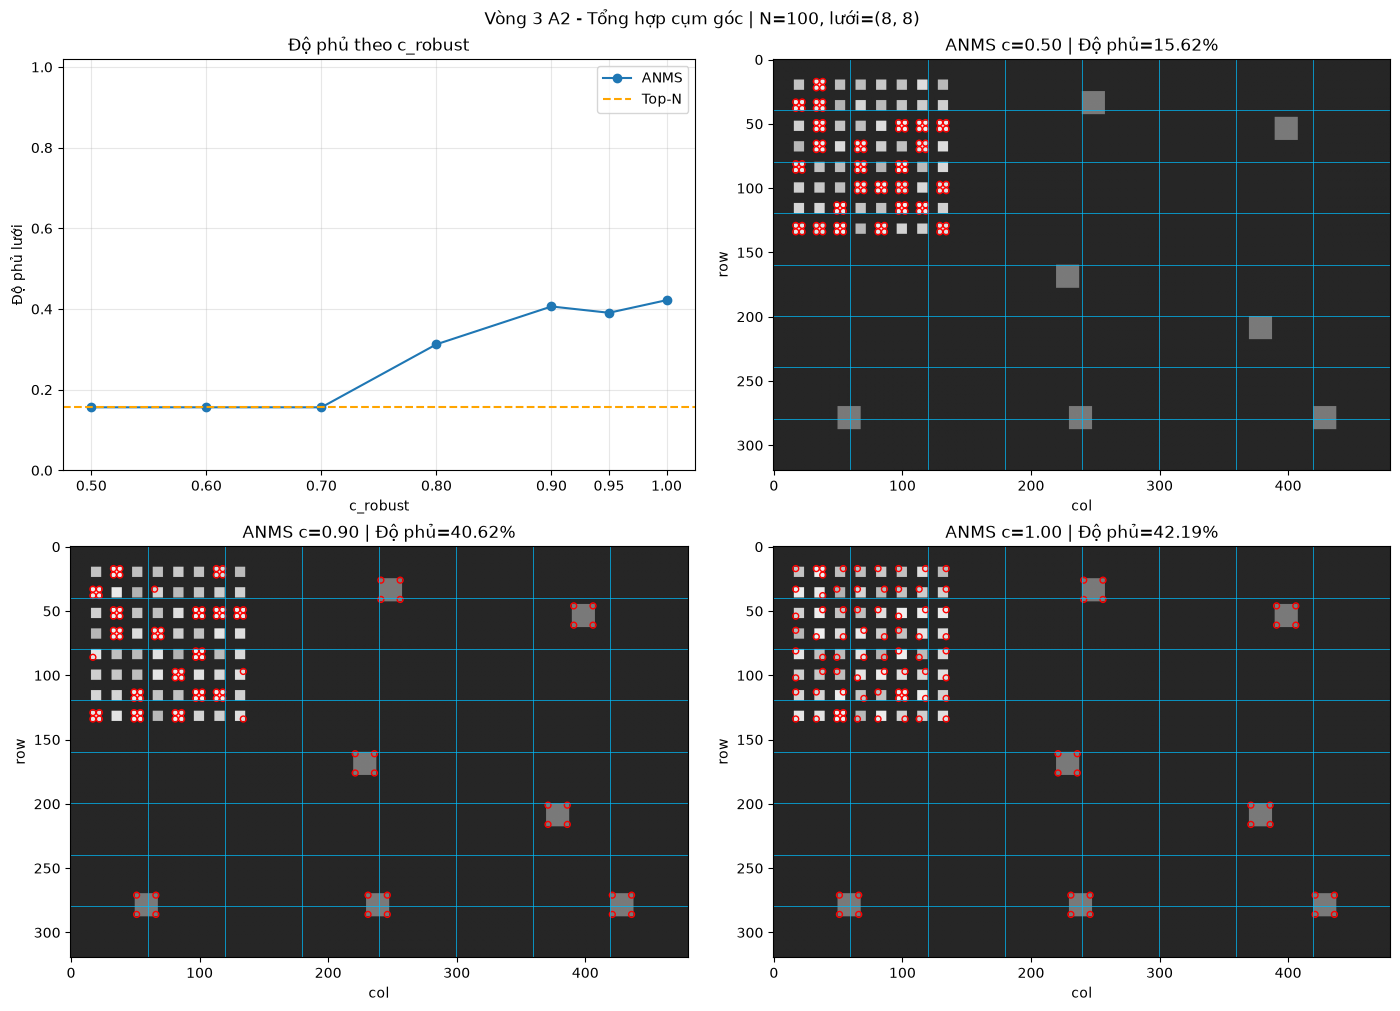


KẾT QUẢ: Tổng hợp cụm góc
Số ứng viên Harris: 284
N = 100, lưới = (8, 8)
c=0.50 | Top-N=0.1562 | ANMS=0.1562 | Chênh lệch=+0.00 điểm %
c=0.60 | Top-N=0.1562 | ANMS=0.1562 | Chênh lệch=+0.00 điểm %
c=0.70 | Top-N=0.1562 | ANMS=0.1562 | Chênh lệch=+0.00 điểm %
c=0.80 | Top-N=0.1562 | ANMS=0.3125 | Chênh lệch=+15.62 điểm %
c=0.90 | Top-N=0.1562 | ANMS=0.4062 | Chênh lệch=+25.00 điểm %
c=0.95 | Top-N=0.1562 | ANMS=0.3906 | Chênh lệch=+23.44 điểm %
c=1.00 | Top-N=0.1562 | ANMS=0.4219 | Chênh lệch=+26.56 điểm %


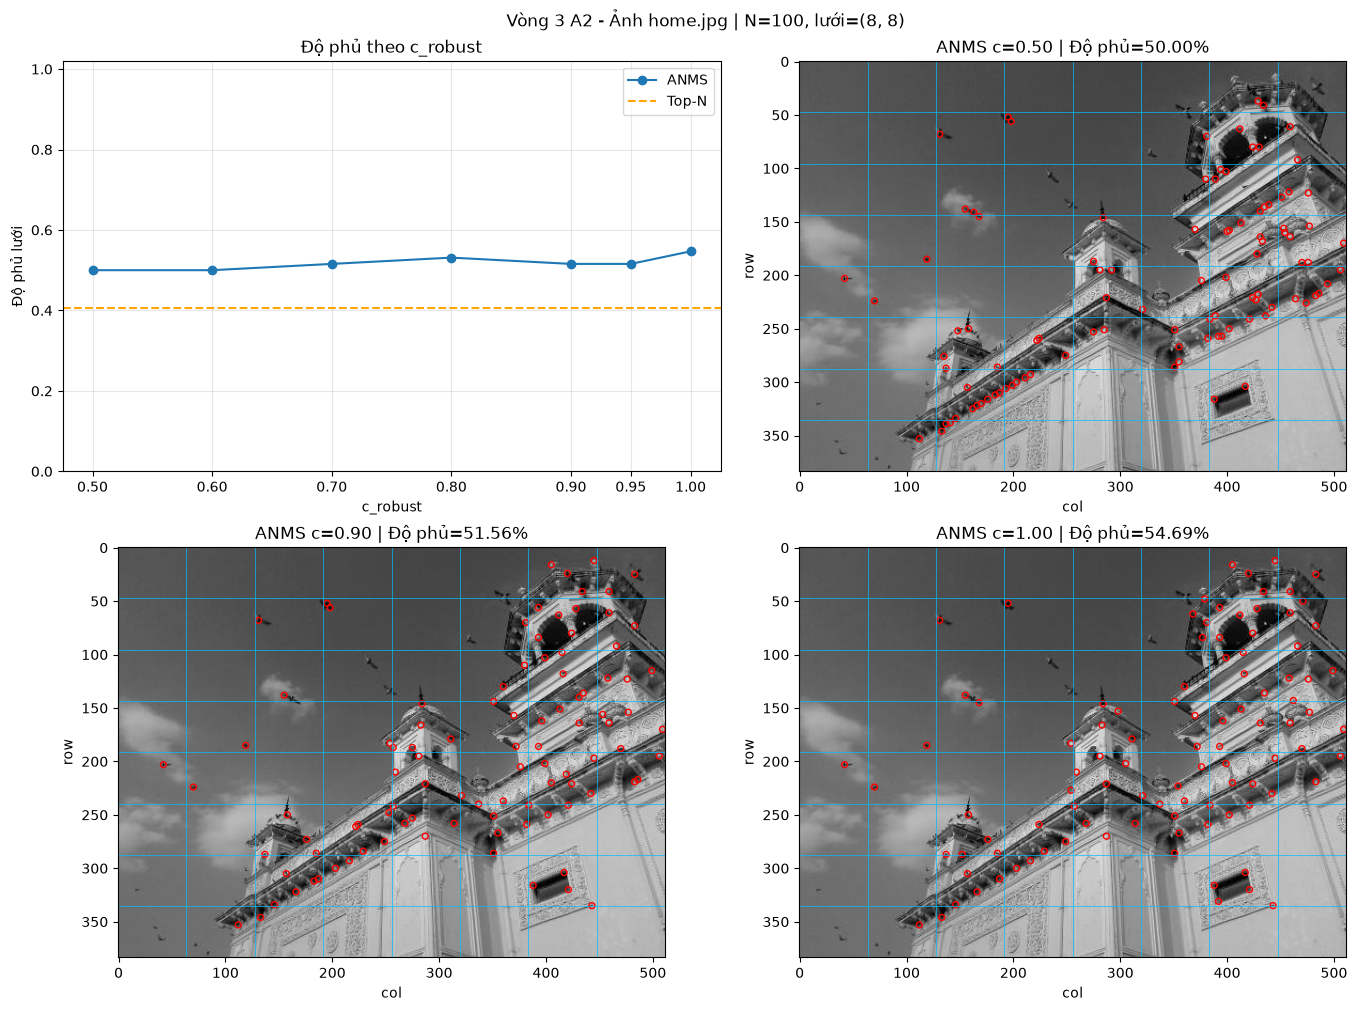


KẾT QUẢ: Ảnh home.jpg
Số ứng viên Harris: 332
N = 100, lưới = (8, 8)
c=0.50 | Top-N=0.4062 | ANMS=0.5000 | Chênh lệch=+9.38 điểm %
c=0.60 | Top-N=0.4062 | ANMS=0.5000 | Chênh lệch=+9.38 điểm %
c=0.70 | Top-N=0.4062 | ANMS=0.5156 | Chênh lệch=+10.94 điểm %
c=0.80 | Top-N=0.4062 | ANMS=0.5312 | Chênh lệch=+12.50 điểm %
c=0.90 | Top-N=0.4062 | ANMS=0.5156 | Chênh lệch=+10.94 điểm %
c=0.95 | Top-N=0.4062 | ANMS=0.5156 | Chênh lệch=+10.94 điểm %
c=1.00 | Top-N=0.4062 | ANMS=0.5469 | Chênh lệch=+14.06 điểm %

Tổng số cấu hình đã quét: 14


In [90]:

# =========================================================
# 3.1 - QUÉT c_robust VÀ SO SÁNH ĐỘ PHỦ ANMS / TOP-N
# =========================================================

LEN_C_VALUES = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 1.00]
len_sweep_c = []

# PR #37 chứa kết quả A5 đã được merge vào main.
# Vẫn cần thành viên phụ trách duyệt kết quả Vòng 3.
A5_MERGE_REF = "https://github.com/NguyenTanHiep07/xla-121036/pull/37"

len_a5_names = {row["image"] for row in len_a5_rows}

len_stage3_ready = (
    bool(len_a5_rows)
    and bool(len_candidates)
    and all(name in len_a5_names for name in len_candidates)
    and not len_missing(["anms", "top_n", "grid_occupancy"])
)

if not len_stage3_ready:
    print("CHƯA THỂ CHẠY VÒNG 3: cần hoàn thành các bước trước.")
else:
    print("Nguồn kiểm chứng A5:", A5_MERGE_REF)

    for name, points in len_candidates.items():

        if len(points) < 2:
            print(name, ": quá ít ứng viên Harris.")
            continue

        img = len_images[name]
        n = min(LEN_N, len(points))

        # Top-N và ANMS sử dụng cùng tập ứng viên và cùng N.
        top = len_check_selected(
            top_n(points.copy(), n), points, n
        )
        cov_top = len_measure_coverage(
            top, img.shape, LEN_GRID
        )

        selected_by_c = {}

        for c in LEN_C_VALUES:

            kept = len_check_selected(
                anms(points.copy(), n, c_robust=c),
                points, n
            )

            selected_by_c[c] = kept

            cov_anms = len_measure_coverage(
                kept, img.shape, LEN_GRID
            )

            len_sweep_c.append({
                "image": name,
                "n": n,
                "c": c,
                "top": cov_top,
                "anms": cov_anms
            })

        rows = [
            row for row in len_sweep_c
            if row["image"] == name
        ]

        # Biểu đồ và ba lưới điểm minh họa
        fig, axes = plt.subplots(
            2, 2, figsize=(14, 10),
            constrained_layout=True
        )

        ax = axes[0, 0]

        ax.plot(
            [row["c"] for row in rows],
            [row["anms"] for row in rows],
            "o-", label="ANMS"
        )

        ax.axhline(
            cov_top, color="orange",
            linestyle="--", label="Top-N"
        )

        ax.set_xlabel("c_robust")
        ax.set_ylabel("Độ phủ lưới")
        ax.set_title("Độ phủ theo c_robust")
        ax.set_xticks(LEN_C_VALUES)
        ax.set_ylim(0, 1.02)
        ax.grid(alpha=0.3)
        ax.legend()

        # Ba ảnh minh họa cho các giá trị c khác nhau.
        c_examples = [0.50, 0.90, 1.00]
        plot_axes = [axes[0, 1], axes[1, 0], axes[1, 1]]

        for ax, c in zip(plot_axes, c_examples):

            kept = selected_by_c[c]
            coverage = len_measure_coverage(
                kept, img.shape, LEN_GRID
            )

            len_plot_points(
                ax, img, kept, LEN_GRID,
                f"ANMS c={c:.2f} | Độ phủ={coverage:.2%}"
            )

        fig.suptitle(
            f"Vòng 3 A2 - {name} | N={n}, lưới={LEN_GRID}"
        )

        plt.show()

        print(f"\nKẾT QUẢ: {name}")
        print(f"Số ứng viên Harris: {len(points)}")
        print(f"N = {n}, lưới = {LEN_GRID}")

        for row in rows:
            diff = (row["anms"] - row["top"]) * 100
            print(
                f"c={row['c']:.2f} | "
                f"Top-N={row['top']:.4f} | "
                f"ANMS={row['anms']:.4f} | "
                f"Chênh lệch={diff:+.2f} điểm %"
            )

print("\nTổng số cấu hình đã quét:", len(len_sweep_c))



Tổng hợp cụm góc: 284 ứng viên, N = 100, lưới (8, 8)
  f_min / f_max = 0.0288
  c nhỏ nhất có số điểm r = ∞ < N: 0.71
  c nhỏ nhất mà ANMS chọn khác Top-N: 0.71
  c = 0.50: r = ∞ có  156 điểm | khác Top-N   0 điểm | độ phủ ANMS 0.1562 | Top-N 0.1562
  c = 0.70: r = ∞ có  100 điểm | khác Top-N   0 điểm | độ phủ ANMS 0.1562 | Top-N 0.1562
  c = 0.75: r = ∞ có   88 điểm | khác Top-N  12 điểm | độ phủ ANMS 0.1875 | Top-N 0.1562
  c = 0.80: r = ∞ có   80 điểm | khác Top-N  20 điểm | độ phủ ANMS 0.3125 | Top-N 0.1562
  c = 0.90: r = ∞ có   60 điểm | khác Top-N  33 điểm | độ phủ ANMS 0.4062 | Top-N 0.1562
  c = 1.00: r = ∞ có    1 điểm | khác Top-N  67 điểm | độ phủ ANMS 0.4219 | Top-N 0.1562


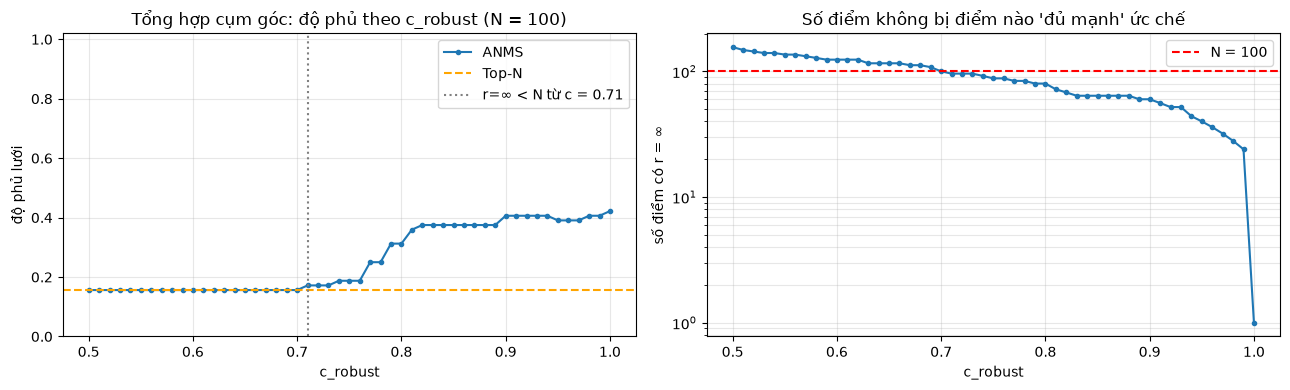


Ảnh home.jpg: 332 ứng viên, N = 100, lưới (8, 8)
  f_min / f_max = 0.0101
  c nhỏ nhất có số điểm r = ∞ < N: 0.5
  c nhỏ nhất mà ANMS chọn khác Top-N: 0.5
  c = 0.50: r = ∞ có    7 điểm | khác Top-N  35 điểm | độ phủ ANMS 0.5000 | Top-N 0.4062
  c = 0.70: r = ∞ có    3 điểm | khác Top-N  32 điểm | độ phủ ANMS 0.5156 | Top-N 0.4062
  c = 0.75: r = ∞ có    2 điểm | khác Top-N  32 điểm | độ phủ ANMS 0.5156 | Top-N 0.4062
  c = 0.80: r = ∞ có    2 điểm | khác Top-N  37 điểm | độ phủ ANMS 0.5312 | Top-N 0.4062
  c = 0.90: r = ∞ có    1 điểm | khác Top-N  40 điểm | độ phủ ANMS 0.5156 | Top-N 0.4062
  c = 1.00: r = ∞ có    1 điểm | khác Top-N  48 điểm | độ phủ ANMS 0.5469 | Top-N 0.4062


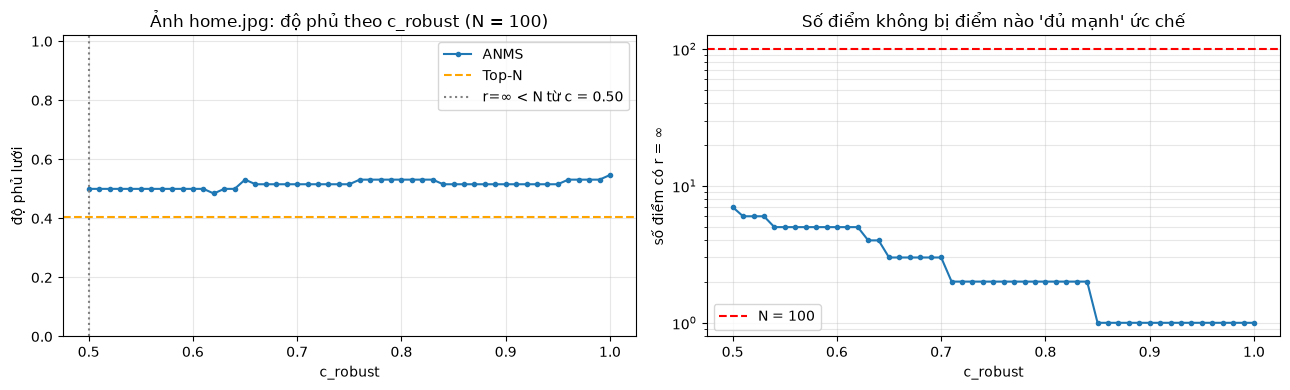

In [91]:
cac_c = np.round(np.arange(0.50, 1.0001, 0.01), 2)

for ten, diem in len_candidates.items():
    anh = len_images[ten]
    n = min(LEN_N, len(diem))
    f = diem[:, 2]
    f_max = f.max()

    diem_top = top_n(diem.copy(), n)
    phu_top = len_measure_coverage(diem_top, anh.shape, LEN_GRID)
    tap_top = {tuple(p) for p in diem_top}
    phu_anms, so_r_vo_cung, so_khac_top = [], [], []
    for c in cac_c:
        giu = len_check_selected(anms(diem.copy(), n, c_robust=c), diem, n)
        phu_anms.append(len_measure_coverage(giu, anh.shape, LEN_GRID))
        so_r_vo_cung.append(int(np.sum(f >= c * f_max)))
        so_khac_top.append(sum(tuple(p) not in tap_top for p in giu))
    phu_anms = np.array(phu_anms)
    so_r_vo_cung = np.array(so_r_vo_cung)

    duoi_N = cac_c[so_r_vo_cung < n]
    c_chuyen = float(duoi_N[0]) if len(duoi_N) else None
    tach_top = cac_c[np.array(so_khac_top) > 0]
    print(f"\n{ten}: {len(diem)} ứng viên, N = {n}, lưới {LEN_GRID}")
    print(f"  f_min / f_max = {f.min() / f_max:.4f}")
    print(f"  c nhỏ nhất có số điểm r = ∞ < N: {c_chuyen}")
    print(f"  c nhỏ nhất mà ANMS chọn khác Top-N: {float(tach_top[0]) if len(tach_top) else None}")
    for c in (0.50, 0.70, 0.75, 0.80, 0.90, 1.00):
        k = int(np.argmin(np.abs(cac_c - c)))
        print(f"  c = {c:.2f}: r = ∞ có {so_r_vo_cung[k]:4d} điểm | khác Top-N {so_khac_top[k]:3d} điểm | "
              f"độ phủ ANMS {phu_anms[k]:.4f} | Top-N {phu_top:.4f}")

    hinh, truc = plt.subplots(1, 2, figsize=(13, 4))
    truc[0].plot(cac_c, phu_anms, "o-", ms=3, label="ANMS")
    truc[0].axhline(phu_top, color="orange", ls="--", label="Top-N")
    if c_chuyen is not None:
        truc[0].axvline(c_chuyen, color="gray", ls=":", label=f"r=∞ < N từ c = {c_chuyen:.2f}")
    truc[0].set_xlabel("c_robust"); truc[0].set_ylabel("độ phủ lưới")
    truc[0].set_ylim(0, 1.02); truc[0].grid(alpha=0.3); truc[0].legend()
    truc[0].set_title(f"{ten}: độ phủ theo c_robust (N = {n})")
    truc[1].plot(cac_c, so_r_vo_cung, "o-", ms=3)
    truc[1].axhline(n, color="red", ls="--", label=f"N = {n}")
    truc[1].set_xlabel("c_robust"); truc[1].set_ylabel("số điểm có r = ∞")
    truc[1].set_yscale("log"); truc[1].grid(alpha=0.3, which="both"); truc[1].legend()
    truc[1].set_title("Số điểm không bị điểm nào 'đủ mạnh' ức chế")
    plt.tight_layout()
    plt.show()

**Nhận xét từ số liệu đã chạy:**



### Quét tham số

Ghi trục quét, giá trị thử và các điều kiện giữ cố định; trình bày đường cong hoặc điểm chuyển hành vi.

### 3.2 – Quét số điểm N với cùng c_robust

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Quét N hợp lệ trên cùng ứng viên và vẽ hai đường cong; ghi rõ các cấu hình không chạy.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482 
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.


Ảnh: Tổng hợp cụm góc
Các giá trị N hợp lệ: [25, 50, 75, 100, 150, 200]
Các giá trị N bỏ qua: []


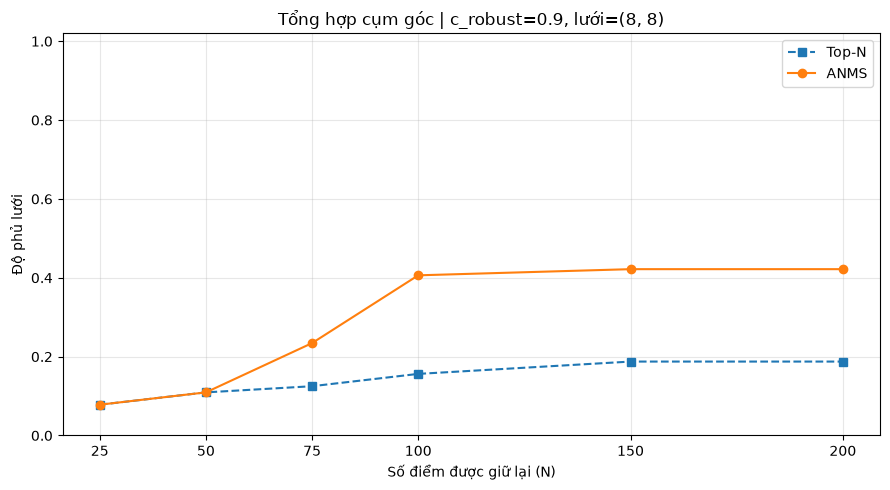


BẢNG KẾT QUẢ QUÉT N
N= 25 | Top-N=0.0781 | ANMS=0.0781 | Chênh lệch=+0.00 điểm %
N= 50 | Top-N=0.1094 | ANMS=0.1094 | Chênh lệch=+0.00 điểm %
N= 75 | Top-N=0.1250 | ANMS=0.2344 | Chênh lệch=+10.94 điểm %
N=100 | Top-N=0.1562 | ANMS=0.4062 | Chênh lệch=+25.00 điểm %
N=150 | Top-N=0.1875 | ANMS=0.4219 | Chênh lệch=+23.44 điểm %
N=200 | Top-N=0.1875 | ANMS=0.4219 | Chênh lệch=+23.44 điểm %

Ảnh: Ảnh home.jpg
Các giá trị N hợp lệ: [25, 50, 75, 100, 150, 200]
Các giá trị N bỏ qua: []


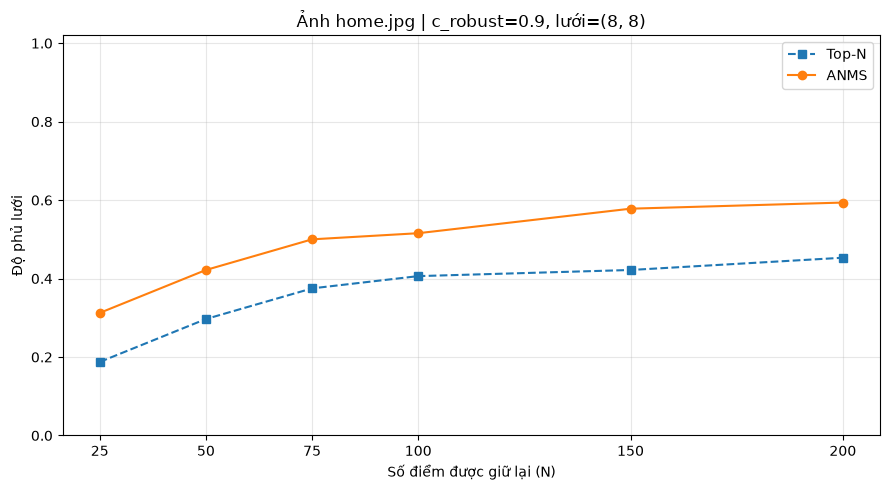


BẢNG KẾT QUẢ QUÉT N
N= 25 | Top-N=0.1875 | ANMS=0.3125 | Chênh lệch=+12.50 điểm %
N= 50 | Top-N=0.2969 | ANMS=0.4219 | Chênh lệch=+12.50 điểm %
N= 75 | Top-N=0.3750 | ANMS=0.5000 | Chênh lệch=+12.50 điểm %
N=100 | Top-N=0.4062 | ANMS=0.5156 | Chênh lệch=+10.94 điểm %
N=150 | Top-N=0.4219 | ANMS=0.5781 | Chênh lệch=+15.62 điểm %
N=200 | Top-N=0.4531 | ANMS=0.5938 | Chênh lệch=+14.06 điểm %

Tổng số cấu hình N: 12


In [92]:

# =========================================================
# 3.2 - QUÉT N VÀ SO SÁNH ĐỘ PHỦ TOP-N / ANMS
# =========================================================

LEN_N_VALUES = [25, 50, 75, 100, 150, 200]
len_sweep_n = []

if not len_stage3_ready:
    print("CHƯA CHẠY: điều kiện Vòng 3 chưa đầy đủ.")

else:
    for name, points in len_candidates.items():

        img = len_images[name]

        valid_n = [
            n for n in LEN_N_VALUES if n <= len(points)
        ]

        skipped_n = [
            n for n in LEN_N_VALUES if n > len(points)
        ]

        print(f"\nẢnh: {name}")
        print("Các giá trị N hợp lệ:", valid_n)
        print("Các giá trị N bỏ qua:", skipped_n)

        if len(valid_n) < 2:
            print("Không đủ giá trị N để vẽ đường cong.")
            continue

        for n in valid_n:

            # Cùng tập ứng viên, cùng N và cùng lưới.
            top = len_check_selected(
                top_n(points.copy(), n), points, n
            )

            kept = len_check_selected(
                anms(points.copy(), n, c_robust=LEN_C),
                points, n
            )

            cov_top = len_measure_coverage(
                top, img.shape, LEN_GRID
            )

            cov_anms = len_measure_coverage(
                kept, img.shape, LEN_GRID
            )

            len_sweep_n.append({
                "image": name,
                "n": n,
                "c": LEN_C,
                "top": cov_top,
                "anms": cov_anms
            })

        rows = [
            row for row in len_sweep_n
            if row["image"] == name
        ]

        # Vẽ đường cong độ phủ theo N
        plt.figure(figsize=(9, 5))

        plt.plot(
            [row["n"] for row in rows],
            [row["top"] for row in rows],
            "s--", label="Top-N"
        )

        plt.plot(
            [row["n"] for row in rows],
            [row["anms"] for row in rows],
            "o-", label="ANMS"
        )

        plt.xlabel("Số điểm được giữ lại (N)")
        plt.ylabel("Độ phủ lưới")
        plt.title(
            f"{name} | c_robust={LEN_C}, lưới={LEN_GRID}"
        )

        plt.xticks(valid_n)
        plt.ylim(0, 1.02)
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

        print("\nBẢNG KẾT QUẢ QUÉT N")

        for row in rows:

            diff = (row["anms"] - row["top"]) * 100

            print(
                f"N={row['n']:3d} | "
                f"Top-N={row['top']:.4f} | "
                f"ANMS={row['anms']:.4f} | "
                f"Chênh lệch={diff:+.2f} điểm %"
            )

print("\nTổng số cấu hình N:", len(len_sweep_n))


**Nhận xét từ số liệu đã chạy:**



### Giải thích kết quả

Điền kết quả đo, giải thích đại lượng nào thay đổi, ở bước nào và vì sao. Báo cả trường hợp chưa cải thiện.

### 3.3 – Nhận xét tự động từ số liệu thật

**Khai báo AI cho cell ngay bên dưới**

- Công cụ: ChatGPT / Codex (OpenAI).
- Mục đích: Tổng hợp đúng các số đo đã chạy, báo cả cấu hình không cải thiện và tránh kết luận dựng sẵn.
- Prompt nguyên văn:

```text
[https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb](https://github.com/NguyenTanHiep07/xla-121036/blob/main/bai_tap_2/lam_viec/bt2_len.ipynb) hãy đọc bảng phân công nhiệm vụ và truy cập vào đường link github thư mục bai_tap_2 vào notebook \_len.ipynb trình bày và xử lý các nhiệm vụ theo dealine trong bảng phân công nhiệm vụ của nhóm trưởng nhé " https://docs.google.com/spreadsheets/d/1e2I3BUvu4deds-AkxqQWeVKl5bR3ws8SKS0uhFMUpqs/edit?gid=989395482#gid=989395482  
```

- Phần hỗ trợ không chứa cài đặt `anms`, `top_n`, `grid_occupancy` hay Harris/SRG. Các số đo chỉ được sinh khi hàm thực tế đã có; thiếu hàm được báo là chưa thực hiện.
- Người thực hiện bổ sung các chỉnh sửa và kiểm tra do chính mình thực hiện trước khi nộp.

In [93]:

# =========================================================
# 3.3 - TỔNG HỢP VÀ NHẬN XÉT KẾT QUẢ VÒNG 3
# =========================================================

if not len_sweep_c and not len_sweep_n:
    print("CHƯA CÓ số liệu thực nghiệm Vòng 3.")

else:
    experiments = [
        (len_sweep_c, "QUÉT c_robust", "c"),
        (len_sweep_n, "QUÉT N", "n")
    ]

    for data, title, param in experiments:

        print("\n" + "=" * 55)
        print(title)
        print("=" * 55)

        image_names = sorted({
            row["image"] for row in data
        })

        for name in image_names:

            rows = [
                row for row in data
                if row["image"] == name
            ]

            diffs = np.array([
                row["anms"] - row["top"]
                for row in rows
            ])

            better = int(np.sum(diffs > 1e-12))
            equal = int(np.sum(np.abs(diffs) <= 1e-12))
            worse = int(np.sum(diffs < -1e-12))

            best = rows[int(np.argmax(diffs))]

            print(f"\nẢnh: {name}")
            print("Số cấu hình:", len(rows))

            print(
                "ANMS hơn / bằng / kém Top-N:",
                better, "/", equal, "/", worse
            )

            print(
                "Khoảng chênh lệch độ phủ:",
                f"{100 * diffs.min():+.2f} đến "
                f"{100 * diffs.max():+.2f} điểm %"
            )

            print(
                f"Chênh lệch cao nhất tại {param}="
                f"{best[param]}: "
                f"{100 * (best['anms'] - best['top']):+.2f} điểm %"
            )

            print(
                "Độ phủ ANMS đầu và cuối dải:",
                f"{rows[0]['anms']:.4f} -> "
                f"{rows[-1]['anms']:.4f}"
            )

    # Phân tích bằng bán kính ức chế r_i
    print("\n" + "=" * 55)
    print("GIẢI THÍCH THEO BÁN KÍNH ANMS")
    print("=" * 55)

    for name, points in len_candidates.items():

        if len(points) < 2:
            continue

        n = min(LEN_N, len(points))

        top = top_n(points.copy(), n)

        kept = anms(
            points.copy(), n, c_robust=LEN_C
        )

        top_set = {tuple(p) for p in top}

        # Điểm được ANMS giữ nhưng Top-N loại.
        selected_only_by_anms = [
            p for p in kept
            if tuple(p) not in top_set
        ]

        print(f"\nẢnh: {name}")
        print(
            "Số điểm ANMS chọn khác Top-N:",
            len(selected_only_by_anms)
        )

        if selected_only_by_anms:

            p = selected_only_by_anms[0]

            # Tính bán kính minh họa cho một điểm,
            # không thay đổi hàm cài đặt anms.
            stronger = points[
                p[2] < LEN_C * points[:, 2]
            ]

            if len(stronger):
                radius = np.min(
                    np.linalg.norm(
                        stronger[:, :2] - p[:2], axis=1
                    )
                )
            else:
                radius = np.inf

            print(
                f"Ví dụ điểm ANMS giữ: "
                f"row={p[0]:.0f}, col={p[1]:.0f}"
            )

            print(f"Response = {p[2]:.6g}")
            print(f"Bán kính r_i = {radius:.4f}")

    print("\nKẾT LUẬN CƠ CHẾ:")
    print(
        "Top-N ưu tiên các điểm có response Harris lớn."
    )
    print(
        "ANMS ưu tiên các điểm có bán kính ức chế r_i lớn."
    )
    print(
        "Điểm yếu nhưng nằm xa điểm đủ mạnh có thể "
        "được ANMS giữ lại."
    )
    print(
        "Sự khác biệt chọn điểm có thể làm thay đổi "
        "độ phủ lưới."
    )
    print(
        "Độ phủ cao không đồng nghĩa độ chính xác "
        "định vị góc cao hơn."
    )
    print(
        "Cần đối chiếu số liệu và được nhóm duyệt "
        "trước khi xác nhận hoàn thành Vòng 3."
    )



QUÉT c_robust

Ảnh: Tổng hợp cụm góc
Số cấu hình: 7
ANMS hơn / bằng / kém Top-N: 4 / 3 / 0
Khoảng chênh lệch độ phủ: +0.00 đến +26.56 điểm %
Chênh lệch cao nhất tại c=1.0: +26.56 điểm %
Độ phủ ANMS đầu và cuối dải: 0.1562 -> 0.4219

Ảnh: Ảnh home.jpg
Số cấu hình: 7
ANMS hơn / bằng / kém Top-N: 7 / 0 / 0
Khoảng chênh lệch độ phủ: +9.38 đến +14.06 điểm %
Chênh lệch cao nhất tại c=1.0: +14.06 điểm %
Độ phủ ANMS đầu và cuối dải: 0.5000 -> 0.5469

QUÉT N

Ảnh: Tổng hợp cụm góc
Số cấu hình: 6
ANMS hơn / bằng / kém Top-N: 4 / 2 / 0
Khoảng chênh lệch độ phủ: +0.00 đến +25.00 điểm %
Chênh lệch cao nhất tại n=100: +25.00 điểm %
Độ phủ ANMS đầu và cuối dải: 0.0781 -> 0.4219

Ảnh: Ảnh home.jpg
Số cấu hình: 6
ANMS hơn / bằng / kém Top-N: 6 / 0 / 0
Khoảng chênh lệch độ phủ: +10.94 đến +15.62 điểm %
Chênh lệch cao nhất tại n=150: +15.62 điểm %
Độ phủ ANMS đầu và cuối dải: 0.3125 -> 0.5938

GIẢI THÍCH THEO BÁN KÍNH ANMS

Ảnh: Tổng hợp cụm góc
Số điểm ANMS chọn khác Top-N: 33
Ví dụ điểm ANMS giữ: row=

**Nhận xét từ số liệu đã chạy:**



## Thí nghiệm B - SRG so với Region Growing

Sen so sánh hai phương pháp trên cùng ảnh xám `uneven_lighting.jpg` 480 × 640 và cùng hai hạt giống. Hai phép đo bổ sung dùng ảnh tổng hợp để tìm ngưỡng rò rỉ theo tương phản và so sánh độ nhạy với jitter.

Hiệp dùng ảnh dốc có biên thật và các bản thu nhỏ của ảnh thực để đo ảnh hưởng của `lazy`/`frozen` và quy tắc phá hòa. Phần này dùng bộ hạt giống riêng cho từng cấu hình.

### Thiết kế và bằng chứng khác biệt

Nêu ảnh nào, vì sao chọn, giữ cố định điều kiện gì và đo đại lượng nào. Trình bày kết quả của hai phương pháp.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng cell thí nghiệm so sánh Region Growing và Seeded Region Growing (SRG), sử dụng ảnh và hạt giống đã có trong notebook.
- Prompt nguyên văn: Hướng dẫn xây dựng thí nghiệm so sánh Region Growing và SRG trên cùng một ảnh, giữ cố định hạt giống và điều kiện đầu vào, tính số pixel được phân vùng và số pixel chưa được gán nhãn, đồng thời trực quan hóa kết quả để làm rõ sự khác biệt giữa hai phương pháp.
- Phần đã tự sửa và kiểm tra: Đối chiếu tên hàm, biến ảnh và hạt giống với notebook; kiểm tra kết quả chạy thực tế và hình ảnh đầu ra.

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

=== KẾT QUẢ SO SÁNH ===
Ảnh đầu vào: (480, 640)
Ngưỡng T: 15
Số hạt giống: 2

Region Growing:
Pixel đã gán nhãn: 118553
Pixel chưa gán nhãn: 188647
Số pixel mỗi vùng: {0: 56298, 1: 62255}

SRG:
Pixel đã gán nhãn: 307200
Pixel chưa gán nhãn: 0
Số pixel mỗi vùng: {0: 120309, 1: 186891}
Pixel biên: 1045

Số pixel khác nhãn trên vùng chung: 2


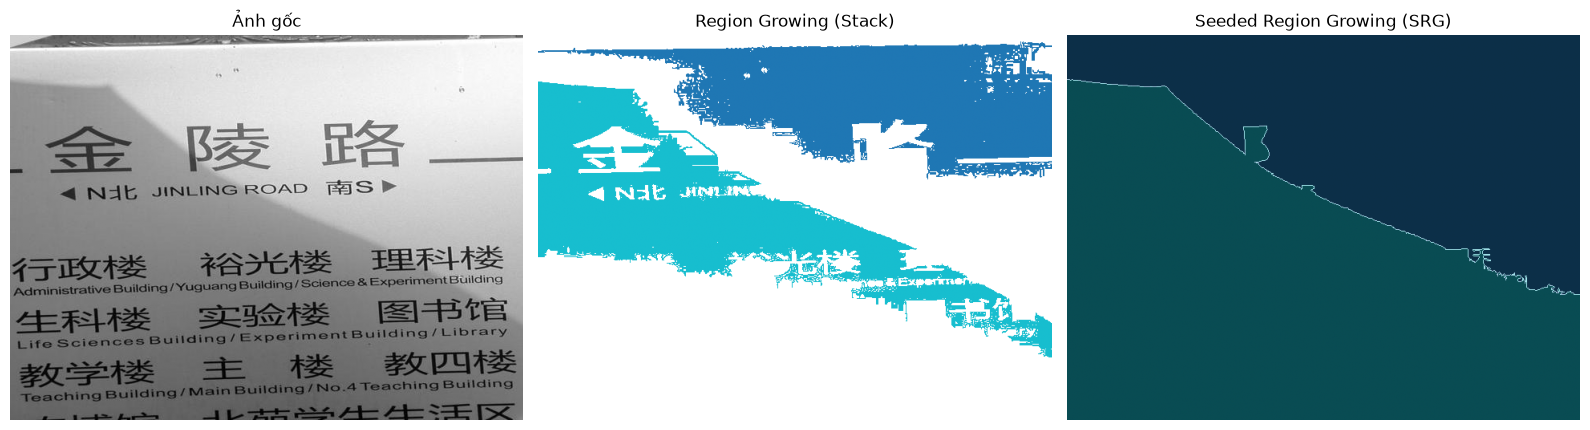

In [94]:
# So sánh Region Growing cổ điển và SRG trên cùng dữ liệu

labels_classic = region_growing_classic(
    test_img,
    test_seeds,
    T=T_test,
    order="stack"
)

labels_srg, boundary_mask = srg(
    test_img,
    test_seeds,
    connectivity=4,
    stale="lazy",
    tie="insertion"
)

# Thống kê số pixel được phân vùng
classic_assigned = np.count_nonzero(labels_classic >= 0)
srg_assigned = np.count_nonzero(labels_srg >= 0)

classic_unassigned = np.count_nonzero(labels_classic < 0)
srg_unassigned = np.count_nonzero(labels_srg < 0)

print("=== KẾT QUẢ SO SÁNH ===")
print("Ảnh đầu vào:", test_img.shape)
print("Ngưỡng T:", T_test)
print("Số hạt giống:", len(test_seeds))

print("\nRegion Growing:")
print("Pixel đã gán nhãn:", classic_assigned)
print("Pixel chưa gán nhãn:", classic_unassigned)
print("Số pixel mỗi vùng:",
      {int(k): int(np.sum(labels_classic == k))
       for k in np.unique(labels_classic) if k >= 0})

print("\nSRG:")
print("Pixel đã gán nhãn:", srg_assigned)
print("Pixel chưa gán nhãn:", srg_unassigned)
print("Số pixel mỗi vùng:",
      {int(k): int(np.sum(labels_srg == k))
       for k in np.unique(labels_srg)})
print("Pixel biên:", np.count_nonzero(boundary_mask))

# So sánh nhãn trên những pixel Region Growing đã phân vùng
common_mask = labels_classic >= 0
different_pixels = np.count_nonzero(
    labels_classic[common_mask] != labels_srg[common_mask]
)

print("\nSố pixel khác nhãn trên vùng chung:", different_pixels)

# Hiển thị kết quả
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(test_img, cmap="gray")
axes[0].set_title("Ảnh gốc")

axes[1].imshow(
    np.ma.masked_less(labels_classic, 0),
    cmap="tab10",
    vmin=0,
    vmax=len(test_seeds) - 1
)
axes[1].set_title("Region Growing (Stack)")

axes[2].imshow(
    labels_srg,
    cmap="tab10",
    vmin=0,
    vmax=len(test_seeds) - 1
)
axes[2].imshow(
    boundary_mask,
    cmap="gray",
    alpha=0.6
)
axes[2].set_title("Seeded Region Growing (SRG)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Nhận xét từ số liệu đã chạy:**
Trên cùng ảnh đầu vào và cùng hai hạt giống, Region Growing cổ điển chỉ gán nhãn được 118.553 pixel, còn 188.647 pixel chưa được phân vùng. Ngược lại, SRG gán nhãn toàn bộ 307.200 pixel và xác định 1.045 pixel biên. Kết quả cho thấy SRG có khả năng phân hoạch toàn bộ ảnh tốt hơn trong thí nghiệm này, trong khi Region Growing cổ điển còn để lại nhiều pixel chưa được gán nhãn.

### Quét tham số

Ghi trục quét, giá trị thử và các điều kiện giữ cố định; trình bày đường cong hoặc điểm chuyển hành vi.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng thí nghiệm quét ngưỡng T cho Region Growing cổ điển, thống kê số vùng, diện tích vùng lớn nhất và trực quan hóa kết quả.
- Prompt nguyên văn: Hãy hỗ trợ xây dựng cell thí nghiệm quét tham số T cho bài toán Region Growing cổ điển. Sử dụng hàm region_growing_classic đã được cài đặt sẵn, ảnh test_img và test_seeds có trong notebook. Với nhiều giá trị T, hãy thống kê số vùng thực tế, số pixel đã gán nhãn, tỷ lệ pixel đã gán nhãn và diện tích vùng lớn nhất. Vẽ biểu đồ thể hiện sự thay đổi của các đại lượng theo T. Không viết lại hoặc chỉnh sửa hàm cài đặt thuật toán.
- Phần đã tự sửa và kiểm tra: Kiểm tra tên biến, phạm vi T, kết quả thống kê và biểu đồ sau khi chạy.

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

In [95]:
# Quét ngưỡng T cho Region Growing cổ điển

T_values = [5, 10, 15, 20, 25, 30, 40, 50, 60]

scan_results = []

for T_value in T_values:
    labels = region_growing_classic(
        test_img,
        test_seeds,
        T=T_value,
        order="stack"
    )

    valid_pixels = labels >= 0
    assigned_count = int(np.count_nonzero(valid_pixels))
    total_pixels = labels.size

    unique_labels, counts = np.unique(
        labels[valid_pixels],
        return_counts=True
    )

    num_regions = len(unique_labels)
    largest_region = int(counts.max()) if len(counts) > 0 else 0
    assigned_ratio = assigned_count / total_pixels * 100

    scan_results.append({
        "T": T_value,
        "regions": num_regions,
        "assigned": assigned_count,
        "ratio": assigned_ratio,
        "largest": largest_region
    })

    print(
        f"T={T_value:2d} | "
        f"Số vùng={num_regions} | "
        f"Pixel đã gán={assigned_count} | "
        f"Tỷ lệ={assigned_ratio:.2f}% | "
        f"Vùng lớn nhất={largest_region}"
    )

print("\nHoàn thành quét tham số.")

T= 5 | Số vùng=2 | Pixel đã gán=24370 | Tỷ lệ=7.93% | Vùng lớn nhất=18010
T=10 | Số vùng=2 | Pixel đã gán=79172 | Tỷ lệ=25.77% | Vùng lớn nhất=39822
T=15 | Số vùng=2 | Pixel đã gán=118553 | Tỷ lệ=38.59% | Vùng lớn nhất=62255
T=20 | Số vùng=2 | Pixel đã gán=176365 | Tỷ lệ=57.41% | Vùng lớn nhất=104588
T=25 | Số vùng=2 | Pixel đã gán=212464 | Tỷ lệ=69.16% | Vùng lớn nhất=128434
T=30 | Số vùng=2 | Pixel đã gán=236324 | Tỷ lệ=76.93% | Vùng lớn nhất=142890
T=40 | Số vùng=2 | Pixel đã gán=254287 | Tỷ lệ=82.78% | Vùng lớn nhất=153724
T=50 | Số vùng=2 | Pixel đã gán=263041 | Tỷ lệ=85.63% | Vùng lớn nhất=156041
T=60 | Số vùng=2 | Pixel đã gán=266007 | Tỷ lệ=86.59% | Vùng lớn nhất=136757

Hoàn thành quét tham số.


**Nhận xét từ số liệu đã chạy:**
Kết quả quét tham số cho thấy khi ngưỡng T tăng từ 5 lên 60, số pixel được gán nhãn tăng từ 24.370 lên 266.007 pixel, tương ứng tỷ lệ bao phủ tăng từ 7,93% lên 86,59%.
Số vùng luôn bằng 2 trong tất cả các lần thử nghiệm, tương ứng với 2 hạt giống ban đầu. Diện tích vùng lớn nhất tăng đáng kể khi T tăng từ 5 đến 50, sau đó giảm ở T = 60. Điều này cho thấy ngưỡng T ảnh hưởng rõ rệt đến khả năng phát triển và sự phân bố pixel giữa các vùng.

### Giải thích kết quả
Điền kết quả đo, giải thích đại lượng nào thay đổi, ở bước nào và vì sao. Báo cả trường hợp chưa cải thiện.

Khi tăng ngưỡng T từ 5 lên 60, số pixel được gán nhãn tăng từ 24.370 lên 266.007 pixel. Nguyên nhân là ngưỡng T càng lớn thì điều kiện chấp nhận pixel càng dễ thỏa mãn, giúp vùng phát triển và tiếp nhận thêm nhiều pixel lân cận.

Số vùng vẫn giữ nguyên là 2 vì thuật toán sử dụng 2 hạt giống ban đầu. Diện tích vùng lớn nhất tăng từ 18.010 pixel tại T = 5 lên 156.041 pixel tại T = 50, nhưng giảm còn 136.757 pixel tại T = 60. Điều này cho thấy khi ngưỡng thay đổi, pixel có thể được phân bố lại giữa hai vùng.

Ở ngưỡng thấp, nhiều pixel chưa được gán nhãn do điều kiện phát triển nghiêm ngặt. Khi tăng ngưỡng, các vùng mở rộng mạnh hơn, nhưng cũng có nguy cơ phát triển vượt khỏi khu vực mong muốn và gây hiện tượng rò rỉ vùng.

Kết luận: Ngưỡng T ảnh hưởng trực tiếp đến số pixel được phân vùng và kích thước các vùng. Vì vậy, cần lựa chọn T phù hợp để cân bằng giữa khả năng bao phủ và hạn chế rò rỉ vùng.

**Khai báo cho cell thí nghiệm bên dưới (chỉ giữ nếu thực tế có dùng AI).**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng biểu đồ trực quan từ kết quả quét tham số T của Region Growing cổ điển.
- Prompt nguyên văn: Dựa trên biến scan_results đã có trong notebook, hãy viết cell Python sử dụng NumPy và Matplotlib để vẽ biểu đồ số vùng, tỷ lệ pixel được gán nhãn và kích thước vùng lớn nhất theo ngưỡng T. Không chạy lại thuật toán phân vùng.
- Phần đã tự sửa và kiểm tra: Đối chiếu tên các trường dữ liệu với cell quét tham số và kiểm tra biểu đồ sau khi chạy.

Nếu tự viết hoàn toàn, xóa cell mẫu này. Không dùng mẫu này để khai báo cho các cell cài đặt.

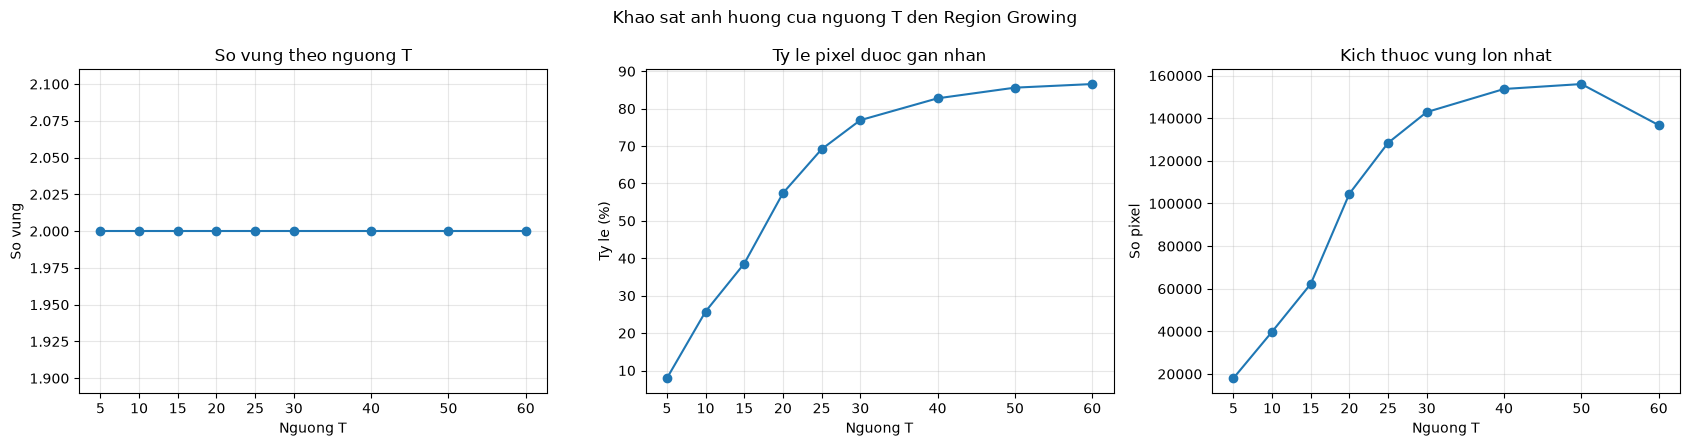

In [96]:
# Biểu đồ kết quả quét tham số T của Region Growing

T_plot = [item["T"] for item in scan_results]
regions_plot = [item["regions"] for item in scan_results]
ratio_plot = [item["ratio"] for item in scan_results]
largest_plot = [item["largest"] for item in scan_results]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Số vùng theo T
axes[0].plot(T_plot, regions_plot, marker="o")
axes[0].set_title("So vung theo nguong T")
axes[0].set_xlabel("Nguong T")
axes[0].set_ylabel("So vung")
axes[0].set_xticks(T_plot)
axes[0].grid(True, alpha=0.3)

# 2. Ty le pixel duoc gan nhan
axes[1].plot(T_plot, ratio_plot, marker="o")
axes[1].set_title("Ty le pixel duoc gan nhan")
axes[1].set_xlabel("Nguong T")
axes[1].set_ylabel("Ty le (%)")
axes[1].set_xticks(T_plot)
axes[1].grid(True, alpha=0.3)

# 3. Kich thuoc vung lon nhat
axes[2].plot(T_plot, largest_plot, marker="o")
axes[2].set_title("Kich thuoc vung lon nhat")
axes[2].set_xlabel("Nguong T")
axes[2].set_ylabel("So pixel")
axes[2].set_xticks(T_plot)
axes[2].grid(True, alpha=0.3)

plt.suptitle("Khao sat anh huong cua nguong T den Region Growing")
plt.tight_layout()
plt.show()

In [97]:
print("T_plot:", T_plot)
print("regions_plot:", regions_plot)
print("ratio_plot:", ratio_plot)
print("largest_plot:", largest_plot)

T_plot: [5, 10, 15, 20, 25, 30, 40, 50, 60]
regions_plot: [2, 2, 2, 2, 2, 2, 2, 2, 2]
ratio_plot: [7.932942708333333, 25.772135416666668, 38.591471354166664, 57.410481770833336, 69.16145833333334, 76.92838541666667, 82.77571614583333, 85.62532552083333, 86.5908203125]
largest_plot: [18010, 39822, 62255, 104588, 128434, 142890, 153724, 156041, 136757]


**Nhận xét từ số liệu đã chạy:**
Kết quả cho thấy khi tăng ngưỡng T từ 5 lên 60, số pixel được gán nhãn tăng từ 24.370 lên 266.007 pixel, tương ứng tỷ lệ bao phủ tăng từ 7,93% lên 86,59%. Số vùng luôn duy trì ở mức 2 do sử dụng hai hạt giống.

Kích thước vùng lớn nhất tăng từ 18.010 pixel tại T = 5 lên 156.041 pixel tại T = 50, sau đó giảm còn 136.757 pixel tại T = 60. Điều này cho thấy khi tăng T, điều kiện tiếp nhận pixel trở nên ít nghiêm ngặt hơn, khiến các vùng phát triển và có thể làm thay đổi sự phân bố pixel giữa hai vùng.

Đặc biệt, khoảng T = 15 đến T = 25 có sự gia tăng mạnh về số pixel được gán nhãn. Đây là khoảng cần chú ý khi đánh giá nguy cơ vùng phát triển vượt khỏi khu vực mong muốn. T = 60 cũng cho thấy kích thước vùng lớn nhất giảm, chứng tỏ pixel được phân bố lại giữa hai vùng.

Kết luận: Ngưỡng T ảnh hưởng đáng kể đến mức độ bao phủ và kích thước vùng của Region Growing. Cần lựa chọn ngưỡng phù hợp để cân bằng giữa khả năng phân vùng và nguy cơ rò rỉ vùng.


## Thí nghiệm độ nhạy hạt giống (Seed Sensitivity)

Đánh giá mức độ thay đổi kết quả phân vùng khi vị trí các hạt giống bị dịch chuyển. Thực hiện trên cùng ảnh đầu vào và cùng bộ hạt giống ban đầu để so sánh Region Growing cổ điển với Seeded Region Growing (SRG).

**Khai báo cho cell thí nghiệm**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ xây dựng thí nghiệm đánh giá độ nhạy hạt giống, so sánh Region Growing cổ điển và SRG.
- Prompt nguyên văn: Hãy hướng dẫn xây dựng thí nghiệm sử dụng hàm seed_sensitivity có sẵn để so sánh độ nhạy hạt giống của Region Growing cổ điển và SRG trên cùng ảnh, cùng bộ seed ban đầu. Tạo bản đồ độ nhạy và biểu diễn kết quả bằng hình ảnh.
- Phần đã tự sửa và kiểm tra: Đối chiếu cách gọi hai thuật toán với chữ ký hàm đã được nhóm cài đặt.

In [98]:
# Hàm trung gian cho Region Growing cổ điển
def run_classic_for_sensitivity(img, seeds):
    return region_growing_classic(
        img,
        seeds,
        T=T_test,
        order="stack"
    )


# Hàm trung gian cho SRG
def run_srg_for_sensitivity(img, seeds):
    labels, boundary_mask = srg(
        img,
        seeds,
        connectivity=4,
        stale="lazy",
        tie="insertion"
    )
    return labels


# Tính bản đồ độ nhạy cho hai phương pháp
sensitivity_classic = seed_sensitivity(
    test_img,
    test_seeds,
    run_classic_for_sensitivity,
    n_trials=20,
    jitter=3
)

sensitivity_srg = seed_sensitivity(
    test_img,
    test_seeds,
    run_srg_for_sensitivity,
    n_trials=20,
    jitter=3
)

print("Kích thước bản đồ Region Growing:", sensitivity_classic.shape)
print("Kích thước bản đồ SRG:", sensitivity_srg.shape)

print("Độ nhạy trung bình Region Growing:",
      np.mean(sensitivity_classic))

print("Độ nhạy trung bình SRG:",
      np.mean(sensitivity_srg))

Kích thước bản đồ Region Growing: (480, 640)
Kích thước bản đồ SRG: (480, 640)
Độ nhạy trung bình Region Growing: 0.014135905
Độ nhạy trung bình SRG: 0.05989242


In [99]:
# Kiểm tra SRG khi thay đổi vị trí hạt giống

baseline_srg = srg(
    test_img,
    test_seeds,
    connectivity=4,
    stale="lazy",
    tie="insertion"
)[0]

changed_seeds = np.asarray(test_seeds, dtype=np.int32).copy()

# Dịch chuyển hạt giống để kiểm tra
changed_seeds[0, 0] += 3
changed_seeds[1, 0] -= 3

changed_srg = srg(
    test_img,
    changed_seeds.tolist(),
    connectivity=4,
    stale="lazy",
    tie="insertion"
)[0]

print("Hạt giống ban đầu:", test_seeds)
print("Hạt giống sau thay đổi:", changed_seeds.tolist())

print(
    "Số pixel thay đổi nhãn:",
    np.count_nonzero(baseline_srg != changed_srg)
)

Hạt giống ban đầu: [(50, 360), (120, 120)]
Hạt giống sau thay đổi: [[53, 360], [117, 120]]
Số pixel thay đổi nhãn: 0


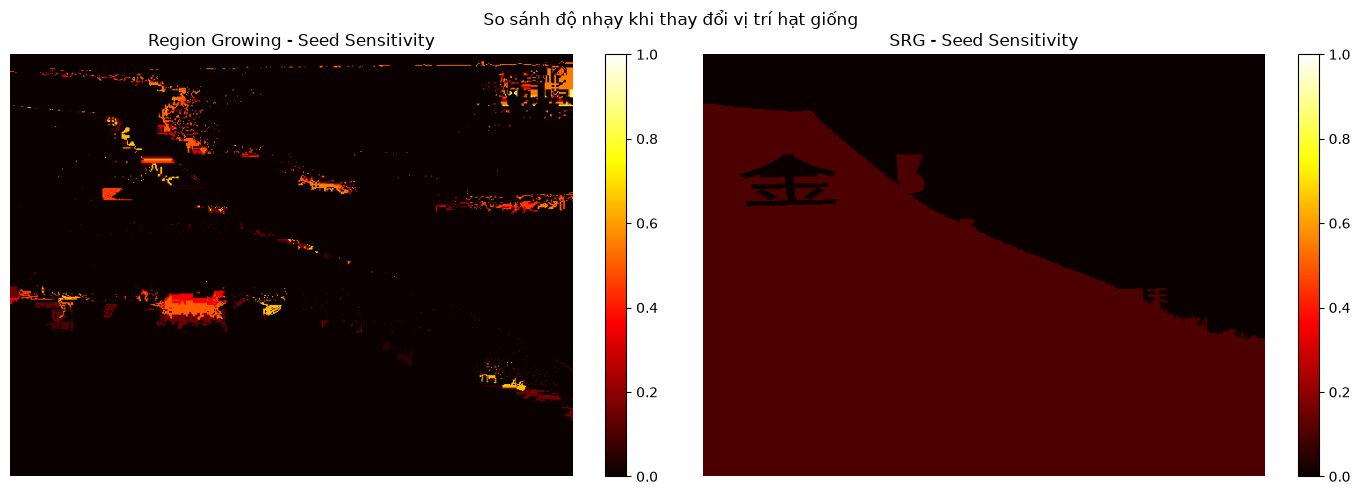

In [100]:
# Hiển thị bản đồ độ nhạy của hai phương pháp

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

im1 = axes[0].imshow(
    sensitivity_classic,
    cmap="hot",
    vmin=0,
    vmax=1
)
axes[0].set_title("Region Growing - Seed Sensitivity")
axes[0].axis("off")
fig.colorbar(im1, ax=axes[0], fraction=0.046)

im2 = axes[1].imshow(
    sensitivity_srg,
    cmap="hot",
    vmin=0,
    vmax=1
)
axes[1].set_title("SRG - Seed Sensitivity")
axes[1].axis("off")
fig.colorbar(im2, ax=axes[1], fraction=0.046)

plt.suptitle("So sánh độ nhạy khi thay đổi vị trí hạt giống")
plt.tight_layout()
plt.show()

In [101]:
for ten, do_nhay_hat_giong in (("Region Growing", sensitivity_classic), ("SRG", sensitivity_srg)):
    so_pixel_doi = np.count_nonzero(do_nhay_hat_giong)
    print(f"{ten}: trung bình {do_nhay_hat_giong.mean():.5f}, lớn nhất {do_nhay_hat_giong.max():.3f}, "
          f"{so_pixel_doi} pixel đổi nhãn ({so_pixel_doi / do_nhay_hat_giong.size:.2%}).")

Region Growing: trung bình 0.01414, lớn nhất 0.850, 11757 pixel đổi nhãn (3.83%).
SRG: trung bình 0.05989, lớn nhất 0.100, 183991 pixel đổi nhãn (59.89%).


**Nhận xét kết quả độ nhạy hạt giống**

Thí nghiệm dùng 20 lần thử với jitter tối đa 3 pixel trên cùng ảnh và bộ hạt giống. Một pixel được đếm nếu nó đổi nhãn ít nhất một lần so với kết quả ban đầu. Tỉ lệ trong bảng lấy số pixel đó chia cho toàn bộ số pixel của ảnh.

Hàm `seed_sensitivity` lấy mẫu ngẫu nhiên mỗi lần chạy. Bảng phía trên ghi số đo của lần chạy hiện tại, trên đúng ảnh và bộ hạt giống này.

**Khai báo AI cho cell thí nghiệm**

- Công cụ: ChatGPT (OpenAI).
- Mục đích: Hỗ trợ trực quan hóa kết quả Region Growing khi thay đổi ngưỡng T để quan sát hiện tượng rò rỉ vùng.
- Prompt nguyên văn: "Hãy hỗ trợ xây dựng cell thí nghiệm Python để trực quan hóa kết quả phân vùng Region Growing cổ điển trên cùng một ảnh với nhiều giá trị ngưỡng T, sử dụng hàm region_growing_classic đã có, không viết lại thuật toán cài đặt."
- Phần đã tự sửa và kiểm tra: Kiểm tra các biến đầu vào, đối chiếu kết quả hiển thị với số liệu quét tham số T.

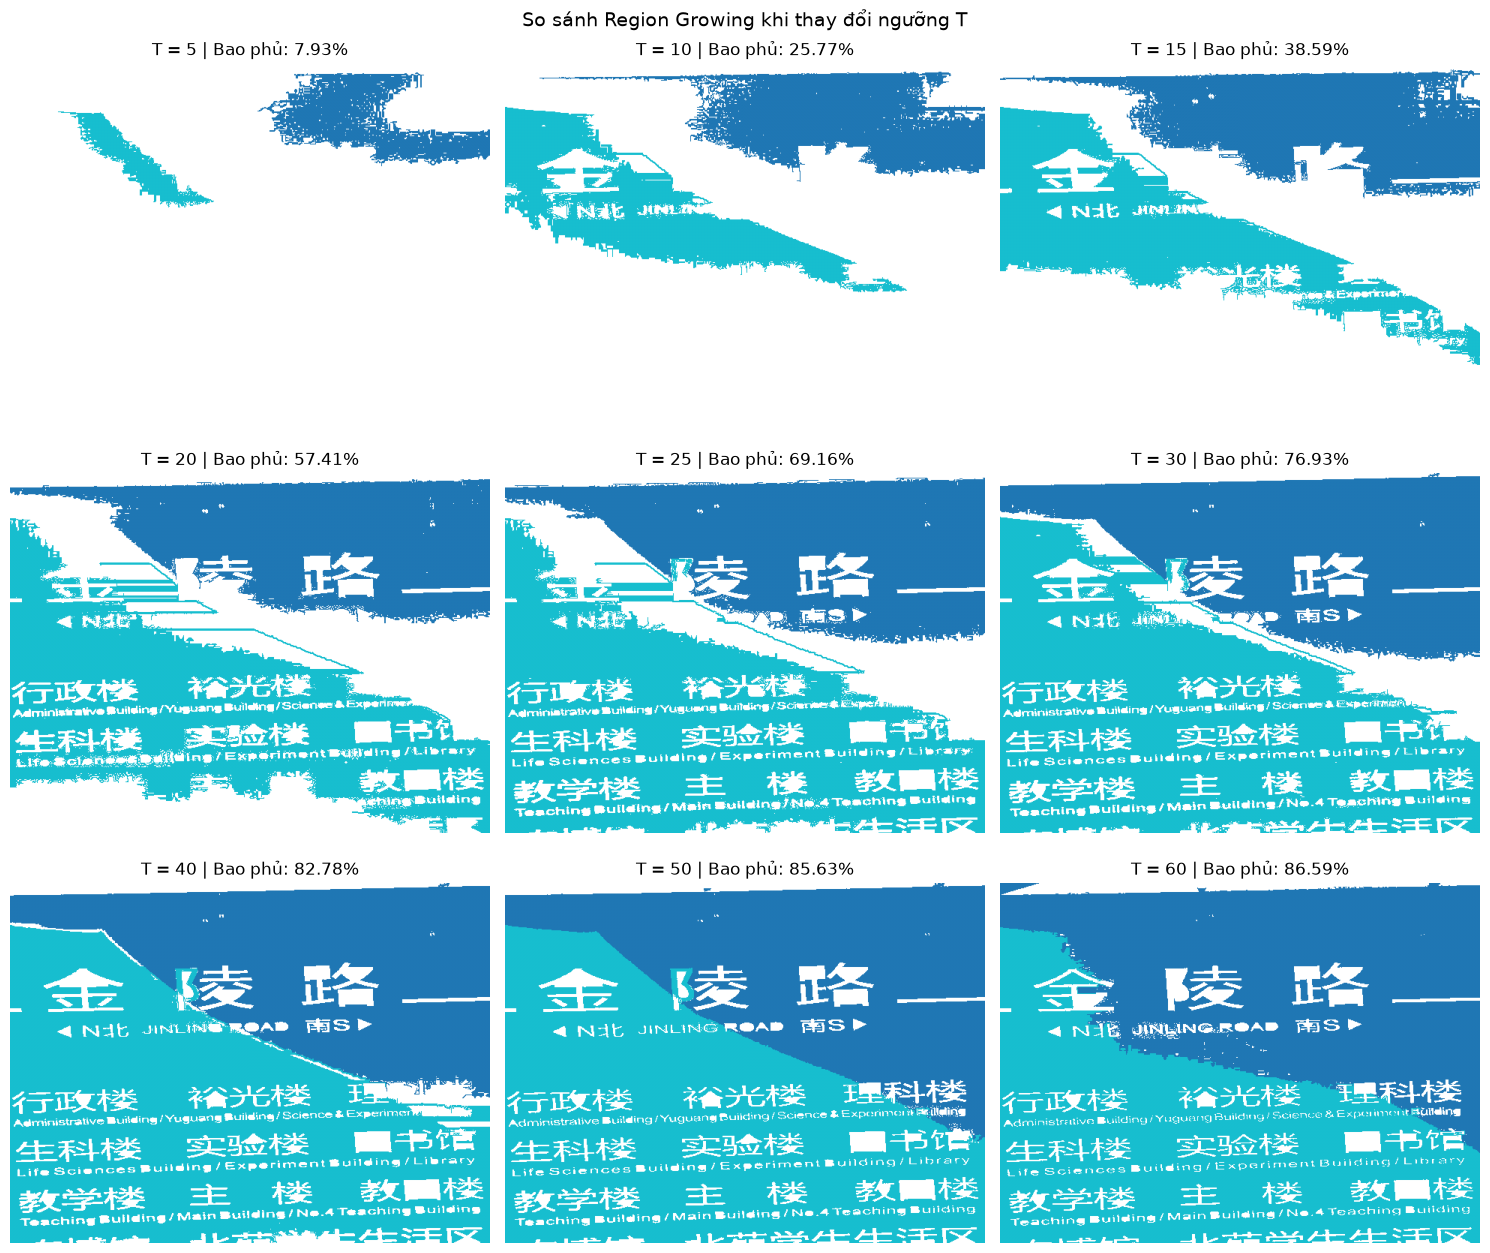

In [102]:
# Trực quan hóa kết quả Region Growing với các ngưỡng T khác nhau

T_visual = [5, 10, 15, 20, 25, 30, 40, 50, 60]

fig, axes = plt.subplots(3, 3, figsize=(15, 13))

for ax, T_value in zip(axes.flat, T_visual):
    labels = region_growing_classic(
        test_img,
        test_seeds,
        T=T_value,
        order="stack"
    )

    display_labels = np.ma.masked_less(labels, 0)

    cmap = plt.get_cmap("tab10").copy()
    cmap.set_bad("white")

    ax.imshow(display_labels, cmap=cmap,
              vmin=0, vmax=max(len(test_seeds) - 1, 1))

    assigned = np.count_nonzero(labels >= 0)
    ratio = assigned / labels.size * 100

    ax.set_title(f"T = {T_value} | Bao phủ: {ratio:.2f}%")
    ax.axis("off")

plt.suptitle(
    "So sánh Region Growing khi thay đổi ngưỡng T",
    fontsize=14
)
plt.tight_layout()
plt.show()

**Nhận xét kết quả trực quan khi thay đổi ngưỡng T**

Qua 9 kết quả trực quan, có thể thấy ngưỡng T ảnh hưởng rõ rệt đến quá trình phát triển của các vùng trong thuật toán Region Growing.

Ở T = 5, tỷ lệ pixel được gán nhãn chỉ đạt 7,93%, cho thấy điều kiện phát triển còn nghiêm ngặt và nhiều pixel chưa được phân vùng. Khi tăng T từ 10 đến 30, các vùng phát triển nhanh hơn, tỷ lệ bao phủ tăng từ 25,77% lên 76,93%.

Tại T = 40 đến 60, tỷ lệ bao phủ tăng chậm hơn, từ 82,78% lên 86,59%. Điều này cho thấy quá trình phát triển vùng dần chậm lại khi các pixel thỏa mãn điều kiện đã được tiếp nhận phần lớn.

Về hiện tượng rò rỉ, các hình cho thấy vùng phân đoạn tiếp tục mở rộng khi tăng T. Tuy nhiên, cần đối chiếu với ảnh gốc để xác định chính xác vùng có lan sang khu vực không mong muốn hay không.

Kết luận: T quá thấp khiến nhiều pixel chưa được gán nhãn, trong khi T cao giúp tăng độ bao phủ nhưng cần kiểm soát nguy cơ phân vùng vượt khỏi khu vực mong muốn. Việc lựa chọn T cần cân bằng giữa độ bao phủ và tính chính xác của vùng phân đoạn.


**Nhận xét hiện tượng phát triển và nguy cơ rò rỉ vùng**

Qua kết quả thực nghiệm, khi tăng ngưỡng T từ 5 lên 60, các vùng phân đoạn mở rộng rõ rệt và tỷ lệ pixel được gán nhãn tăng từ 7,93% lên 86,59%. Ở các mức T thấp, điều kiện tiếp nhận pixel còn nghiêm ngặt nên nhiều khu vực chưa được phân vùng. Khi T tăng, thuật toán có thể tiếp nhận thêm các pixel có cường độ khác biệt lớn hơn so với giá trị trung bình của vùng.

Từ T = 20 đến T = 40, diện tích vùng lớn nhất tăng nhanh, cho thấy khả năng phát triển của vùng được cải thiện. Tuy nhiên, tại T = 60, kích thước vùng lớn nhất giảm so với T = 50, phản ánh sự thay đổi trong phân bố pixel giữa hai vùng.

Kết quả cho thấy việc lựa chọn ngưỡng T cần được cân nhắc giữa khả năng bao phủ ảnh và việc duy trì ranh giới phân vùng. Ngưỡng quá lớn có thể làm tăng nguy cơ vùng phát triển sang khu vực không mong muốn. Tuy nhiên, cần đối chiếu trực tiếp với ảnh gốc để xác định chính xác thời điểm xảy ra hiện tượng rò rỉ vùng.


Nhiễu σ = 4.0, vật 40x40, hạt giống [(40, 40)], order = stack
   C |  T phủ ≥ 99% vật | T rò rỉ đầu tiên |  T* rò rỉ > 1% |  C − T* | rò rỉ tại T*
  20 |               11 |               12 |             17 |       3 |         1.1%
  40 |               11 |               32 |             37 |       3 |         1.8%
  60 |               11 |               52 |             57 |       3 |        99.8%
  80 |               11 |               72 |             76 |       4 |         1.0%


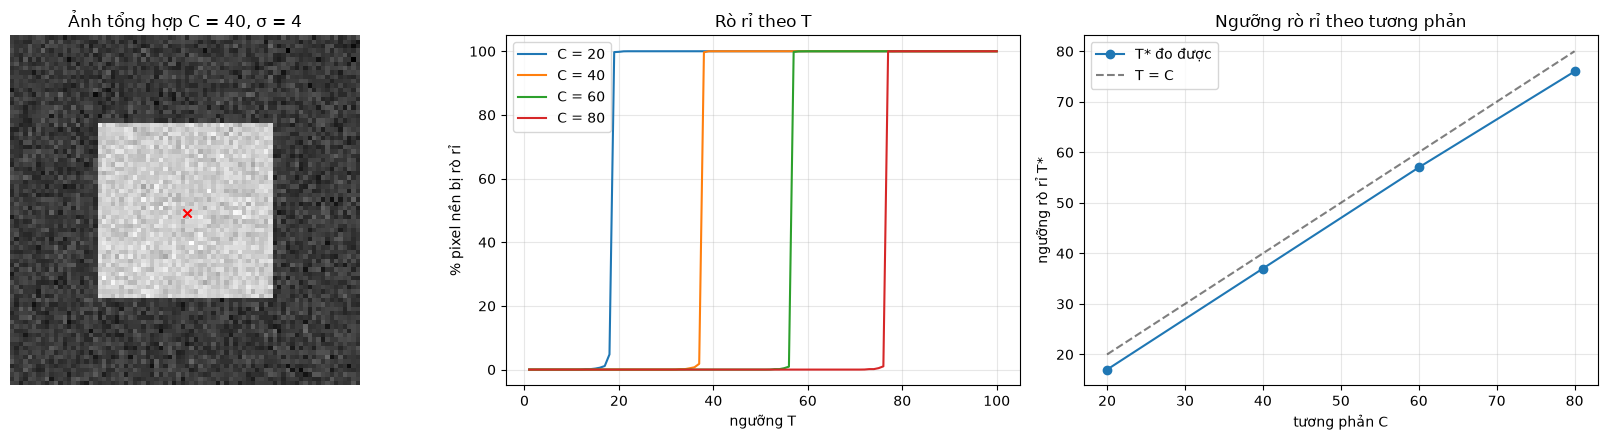

In [103]:
CAO, RONG = 80, 80
NEN = 100.0
DO_NHIEU = 4.0
mat_na_vat = np.zeros((CAO, RONG), dtype=bool)
mat_na_vat[20:60, 20:60] = True
hat_giong_vat = [(40, 40)]


def tao_anh_hai_vung(tuong_phan, do_nhieu=DO_NHIEU, hat_nhieu=0):
    rng = np.random.default_rng(hat_nhieu)
    anh = np.full((CAO, RONG), NEN)
    anh[mat_na_vat] += tuong_phan
    return anh + rng.normal(0.0, do_nhieu, anh.shape)


cac_tuong_phan = [20, 40, 60, 80]
cac_T = np.arange(1, 101)
ti_le_ro_ri = {}
ti_le_phu_vat = {}
T_ro_ri = {}

for C in cac_tuong_phan:
    anh = tao_anh_hai_vung(C)
    ro_ri, phu_vat = [], []
    for T in cac_T:
        nhan = region_growing_classic(anh, hat_giong_vat, T=float(T), order="stack")
        vung = nhan == 0
        ro_ri.append(np.sum(vung & ~mat_na_vat) / np.sum(~mat_na_vat))
        phu_vat.append(np.sum(vung & mat_na_vat) / np.sum(mat_na_vat))
    ti_le_ro_ri[C] = np.array(ro_ri)
    ti_le_phu_vat[C] = np.array(phu_vat)
    vuot = cac_T[ti_le_ro_ri[C] > 0.01]
    T_ro_ri[C] = int(vuot[0]) if len(vuot) else None

print(f"Nhiễu σ = {DO_NHIEU}, vật 40x40, hạt giống {hat_giong_vat}, order = stack")
print(f"{'C':>4} | {'T phủ ≥ 99% vật':>16} | {'T rò rỉ đầu tiên':>16} | {'T* rò rỉ > 1%':>14} | "
      f"{'C − T*':>7} | {'rò rỉ tại T*':>12}")
for C in cac_tuong_phan:
    du_vat = cac_T[ti_le_phu_vat[C] >= 0.99]
    T_du = int(du_vat[0]) if len(du_vat) else None
    co_ro = cac_T[ti_le_ro_ri[C] > 0]
    T_dau = int(co_ro[0]) if len(co_ro) else None
    t = T_ro_ri[C]
    tai_t = ti_le_ro_ri[C][t - 1] if t else float("nan")
    print(f"{C:4d} | {str(T_du):>16} | {str(T_dau):>16} | {str(t):>14} | {str(C - t) if t else '-':>7} | {tai_t:12.1%}")

hinh, truc = plt.subplots(1, 3, figsize=(17, 4.5))
truc[0].imshow(tao_anh_hai_vung(40), cmap="gray")
truc[0].scatter([c for _, c in hat_giong_vat], [r for r, _ in hat_giong_vat], c="red", marker="x")
truc[0].set_title("Ảnh tổng hợp C = 40, σ = 4"); truc[0].axis("off")
for C in cac_tuong_phan:
    truc[1].plot(cac_T, 100 * ti_le_ro_ri[C], label=f"C = {C}")
truc[1].set_xlabel("ngưỡng T"); truc[1].set_ylabel("% pixel nền bị rò rỉ")
truc[1].grid(alpha=0.3); truc[1].legend(); truc[1].set_title("Rò rỉ theo T")
co_T = [C for C in cac_tuong_phan if T_ro_ri[C] is not None]
truc[2].plot(co_T, [T_ro_ri[C] for C in co_T], "o-", label="T* đo được")
truc[2].plot(cac_tuong_phan, cac_tuong_phan, "k--", alpha=0.5, label="T = C")
truc[2].set_xlabel("tương phản C"); truc[2].set_ylabel("ngưỡng rò rỉ T*")
truc[2].grid(alpha=0.3); truc[2].legend(); truc[2].set_title("Ngưỡng rò rỉ theo tương phản")
plt.tight_layout()
plt.show()

Ảnh C = 40, σ = 4.0; hạt giống [(23, 40), (5, 5)]; n_trials = 40; T (RG) = 15
jitter | P ra ngoài |  RG: độ nhạy TB  % px đổi |  SRG: độ nhạy TB  % px đổi
     0 |      0.000 |          0.0000      0.0% |           0.0000      0.0%
     1 |      0.000 |          0.0000      0.0% |           0.0000      0.0%
     2 |      0.000 |          0.0000      0.0% |           0.0000      0.0%
     3 |      0.000 |          0.0000      0.0% |           0.0000      0.0%
     4 |      0.111 |          0.0750    100.0% |           0.0547     98.9%
     5 |      0.182 |          0.1750    100.0% |           0.0614     99.5%
     6 |      0.231 |          0.2750    100.0% |           0.1136    100.0%
     7 |      0.267 |          0.2750    100.0% |           0.1142     99.8%
     8 |      0.294 |          0.2000    100.0% |           0.0559    100.0%
     9 |      0.316 |          0.3000    100.0% |           0.0950     49.5%
    10 |      0.333 |          0.4499    100.0% |           0.1290    100.0

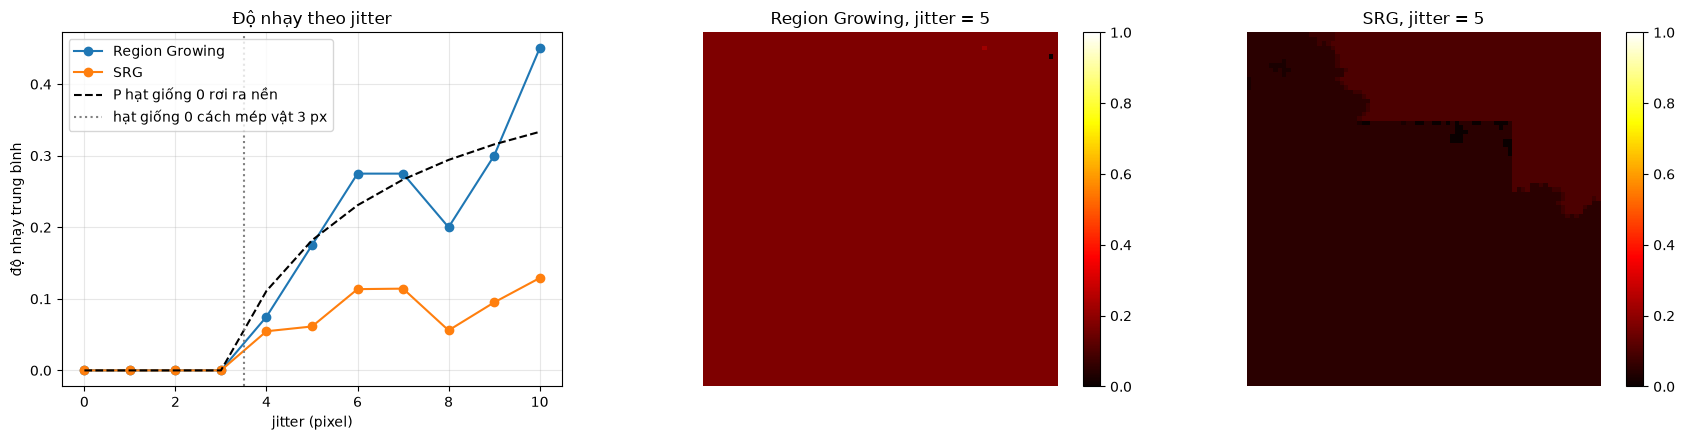

In [104]:
anh_jitter = tao_anh_hai_vung(40)
hat_giong_jitter = [(23, 40), (5, 5)]
T_RG = 15


def chay_rg(anh, hat):
    return region_growing_classic(anh, hat, T=T_RG, order="stack")


def chay_srg(anh, hat):
    return srg(anh, hat, connectivity=4, stale="lazy", tie="insertion")[0]


cac_jitter = list(range(0, 11))
do_nhay = {"Region Growing": [], "SRG": []}
ti_le_doi = {"Region Growing": [], "SRG": []}
ban_do = {}
for j in cac_jitter:
    for ten, ham in (("Region Growing", chay_rg), ("SRG", chay_srg)):
        bd = seed_sensitivity(anh_jitter, hat_giong_jitter, ham, n_trials=40, jitter=j)
        do_nhay[ten].append(float(bd.mean()))
        ti_le_doi[ten].append(float(np.mean(bd > 0)))
        ban_do[(ten, j)] = bd

xac_suat_ra_ngoai = [max(0, j - 3) / (2 * j + 1) for j in cac_jitter]
print(f"Ảnh C = 40, σ = {DO_NHIEU}; hạt giống {hat_giong_jitter}; n_trials = 40; T (RG) = {T_RG}")
print(f"{'jitter':>6} | {'P ra ngoài':>10} | {'RG: độ nhạy TB':>15} {'% px đổi':>9} | {'SRG: độ nhạy TB':>16} {'% px đổi':>9}")
for k, j in enumerate(cac_jitter):
    print(f"{j:6d} | {xac_suat_ra_ngoai[k]:10.3f} | {do_nhay['Region Growing'][k]:15.4f} "
          f"{100 * ti_le_doi['Region Growing'][k]:8.1f}% | "
          f"{do_nhay['SRG'][k]:16.4f} {100 * ti_le_doi['SRG'][k]:8.1f}%")

hinh, truc = plt.subplots(1, 3, figsize=(17, 4.5))
for ten in do_nhay:
    truc[0].plot(cac_jitter, do_nhay[ten], "o-", label=ten)
truc[0].plot(cac_jitter, xac_suat_ra_ngoai, "k--", label="P hạt giống 0 rơi ra nền")
truc[0].axvline(3.5, color="gray", ls=":", label="hạt giống 0 cách mép vật 3 px")
truc[0].set_xlabel("jitter (pixel)"); truc[0].set_ylabel("độ nhạy trung bình")
truc[0].grid(alpha=0.3); truc[0].legend(); truc[0].set_title("Độ nhạy theo jitter")
for k, ten in enumerate(do_nhay, start=1):
    im = truc[k].imshow(ban_do[(ten, 5)], cmap="hot", vmin=0, vmax=1)
    truc[k].set_title(f"{ten}, jitter = 5"); truc[k].axis("off")
    hinh.colorbar(im, ax=truc[k], fraction=0.046)
plt.tight_layout()
plt.show()

## Thí nghiệm - B: SRG lazy/frozen, phá hòa và ảnh tiến trình

Tự chọn dữ liệu, trục quét, số đo và kết luận. Theo mục 5.1, mỗi cặp cần bằng chứng khác biệt, quét tham số có ý nghĩa và giải thích cơ chế. Nếu thực tế dùng AI hỗ trợ cell thí nghiệm, ghi prompt nguyên văn ngay phía trên cell đó.

### Thiết kế và bằng chứng khác biệt

Nêu ảnh nào, vì sao chọn, giữ cố định điều kiện gì và đo đại lượng nào. Trình bày kết quả của hai phương pháp.

**Khai báo AI cho cell thí nghiệm bên dưới**

- Công cụ: Claude Code (Anthropic).
- Mục đích: Chuẩn bị ảnh dốc có biên thật, ảnh `uneven_lighting.jpg` và các hàm đo cho thí nghiệm SRG.

- Phần đã tự sửa và kiểm tra: Chạy lại trên máy mình, kiểm tra ảnh dốc có biên thật ở cột 80 và hạt giống trùng cell chạy thử Vòng 1.

- Prompt nguyên văn:

> Chuẩn bị dữ liệu cho thí nghiệm SRG. Tạo ảnh dốc 40 × 120 có biên thật ở cột 80 và hai vùng hạt giống ở hai mép, nạp và thu nhỏ `uneven_lighting.jpg`, rồi viết các hàm phụ để đo lỗi nhãn, vị trí biên và thời gian chạy.

Ảnh dốc: 40x120, biên thật ở cột 80, hạt giống = cột 0 và cột 119
Ảnh thật: uneven_lighting.jpg thu về 160x120, hạt giống = [(12, 90), (30, 30)], TIE_RANDOM_SEED = 0


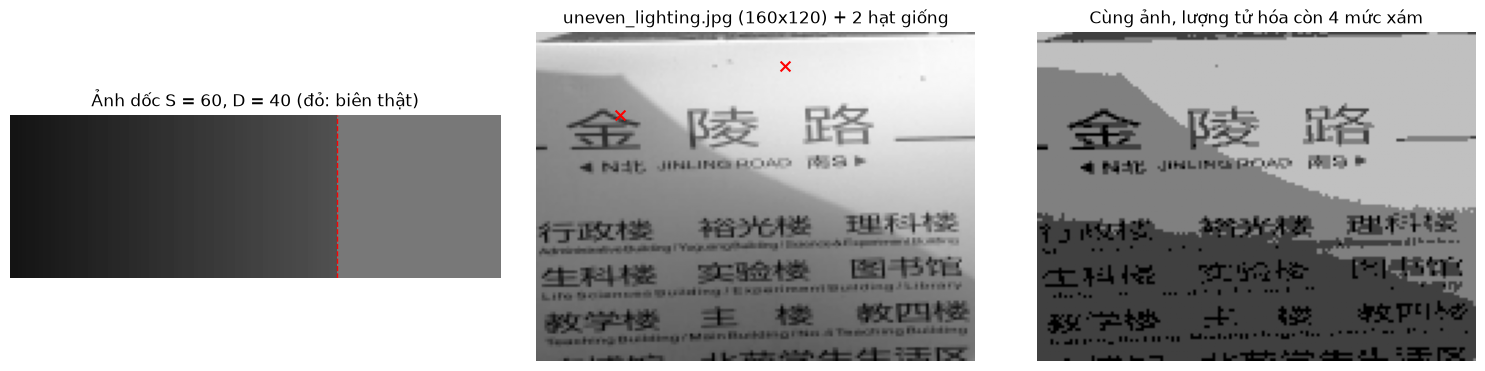

In [105]:
CAC_CHE_DO_CU = ("lazy", "frozen")
CAC_LUAT_HOA = ("insertion", "raster", "random")

CAO_DOC, RONG_DOC, COT_BIEN_THAT = 40, 120, 80
MUC_DAU = 20.0


def tao_anh_doc(do_doc, buoc_bien):
    anh = np.empty((CAO_DOC, RONG_DOC))
    anh[:, :COT_BIEN_THAT] = MUC_DAU + do_doc * np.arange(COT_BIEN_THAT) / (COT_BIEN_THAT - 1)
    anh[:, COT_BIEN_THAT:] = MUC_DAU + do_doc + buoc_bien
    return anh


HAT_DOC = [[(r, 0) for r in range(CAO_DOC)], [(r, RONG_DOC - 1) for r in range(CAO_DOC)]]
NHAN_DUNG_DOC = np.zeros((CAO_DOC, RONG_DOC), dtype=np.int32)
NHAN_DUNG_DOC[:, COT_BIEN_THAT:] = 1


def so_pixel_sai(nhan):
    """Số pixel bị gán khác đáp án đúng của ảnh dốc."""
    return int((nhan != NHAN_DUNG_DOC).sum())


def cot_bien_do_duoc(nhan):
    """Cột đầu tiên thuộc vùng 1 ở hàng giữa (biên thật là cột 80)."""
    return int(np.argmax(nhan[CAO_DOC // 2] == 1))


anh_goc = test_img
anh_that = cv2.resize(anh_goc, (160, 120), interpolation=cv2.INTER_AREA)
HAT_THAT = [(12, 90), (30, 30)]


def luong_tu_hoa(anh, so_muc):
    """Giảm ảnh 8-bit còn so_muc mức xám: càng ít mức, càng nhiều pixel cùng giá trị."""
    buoc = 256 / so_muc
    return np.floor(np.asarray(anh, dtype=float) / buoc) * buoc


def ti_le_lang_gieng_bang_nhau(anh):
    """Tỉ lệ cặp pixel kề nhau (liên thông 4) có cùng giá trị: thước đo mức 'phẳng'."""
    ngang = anh[:, 1:] == anh[:, :-1]
    doc = anh[1:, :] == anh[:-1, :]
    return (ngang.sum() + doc.sum()) / (ngang.size + doc.size)


def so_pixel_khac(nhan_a, nhan_b):
    return int((nhan_a != nhan_b).sum())


def chay_srg_do_gio(anh, hat, **tham_so):
    """Gọi srg và đo thời gian (ms) bằng time.perf_counter."""
    t0 = time.perf_counter()
    nhan, bien = srg(anh, hat, **tham_so)
    return nhan, bien, 1000 * (time.perf_counter() - t0)


print(f"Ảnh dốc: {CAO_DOC}x{RONG_DOC}, biên thật ở cột {COT_BIEN_THAT}, hạt giống = cột 0 và cột {RONG_DOC - 1}")
print(f"Ảnh thật: uneven_lighting.jpg thu về {anh_that.shape[1]}x{anh_that.shape[0]}, "
      f"hạt giống = {HAT_THAT}, TIE_RANDOM_SEED = {TIE_RANDOM_SEED}")

hinh, truc = plt.subplots(1, 3, figsize=(15, 3.6), constrained_layout=True)
truc[0].imshow(tao_anh_doc(60, 40), cmap="gray", vmin=0, vmax=255)
truc[0].axvline(COT_BIEN_THAT - 0.5, color="red", ls="--", lw=1)
truc[0].set_title("Ảnh dốc S = 60, D = 40 (đỏ: biên thật)")
truc[1].imshow(anh_that, cmap="gray")
for hang, cot in HAT_THAT:
    truc[1].scatter(cot, hang, marker="x", s=50, c="red")
truc[1].set_title("uneven_lighting.jpg (160x120) + 2 hạt giống")
truc[2].imshow(luong_tu_hoa(anh_that, 4), cmap="gray", vmin=0, vmax=255)
truc[2].set_title("Cùng ảnh, lượng tử hóa còn 4 mức xám")
for t in truc:
    t.axis("off")
plt.show()

**Khai báo AI cho cell thí nghiệm bên dưới**

- Công cụ: Claude Code (Anthropic).
- Mục đích: So sánh `lazy` với `frozen` và đo số pixel đổi nhãn khi thay quy tắc phá hòa.
- Hỗ trợ ô Nhận xét: Tham khảo nhận xét mẫu của Claude, sau đó tự viết lại và thay số theo kết quả chạy trên máy mình.

- Phần đã tự sửa và kiểm tra: Chạy lại trên máy mình, đối chiếu số pixel sai, số pixel đổi nhãn và thời gian trong Nhận xét với output.

- Prompt nguyên văn:

> Dùng hàm `srg` sẵn có để so sánh `lazy` và `frozen` trên ảnh dốc cùng hạt giống, đo số pixel sai và vị trí biên. Trên ảnh đã lượng tử hóa còn 4 mức xám, đếm số pixel đổi nhãn giữa `insertion`, `raster` và `random` với seed cố định.

(a) Ảnh dốc S = 60, D = 40, tie = insertion, liên thông 4
stale    pixel sai   % sai  cột biên đo được   t (ms)
lazy             0     0.0                80     79.4
frozen         560    11.7                66     84.8
Biên thật: cột 80. Số pixel khác nhau lazy vs frozen: 560

(b) uneven_lighting.jpg 160x120, hạt giống [(12, 90), (30, 30)], tie = insertion, liên thông 4
lazy     vùng 0 =   7206 px, vùng 1 =  11994 px, pixel biên =  335, t = 462.7 ms
frozen   vùng 0 =   6689 px, vùng 1 =  12511 px, pixel biên =  247, t = 317.7 ms
Số pixel khác nhau lazy vs frozen: 517 (2.7% ảnh)

(c) uneven_lighting.jpg lượng tử hóa 4 mức, lazy, liên thông 4, TIE_RANDOM_SEED = 0
Tỉ lệ cặp pixel kề nhau cùng giá trị: 0.859 (ảnh 8-bit gốc: 0.255)
tie=insertion  vùng 0 =   6924 px, vùng 1 =  12276 px, t = 292.5 ms
tie=raster     vùng 0 =   6778 px, vùng 1 =  12422 px, t = 310.0 ms
tie=random     vùng 0 =   6914 px, vùng 1 =  12286 px, t = 377.6 ms
Số pixel khác nhau insertion vs raster: 232
Số pixel khác 

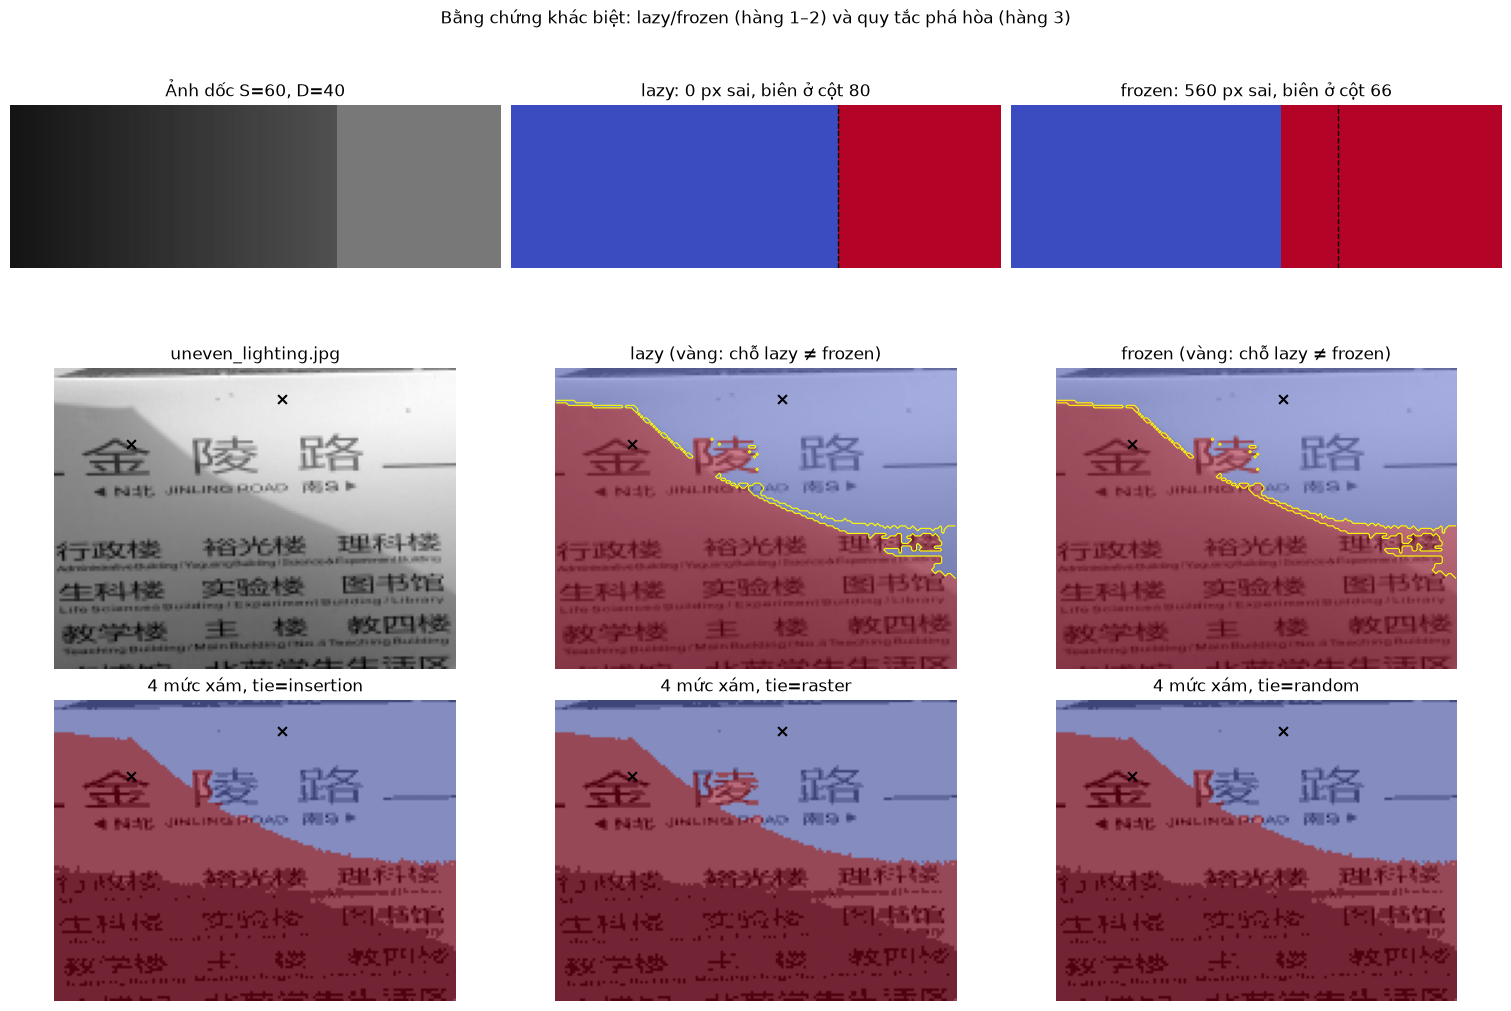

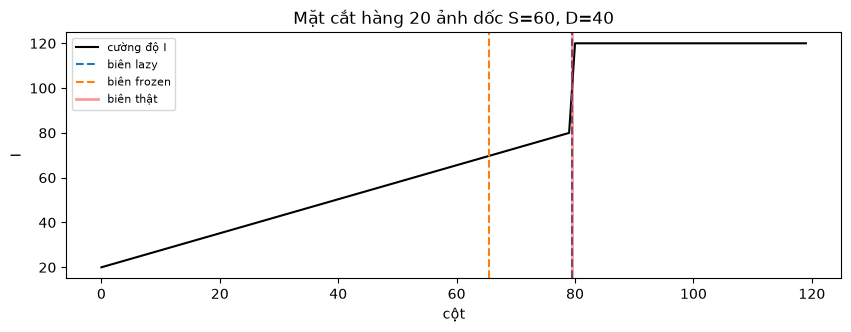

In [ ]:
S_MAU, D_MAU = 60, 40
anh_doc_mau = tao_anh_doc(S_MAU, D_MAU)
ket_qua_doc = {}
print(f"(a) Ảnh dốc S = {S_MAU}, D = {D_MAU}, tie = insertion, liên thông 4")
print(f"{'stale':<8}{'pixel sai':>10}{'% sai':>8}{'cột biên đo được':>18}{'t (ms)':>9}")
for che_do in CAC_CHE_DO_CU:
    nhan, bien, t_ms = chay_srg_do_gio(anh_doc_mau, HAT_DOC, stale=che_do)
    assert (nhan >= 0).all() and set(np.unique(nhan)) == {0, 1}
    ket_qua_doc[che_do] = nhan
    print(f"{che_do:<8}{so_pixel_sai(nhan):>10}{100 * so_pixel_sai(nhan) / nhan.size:>8.1f}"
          f"{cot_bien_do_duoc(nhan):>18}{t_ms:>9.1f}")
print(f"Biên thật: cột {COT_BIEN_THAT}. Số pixel khác nhau lazy vs frozen: "
      f"{so_pixel_khac(ket_qua_doc['lazy'], ket_qua_doc['frozen'])}")

print(f"\n(b) uneven_lighting.jpg 160x120, hạt giống {HAT_THAT}, tie = insertion, liên thông 4")
ket_qua_that = {}
for che_do in CAC_CHE_DO_CU:
    nhan, bien, t_ms = chay_srg_do_gio(anh_that, HAT_THAT, stale=che_do)
    assert (nhan >= 0).all()
    ket_qua_that[che_do] = nhan
    print(f"{che_do:<8} vùng 0 = {(nhan == 0).sum():>6} px, vùng 1 = {(nhan == 1).sum():>6} px, "
          f"pixel biên = {bien.sum():>4}, t = {t_ms:.1f} ms")
khac_that = ket_qua_that["lazy"] != ket_qua_that["frozen"]
print(f"Số pixel khác nhau lazy vs frozen: {khac_that.sum()} ({100 * khac_that.mean():.1f}% ảnh)")

SO_MUC_MAU = 4
anh_4_muc = luong_tu_hoa(anh_that, SO_MUC_MAU)
print(f"\n(c) uneven_lighting.jpg lượng tử hóa {SO_MUC_MAU} mức, lazy, liên thông 4, "
      f"TIE_RANDOM_SEED = {TIE_RANDOM_SEED}")
print(f"Tỉ lệ cặp pixel kề nhau cùng giá trị: {ti_le_lang_gieng_bang_nhau(anh_4_muc):.3f} "
      f"(ảnh 8-bit gốc: {ti_le_lang_gieng_bang_nhau(anh_that):.3f})")
ket_qua_hoa = {}
for luat in CAC_LUAT_HOA:
    nhan, _, t_ms = chay_srg_do_gio(anh_4_muc, HAT_THAT, tie=luat)
    assert (nhan >= 0).all()
    nhan_lai, _ = srg(anh_4_muc, HAT_THAT, tie=luat)
    assert (nhan_lai == nhan).all(), f"tie={luat} không tất định"
    ket_qua_hoa[luat] = nhan
    print(f"tie={luat:<10} vùng 0 = {(nhan == 0).sum():>6} px, vùng 1 = {(nhan == 1).sum():>6} px, t = {t_ms:.1f} ms")
for a, b in (("insertion", "raster"), ("insertion", "random"), ("raster", "random")):
    print(f"Số pixel khác nhau {a} vs {b}: {so_pixel_khac(ket_qua_hoa[a], ket_qua_hoa[b])}")
assert max(so_pixel_khac(ket_qua_hoa[a], ket_qua_hoa[b])
           for a in CAC_LUAT_HOA for b in CAC_LUAT_HOA) > 0, "Chưa tìm được ảnh mà đổi tie làm đổi kết quả"

hinh, truc = plt.subplots(3, 3, figsize=(15, 10), constrained_layout=True)
truc[0, 0].imshow(anh_doc_mau, cmap="gray", vmin=0, vmax=255)
truc[0, 0].set_title(f"Ảnh dốc S={S_MAU}, D={D_MAU}")
for k, che_do in enumerate(CAC_CHE_DO_CU, start=1):
    truc[0, k].imshow(ket_qua_doc[che_do], cmap="coolwarm", vmin=0, vmax=1)
    truc[0, k].axvline(COT_BIEN_THAT - 0.5, color="black", ls="--", lw=1)
    truc[0, k].set_title(f"{che_do}: {so_pixel_sai(ket_qua_doc[che_do])} px sai, "
                         f"biên ở cột {cot_bien_do_duoc(ket_qua_doc[che_do])}")
truc[1, 0].imshow(anh_that, cmap="gray")
truc[1, 0].set_title("uneven_lighting.jpg")
for k, che_do in enumerate(CAC_CHE_DO_CU, start=1):
    truc[1, k].imshow(anh_that, cmap="gray")
    truc[1, k].imshow(ket_qua_that[che_do], cmap="coolwarm", alpha=0.45, vmin=0, vmax=1)
    truc[1, k].contour(khac_that, levels=[0.5], colors="yellow", linewidths=0.8)
    truc[1, k].set_title(f"{che_do} (vàng: chỗ lazy ≠ frozen)")
for k, luat in enumerate(CAC_LUAT_HOA):
    truc[2, k].imshow(anh_4_muc, cmap="gray", vmin=0, vmax=255)
    truc[2, k].imshow(ket_qua_hoa[luat], cmap="coolwarm", alpha=0.45, vmin=0, vmax=1)
    truc[2, k].set_title(f"4 mức xám, tie={luat}")
for t in truc.ravel():
    t.axis("off")
for t in truc[1:].ravel():
    for hang, cot in HAT_THAT:
        t.scatter(cot, hang, marker="x", s=40, c="black")
hinh.suptitle("Bằng chứng khác biệt: lazy/frozen (hàng 1–2) và quy tắc phá hòa (hàng 3)")
plt.show()

hinh, truc = plt.subplots(figsize=(10, 3.2))
cot = np.arange(RONG_DOC)
truc.plot(cot, anh_doc_mau[CAO_DOC // 2], "k-", label="cường độ I")
for che_do, mau in zip(CAC_CHE_DO_CU, ("tab:blue", "tab:orange")):
    truc.axvline(cot_bien_do_duoc(ket_qua_doc[che_do]) - 0.5, color=mau, ls="--", label=f"biên {che_do}")
truc.axvline(COT_BIEN_THAT - 0.5, color="red", lw=2, alpha=0.4, label="biên thật")
truc.set_xlabel("cột"); truc.set_ylabel("I"); truc.legend(loc="upper left", fontsize=8)
truc.set_title(f"Mặt cắt hàng {CAO_DOC // 2} ảnh dốc S={S_MAU}, D={D_MAU}")
plt.show()


**Nhận xét từ số liệu đã chạy:**

- Mình chọn ảnh dốc tổng hợp vì biết trước biên thật ở cột 80, nên có thể đếm số pixel gán sai. Ảnh `uneven_lighting.jpg` dùng để xem hai chế độ khác nhau thế nào trên ảnh thật. Khi so sánh, mình giữ nguyên hạt giống, liên thông 4 và quy tắc `insertion`.
- Trên ảnh dốc với S = 60 và D = 40, `lazy` đặt biên đúng ở cột 80. Với `frozen`, vùng bên phải lấn 14 cột, làm biên nằm ở cột 66 và gán sai 560 pixel (11,7%). Trên ảnh thật, hai kết quả khác nhau 517 pixel (2,7%), chủ yếu dọc ranh giới sáng tối.
- Khi giảm ảnh thật xuống 4 mức xám, tỉ lệ cặp pixel kề nhau có cùng giá trị tăng từ 25,5% lên 85,9%. Đổi từ `insertion` sang `raster` làm 232 pixel đổi nhãn. Hai cặp `insertion`–`random` và `raster`–`random` lần lượt khác 14 và 222 pixel. Chạy lại với cùng quy tắc và seed 0 cho kết quả giống lần đầu.

### Quét tham số

Ghi trục quét, giá trị thử và các điều kiện giữ cố định; trình bày đường cong hoặc điểm chuyển hành vi.

**Khai báo AI cho cell thí nghiệm bên dưới**

- Công cụ: Claude Code (Anthropic).
- Mục đích: Quét độ dốc và số mức xám để đo sai số và mức đổi nhãn.
- Hỗ trợ ô Nhận xét: Tham khảo nhận xét mẫu của Claude, sau đó tự viết lại và thay số theo kết quả chạy trên máy mình.


- Phần đã tự sửa và kiểm tra: Lúc dán code bị dính hai dòng `plot` và `set_ylabel` thành một và mất dòng `set_xlabel` (SyntaxError); đã tách lại đúng ba dòng, chạy lại (khoảng 38 giây) và đối chiếu các mốc S bắt đầu sai với output.

- Prompt nguyên văn:

> Quét độ dốc S từ 0 đến 160, bước 5, với D = 20 và 40. Tìm mức S đầu tiên làm mỗi chế độ SRG gán sai. Sau đó quét số mức xám trên 12 cặp hạt giống cố định và vẽ tỉ lệ pixel đổi nhãn khi thay quy tắc phá hòa.

Trục 1 – ảnh dốc, tie = insertion, liên thông 4
    S     lazy D=20   frozen D=20     lazy D=40   frozen D=40
    0             0             0             0             0
   20             0             0             0             0
   40            40           800             0             0
   60           640          1080             0           560
   80           840          1200            40           800
  100           920          1280           440           960
  120          1000          1320           640          1080
  140          1040          1360           760          1160
  160          1040          1400           840          1200
D = 20: frozen bắt đầu sai ở S = 25, lazy bắt đầu sai ở S = 40
D = 40: frozen bắt đầu sai ở S = 45, lazy bắt đầu sai ở S = 80

Trục 2 – uneven_lighting.jpg 80x60, lazy, liên thông 4, 12 cặp hạt giống, TIE_RANDOM_SEED = 0
 số mức  cặp kề bằng nhau  cặp hạt bị đổi  % pixel đổi (TB)
    256             0.167          3/12            

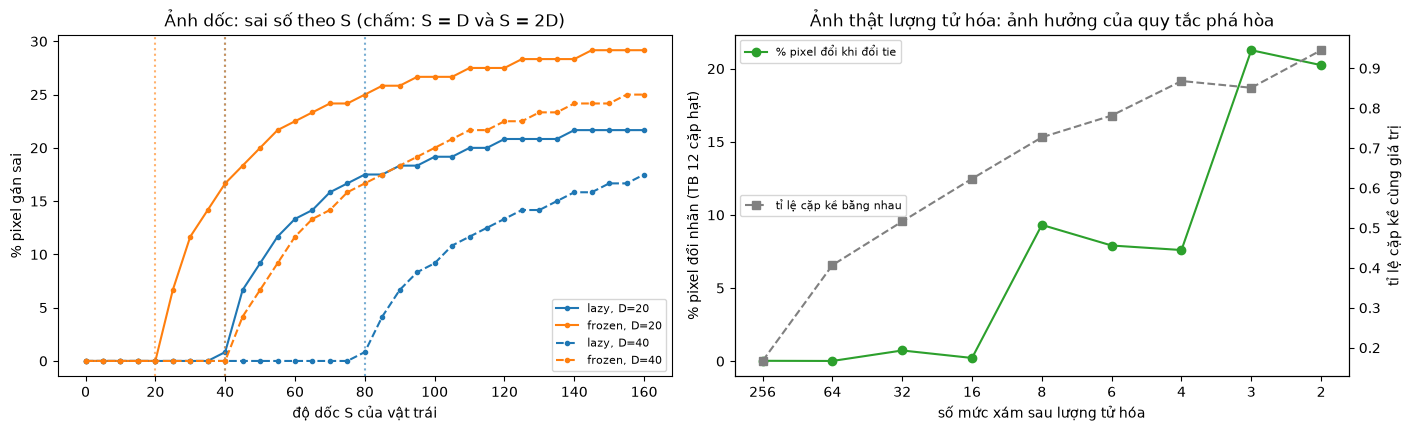

In [ ]:
CAC_D = (20, 40)
CAC_S = np.arange(0, 161, 5)
sai_theo_S = {(d, che_do): [] for d in CAC_D for che_do in CAC_CHE_DO_CU}
for d in CAC_D:
    for s in CAC_S:
        anh = tao_anh_doc(s, d)
        for che_do in CAC_CHE_DO_CU:
            nhan, _ = srg(anh, HAT_DOC, stale=che_do)
            sai_theo_S[(d, che_do)].append(so_pixel_sai(nhan))


def S_bat_dau_sai(d, che_do):
    """S nhỏ nhất trong lưới quét mà có pixel bị gán sai."""
    sai = np.array(sai_theo_S[(d, che_do)])
    return int(CAC_S[np.argmax(sai > 0)]) if (sai > 0).any() else None


print("Trục 1 – ảnh dốc, tie = insertion, liên thông 4")
print(f"{'S':>5}" + "".join(f"{f'{c} D={d}':>14}" for d in CAC_D for c in CAC_CHE_DO_CU))
for k, s in enumerate(CAC_S):
    if s % 20 == 0:
        print(f"{s:>5}" + "".join(f"{sai_theo_S[(d, c)][k]:>14}" for d in CAC_D for c in CAC_CHE_DO_CU))
for d in CAC_D:
    print(f"D = {d}: frozen bắt đầu sai ở S = {S_bat_dau_sai(d, 'frozen')}, "
          f"lazy bắt đầu sai ở S = {S_bat_dau_sai(d, 'lazy')}")

anh_nho = cv2.resize(anh_goc, (80, 60), interpolation=cv2.INTER_AREA)
bo_sinh = np.random.default_rng(1)  
CAC_CAP_HAT = []
while len(CAC_CAP_HAT) < 12:
    cap = bo_sinh.integers(0, anh_nho.shape, size=(2, 2))
    if np.abs(cap[0] - cap[1]).sum() >= 20: 
        CAC_CAP_HAT.append([tuple(int(v) for v in p) for p in cap])
CAC_SO_MUC = (256, 64, 32, 16, 8, 6, 4, 3, 2)
ti_le_bang, so_cap_doi, pct_doi = [], [], []
print(f"\nTrục 2 – uneven_lighting.jpg 80x60, lazy, liên thông 4, {len(CAC_CAP_HAT)} cặp hạt giống, "
      f"TIE_RANDOM_SEED = {TIE_RANDOM_SEED}")
print(f"{'số mức':>7}{'cặp kề bằng nhau':>18}{'cặp hạt bị đổi':>16}{'% pixel đổi (TB)':>18}")
for so_muc in CAC_SO_MUC:
    anh_q = luong_tu_hoa(anh_nho, so_muc)
    doi = []
    for hat in CAC_CAP_HAT:
        nhan = {luat: srg(anh_q, hat, tie=luat)[0] for luat in CAC_LUAT_HOA}
        doi.append(max(so_pixel_khac(nhan[a], nhan[b])
                       for a in CAC_LUAT_HOA for b in CAC_LUAT_HOA if a < b))
    ti_le_bang.append(ti_le_lang_gieng_bang_nhau(anh_q))
    so_cap_doi.append(int(np.sum(np.array(doi) > 0)))
    pct_doi.append(100 * np.mean(doi) / anh_q.size)
    print(f"{so_muc:>7}{ti_le_bang[-1]:>18.3f}{so_cap_doi[-1]:>11}/{len(CAC_CAP_HAT)}{pct_doi[-1]:>18.2f}")
print("(% pixel đổi: với mỗi cặp hạt lấy cặp tie khác nhau nhiều nhất, rồi lấy trung bình 12 cặp)")

hinh, truc = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
for d, kieu in zip(CAC_D, ("-", "--")):
    for che_do, mau in zip(CAC_CHE_DO_CU, ("tab:blue", "tab:orange")):
        truc[0].plot(CAC_S, 100 * np.array(sai_theo_S[(d, che_do)]) / NHAN_DUNG_DOC.size,
                     kieu, color=mau, marker=".", label=f"{che_do}, D={d}")
    truc[0].axvline(d, color="tab:orange", ls=":", alpha=0.6)
    truc[0].axvline(2 * d, color="tab:blue", ls=":", alpha=0.6)
truc[0].set_xlabel("độ dốc S của vật trái")
truc[0].set_ylabel("% pixel gán sai")
truc[0].set_title("Ảnh dốc: sai số theo S (chấm: S = D và S = 2D)")
truc[0].legend(fontsize=8)
nhan_x = [str(m) for m in CAC_SO_MUC]
truc[1].plot(nhan_x, pct_doi, "o-", color="tab:green", label="% pixel đổi khi đổi tie")
truc[1].set_xlabel("số mức xám sau lượng tử hóa")
truc[1].set_ylabel("% pixel đổi nhãn (TB 12 cặp hạt)")
truc2 = truc[1].twinx()
truc2.plot(nhan_x, ti_le_bang, "s--", color="gray", label="tỉ lệ cặp kề bằng nhau")
truc2.set_ylabel("tỉ lệ cặp kề cùng giá trị")
truc[1].set_title("Ảnh thật lượng tử hóa: ảnh hưởng của quy tắc phá hòa")
truc[1].legend(loc="upper left", fontsize=8); truc2.legend(loc="center left", fontsize=8)
plt.show()

**Nhận xét từ số liệu đã chạy:**

- Khi quét S từ 0 đến 160 (bước 5), mình giữ nguyên hạt giống, liên thông 4 và quy tắc `insertion`. Với D = 20, `frozen` bắt đầu sai ở S = 25, còn `lazy` bắt đầu sai ở S = 40. Với D = 40, hai mốc lần lượt là S = 45 và S = 80. Trên lưới quét, `frozen` bắt đầu sai ngay sau D, còn `lazy` giữ đúng đến gần 2D.
- Với 12 cặp hạt giống cố định trên ảnh thật 80 × 60, tỉ lệ pixel đổi nhãn khi thay quy tắc phá hòa nhìn chung tăng khi giảm số mức xám. Tỉ lệ này là 0,03% ở 256 mức, 9,32% ở 8 mức và 21,26% ở 3 mức, rồi giảm còn 20,24% ở 2 mức. Ngay ở ảnh 256 mức, 3 trong 12 cặp hạt giống đã cho kết quả khác khi đổi quy tắc.

### Giải thích kết quả

Điền kết quả đo, giải thích đại lượng nào thay đổi, ở bước nào và vì sao. Báo cả trường hợp chưa cải thiện.

**Khai báo AI cho cell thí nghiệm bên dưới**

- Công cụ: Claude Code (Anthropic).
- Mục đích: Theo dõi 8 mốc tiến trình, đối chiếu ngưỡng sai và đo thời gian chạy.
- Hỗ trợ ô Nhận xét: Tham khảo nhận xét mẫu của Claude, sau đó tự viết lại và thay số theo kết quả chạy trên máy mình.


- Phần đã tự sửa và kiểm tra: Thay số thời gian trong Nhận xét bằng số đo trên máy mình (320x240: lazy 1.350,2 ms, frozen 1.040,8 ms).

- Prompt nguyên văn:

> Dùng `srg_step_frames` để lấy 8 mốc của `lazy` và `frozen`, theo dõi giá trị tham chiếu và vị trí biên. Đối chiếu ngưỡng S dự đoán với kết quả quét và đo thời gian của hai chế độ trên bốn kích thước ảnh.

(a) Ảnh dốc S = 60, D = 40: tham chiếu của từng vùng tại 8 mốc tiến trình
 mốc   lazy: TB vùng 0  TB vùng 1  cột phải nhất v0     frozen: hạt 0  hạt 1  cột phải nhất v0
   1              20.0      120.0                 0              20.0  120.0                 0
   2              20.0      120.0                 0              20.0  120.0                 0
   3              21.5      120.0                 4              20.0  120.0                 4
   4              27.2      120.0                19              20.0  120.0                19
   5              32.9      120.0                34              20.0  120.0                34
   6              38.6      120.0                49              20.0  120.0                49
   7              44.3      120.0                64              20.0  120.0                58
   8              50.0      120.0                79              20.0  120.0                65

Ngưỡng S bắt đầu sai: dự đoán từ công thức (5) vs S đầu tiên có pixel 

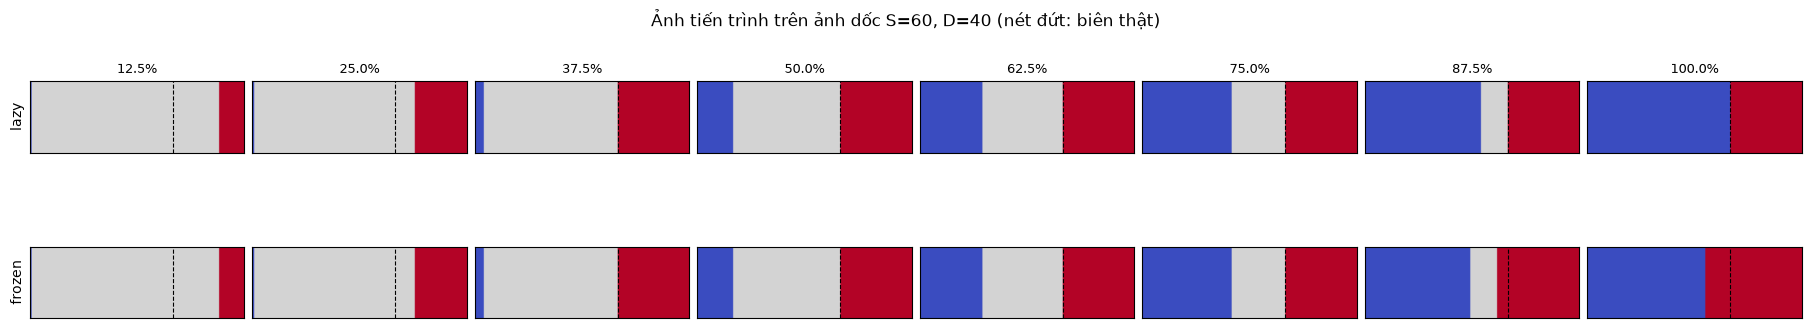


(b) Thời gian srg trên uneven_lighting.jpg, tie = insertion, liên thông 4, lấy min của 3 lần chạy
 kích thước  n pixel  lazy (ms)  frozen (ms)  lazy/frozen  lazy µs/(n·log2 n)
      80x60     4800       71.9         47.1         1.53               1.224
    160x120    19200      284.8        221.6         1.29               1.042
    240x180    43200      682.1        450.2         1.52               1.025
    320x240    76800     1273.2        902.9         1.41               1.021


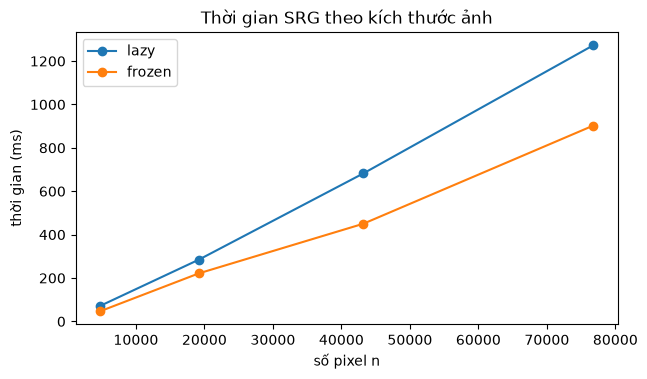

In [108]:
SO_MOC = 8
print(f"(a) Ảnh dốc S = {S_MAU}, D = {D_MAU}: tham chiếu của từng vùng tại {SO_MOC} mốc tiến trình")
print(f"{'mốc':>4}{'':>2}{'lazy: TB vùng 0':>16}{'TB vùng 1':>11}{'cột phải nhất v0':>18}"
      f"{'':>4}{'frozen: hạt 0':>14}{'hạt 1':>7}{'cột phải nhất v0':>18}")
cac_moc = {che_do: srg_step_frames(anh_doc_mau, HAT_DOC, n_frames=SO_MOC, stale=che_do)
           for che_do in CAC_CHE_DO_CU}
tb_vung_0_lazy = []
for k in range(SO_MOC):
    dong = f"{k + 1:>4}{'':>2}"
    for che_do in CAC_CHE_DO_CU:
        f = cac_moc[che_do][k]
        if che_do == "lazy":
            tb0, tb1 = anh_doc_mau[f == 0].mean(), anh_doc_mau[f == 1].mean()
            tb_vung_0_lazy.append(tb0)
        else:
            tb0, tb1 = MUC_DAU, MUC_DAU + S_MAU + D_MAU
        cot_phai = int(np.nonzero((f == 0).any(axis=0))[0].max())
        dong += f"{tb0:>16.1f}{tb1:>11.1f}{cot_phai:>18}{'':>4}" if che_do == "lazy" else \
                f"{tb0:>14.1f}{tb1:>7.1f}{cot_phai:>18}"
    print(dong)
for che_do in CAC_CHE_DO_CU:
    assert (cac_moc[che_do][-1] == ket_qua_doc[che_do]).all(), "mốc cuối phải trùng kết quả srg"

print("\nNgưỡng S bắt đầu sai: dự đoán từ công thức (5) vs S đầu tiên có pixel sai trên lưới quét (bước 5)")
for d in CAC_D:
    print(f"D = {d}: frozen dự đoán S > {d}, lưới quét {S_bat_dau_sai(d, 'frozen')};  "
          f"lazy dự đoán S > {79 * d / 40:.1f}, lưới quét {S_bat_dau_sai(d, 'lazy')}")

hinh, truc = plt.subplots(2, SO_MOC, figsize=(18, 3.6), constrained_layout=True)
for hang_hinh, che_do in enumerate(CAC_CHE_DO_CU):
    for k in range(SO_MOC):
        t = truc[hang_hinh, k]
        t.imshow(np.ma.masked_less(cac_moc[che_do][k], 0), cmap="coolwarm", vmin=0, vmax=1)
        t.set_facecolor("lightgray")
        t.axvline(COT_BIEN_THAT - 0.5, color="black", ls="--", lw=0.8)
        t.set_xticks([]); t.set_yticks([])
        if hang_hinh == 0:
            t.set_title(f"{100 * (k + 1) / SO_MOC:.1f}%", fontsize=9)
        if k == 0:
            t.set_ylabel(che_do)
hinh.suptitle(f"Ảnh tiến trình trên ảnh dốc S={S_MAU}, D={D_MAU} (nét đứt: biên thật)")
plt.show()

CAC_KICH_THUOC = ((80, 60), (160, 120), (240, 180), (320, 240))
SO_LAN_DO = 3
print(f"\n(b) Thời gian srg trên uneven_lighting.jpg, tie = insertion, liên thông 4, "
      f"lấy min của {SO_LAN_DO} lần chạy")
print(f"{'kích thước':>11}{'n pixel':>9}{'lazy (ms)':>11}{'frozen (ms)':>13}{'lazy/frozen':>13}"
      f"{'lazy µs/(n·log2 n)':>20}")
thoi_gian = {che_do: [] for che_do in CAC_CHE_DO_CU}
cac_n = []
for rong, cao in CAC_KICH_THUOC:
    anh = cv2.resize(anh_goc, (rong, cao), interpolation=cv2.INTER_AREA)
    hat = [(int(r * cao / 120), int(c * rong / 160)) for r, c in HAT_THAT]
    n = anh.size
    cac_n.append(n)
    for che_do in CAC_CHE_DO_CU:
        thoi_gian[che_do].append(min(chay_srg_do_gio(anh, hat, stale=che_do)[2] for _ in range(SO_LAN_DO)))
    tl, tf = thoi_gian["lazy"][-1], thoi_gian["frozen"][-1]
    print(f"{f'{rong}x{cao}':>11}{n:>9}{tl:>11.1f}{tf:>13.1f}{tl / tf:>13.2f}"
          f"{1000 * tl / (n * np.log2(n)):>20.3f}")

hinh, truc = plt.subplots(figsize=(7, 3.8))
for che_do, mau in zip(CAC_CHE_DO_CU, ("tab:blue", "tab:orange")):
    truc.plot(cac_n, thoi_gian[che_do], "o-", color=mau, label=che_do)
truc.set_xlabel("số pixel n"); truc.set_ylabel("thời gian (ms)")
truc.set_title("Thời gian SRG theo kích thước ảnh")
truc.legend()
plt.show()


**Nhận xét từ số liệu đã chạy:**

- Khi tính δ, `frozen` giữ tham chiếu của vùng trái ở giá trị hạt giống là 20. Với `lazy`, tham chiếu là trung bình vùng, tăng từ 20 lên 50 khi vùng lan qua dải chuyển màu.
- Xét cột 79 sát biên thật, độ lệch của pixel so với vùng phải là D. Với vùng trái, độ lệch là S ở `frozen` và S × 40/79 ở `lazy`. Vì vậy, vùng phải có thể lấn sang khi S vượt D ở `frozen` hoặc 79D/40 ở `lazy`. Các ngưỡng này khớp với số liệu quét theo bước 5. Khi dốc đủ lớn, trung bình vùng vẫn lệch nhiều so với pixel ở mép nên `lazy` cũng gán sai.
- Trên ảnh lượng tử hóa, nhiều ứng viên có cùng δ. Quy tắc phá hòa quyết định pixel nào được xét trước và vùng nào được ưu tiên khi bằng điểm. Một pixel đổi vùng có thể làm các pixel kề nó đổi theo.
- Bảng phía trên ghi thời gian chạy của từng chế độ ở bốn kích thước và thời gian của `lazy` chia cho n log₂ n. Khi trung bình vùng thay đổi, một số pixel phải đưa lại vào hàng đợi vì δ đã đổi.

# Vòng 4 – Duyệt chéo và kiểm chứng phần A

## 1. Mục tiêu kiểm tra

Duyệt chéo phần A trong notebook bản gộp `bai_tap_2/bt2_nhom.ipynb` nhằm:

- Kiểm tra code, output và kết quả của năm kiểm chứng A1–A5.
- Đối chiếu hình ảnh bàn cờ, xoay 30° và phóng to 3×.
- Kiểm tra cách tính repeatability theo phép biến đổi tọa độ.
- Kiểm tra khả năng truy cập ảnh đầu vào bằng đường dẫn tương đối.
- Chạy lại notebook từ Kernel mới để xác nhận tính độc lập.
- Ghi nhận các vấn đề cần báo Hiệp, không chỉnh sửa code của thành viên khác.

## 2. Đối chiếu kết quả A1–A5

### A1 – Bàn cờ tổng hợp

- Người phụ trách: Hồng Gấm.
- Ảnh kiểm tra: Bàn cờ 8×8, kích thước 128×128 pixel.
- Ba trường hợp: Bàn cờ 0/255, bàn cờ 0/1 và bàn cờ đảo màu.
- Số giao điểm trong theo lý thuyết: 49.
- Số giao điểm phát hiện: 49/49 ở cả ba trường hợp.
- Số giao điểm có nhiều hơn một điểm Harris: 0.
- Sai số lớn nhất: 0,7071 px.
- Sai số trung bình: 0,7071 px.

**Nhận xét:** Thuật toán Harris cổ điển phát hiện đầy đủ 49 giao điểm trong ở cả ba trường hợp. Sai số định vị nhỏ hơn 1 px, không xuất hiện nhiều điểm Harris tại cùng một giao điểm.

**Đánh giá:** Đạt.

### A2 – Xoay ảnh 30°

- Người phụ trách: Hồng Gấm.
- Ảnh đầu vào: `home.jpg`.
- Kích thước ảnh: 384×512 pixel.
- Góc xoay: 30°.
- Số điểm Harris trên ảnh gốc: 332.
- Số điểm Harris trên ảnh xoay: 290.
- Số điểm gốc có tọa độ chiếu nằm trong ảnh xoay: 289.

| Ngưỡng sai lệch | Repeatability |
|---|---:|
| 1 px | 0,8235 |
| 2 px | 0,8927 |
| 3 px | 0,9170 |

- Repeatability bằng ma trận biến đổi 3×3: 0,9170.
- Repeatability bằng hàm biến đổi từng điểm: 0,9170.
- Chênh lệch giữa hai cách tính: 0.

**Nhận xét:** Repeatability đạt 91,70% tại ngưỡng 3 px. Hai cách biến đổi tọa độ cho kết quả thống nhất. Một số điểm góc thay đổi sau phép xoay do nội suy và ảnh hưởng của vùng biên.

**Đánh giá:** Đạt.

### A3 – Phóng to ảnh 3 lần

- Người phụ trách: Huỳnh Nam.
- Ảnh đầu vào: `home.jpg`.
- Vùng ảnh gốc: 100×100 pixel, cắt ở giữa ảnh.
- Ảnh phóng to: 300×300 pixel.
- Phương pháp phóng: `cv2.resize` với nội suy song tuyến.
- Ánh xạ tọa độ đang sử dụng: `(row, col) → (3×row, 3×col)`.
- Ngưỡng repeatability: 3 px.

| Phương pháp | Điểm ảnh gốc | Điểm ảnh phóng | Repeatability |
|---|---:|---:|---:|
| Harris cổ điển | 32 | 186 | 0,28125 |
| Harris–Laplace | 28 | 234 | 0,67857 |

**Nhận xét:** Sau khi Restart Kernel và Run All, A3 chạy thành công. Ảnh gốc và ảnh phóng to hiển thị đúng, các điểm góc được đánh dấu trên cả hai ảnh. Harris–Laplace đạt repeatability 67,86%, cao hơn Harris cổ điển 28,13%, chênh lệch khoảng 39,73 điểm phần trăm. Kết quả phù hợp với output và nhận xét trong notebook.

**Lưu ý kỹ thuật:** Phép ánh xạ tọa độ nhân trực tiếp với 3 có thể tạo sai lệch nhỏ so với quy ước tâm pixel của `cv2.resize`. Đây là vấn đề cần xác nhận về phương pháp đánh giá, chưa có bằng chứng xác định là lỗi thuật toán.

**Đánh giá:** Đạt về thực thi và hiển thị; cần xác nhận quy ước ánh xạ tọa độ.

### A4 – Đối chiếu với OpenCV

- Người phụ trách: Hồng Gấm.
- Ảnh đầu vào: `home.jpg`.
- Kích thước: 384×512 pixel.
- Thuật toán nhóm: `harris_classic`.
- Thuật toán đối chiếu: `cv2.cornerHarris`.
- Số điểm góc của nhóm: 332.
- Số điểm góc OpenCV: 854.

| Ngưỡng khoảng cách | Điểm nhóm khớp OpenCV | Tỷ lệ |
|---|---:|---:|
| 2 px | 244/332 | 73,49% |
| 3 px | 299/332 | 90,06% |

Đối chiếu riêng 100 điểm mạnh nhất của mỗi phương pháp cho 48 điểm nhóm có điểm OpenCV gần trong ngưỡng 3 px.

**Nhận xét:** Có 299/332 điểm góc của thuật toán nhóm khớp với OpenCV trong ngưỡng 3 px, tương đương 90,06%. Sự khác biệt về số điểm phát hiện có thể đến từ cách tính gradient và tích lũy ma trận cấu trúc.

**Đánh giá:** Đạt.

### A5 – Độ phủ ANMS so với Top-N

- Người phụ trách: Tấn Lên.
- Hai phương pháp: `top_n` và `anms`.
- Sử dụng cùng tập ứng viên Harris.
- Số điểm giữ lại: N = 100.
- Hệ số `c_robust = 0.9`.
- Lưới đánh giá: 8×8.

| Ảnh | Số ứng viên | Top-N | ANMS | Chênh lệch |
|---|---:|---:|---:|---:|
| Ảnh tổng hợp cụm góc | 284 | 0,1562 | 0,4062 | +25,00 điểm % |
| `home.jpg` | 332 | 0,4062 | 0,5156 | +10,94 điểm % |

**Nhận xét:** ANMS cải thiện độ phủ không gian trên cả hai ảnh so với Top-N khi giữ cùng số điểm. Kết quả cho thấy các điểm được chọn phân bố đều hơn trên ảnh, không đồng nghĩa với việc độ chính xác định vị góc tăng lên.

Sau khi Restart Kernel và Run All, A5 thực thi thành công. Output hiển thị:

```text
Nguồn Harris: 86c128c6933fcf07777f2ee3a6d6fa327128960b
Phê duyệt A5: CHƯA CÓ
```

**Vấn đề cần xác nhận:** A5 đã có kết quả thực nghiệm và thông tin nguồn Harris, nhưng trạng thái phê duyệt vẫn là `CHƯA CÓ`. Cần người phụ trách A5 và Hiệp xác nhận.

**Đánh giá:** Đạt về thực thi; chưa hoàn tất xác nhận phê duyệt.

## 3. Kiểm tra đường dẫn ảnh

Thư mục ảnh chung của repository là `images/`.

| Tệp ảnh | Phạm vi sử dụng |
|---|---|
| `images/home.jpg` | A2, A3, A4, A5 |
| `images/cards.png` | Thí nghiệm Harris–Laplace so với Harris cổ điển |
| Bàn cờ tổng hợp | A1 – Tạo trực tiếp bằng NumPy |

Cell chuẩn bị môi trường xác định `BT2_DIR` và xây dựng đường dẫn:

`IMAGES_DIR = BT2_DIR.parent / "images"`

Sau khi Restart Kernel và Run All, notebook thực thi thành công, không ghi nhận lỗi thiếu ảnh hoặc lỗi truy cập đường dẫn trong môi trường đã kiểm tra.

**Đánh giá:** Đạt.

## 4. Kiểm tra tính độc lập

Đã thực hiện:

1. Mở `bai_tap_2/bt2_nhom.ipynb` trong repository.
2. Restart Kernel để xóa các biến đang tồn tại trong bộ nhớ.
3. Chạy lại toàn bộ notebook bằng Run All.
4. Kiểm tra output và hình trực quan của A1–A5.
5. Đối chiếu kết quả repeatability và các số liệu kiểm chứng.
6. Kiểm tra việc truy cập ảnh đầu vào.

**Kết quả:**

| Hạng mục | Kết quả |
|---|---|
| Restart Kernel & Run All | Thành công |
| A1 – Bàn cờ | Đạt – 49/49 giao điểm |
| A2 – Xoay 30° | Đạt – Repeatability 0,9170 |
| A3 – Phóng to 3× | Chạy thành công, có output |
| A4 – Đối chiếu OpenCV | Đạt – 299/332 điểm khớp |
| A5 – ANMS và Top-N | Chạy thành công, có output |
| Đọc ảnh đầu vào | Không ghi nhận lỗi |
| Phụ thuộc biến từ lần chạy trước | Không phát hiện |
| Lỗi thực thi | Không ghi nhận |

**Đánh giá:** Notebook chạy lại thành công từ Kernel mới. Phần A tạo được output và không phát hiện phụ thuộc vào biến còn lưu từ phiên làm việc trước.

## 5. Danh sách lỗi và vấn đề cần báo Hiệp

### Lỗi phát sinh

- Không ghi nhận lỗi thực thi khi Restart Kernel và Run All.
- Năm kiểm chứng A1–A5 đều tạo được output.
- Không phát hiện lỗi khiến phần A dừng thực thi.
- Không ghi nhận lỗi thiếu ảnh đầu vào.

### Vấn đề cần xác nhận

| Vị trí | Nội dung | Hướng xử lý |
|---|---|---|
| A3 | Cần xác nhận phép ánh xạ tọa độ khi phóng to 3× có phù hợp với quy ước tâm pixel của `cv2.resize` và ngưỡng repeatability 3 px | Báo Nam/Hiệp kiểm tra |
| A5 | Output hiển thị `Phê duyệt A5: CHƯA CÓ` | Báo Lên/Hiệp xác nhận |

### Tình trạng xử lý

- **Lỗi thực thi cần sửa:** Không ghi nhận.
- **Vấn đề kỹ thuật cần xác nhận:** A3 và A5.
- **Lỗi đã được người phụ trách xử lý:** Không có lỗi thực thi phát sinh cần xử lý trong lần chạy kiểm tra.
- **Trạng thái xác nhận:** Chưa có thông tin hai vấn đề A3 và A5 đã được giải quyết.
- **Nguyên tắc xử lý:** Không tự chỉnh sửa code cài đặt của thành viên khác. Các vấn đề được ghi nhận để báo Hiệp và người phụ trách kiểm tra.

## 6. Kết luận vòng 4

Đã hoàn thành việc chạy lại độc lập và duyệt chéo phần A trong notebook bản gộp.

Kết quả kiểm chứng:

- **A1:** Phát hiện 49/49 giao điểm, sai số tối đa 0,7071 px.
- **A2:** Repeatability đạt 0,9170 khi xoay ảnh 30°.
- **A3:** Harris–Laplace đạt repeatability 0,67857, cao hơn Harris cổ điển 0,28125 khi phóng to ảnh 3×.
- **A4:** Có 299/332 điểm góc khớp OpenCV trong ngưỡng 3 px.
- **A5:** ANMS cải thiện độ phủ không gian so với Top-N trên cả hai ảnh kiểm tra.

Phần A có đầy đủ output và chạy lại thành công từ Kernel mới, không ghi nhận lỗi thực thi hoặc lỗi thiếu ảnh trong quá trình kiểm tra.

**Kết luận:** Hoàn thành bước duyệt chéo và kiểm chứng độc lập của Vòng 4. Hai vấn đề về quy ước ánh xạ tọa độ A3 và trạng thái phê duyệt A5 đã được ghi nhận, cần chuyển cho Hiệp và người phụ trách xác nhận trước khi kết thúc bàn giao.

In [109]:

# Kiem tra duong dan anh

from pathlib import Path
import cv2

print("Thu muc anh:", IMAGES_DIR)

for ten_anh in ["home.jpg", "cards.png"]:
    duong_dan = IMAGES_DIR / ten_anh

    print(f"\nAnh: {ten_anh}")
    print("Ton tai:", duong_dan.is_file())

    if duong_dan.is_file():
        anh = cv2.imread(str(duong_dan), cv2.IMREAD_GRAYSCALE)

        if anh is not None:
            print("Doc anh: THANH CONG")
            print("Kich thuoc:", anh.shape)
        else:
            print("Doc anh: THAT BAI")
    else:
        print("Loi: Khong tim thay anh")


Thu muc anh: C:\Users\ad\OneDrive\XLA\NguyenTanHiep07-xla-121036-2259137\NguyenTanHiep07-xla-121036-2259137\images

Anh: home.jpg
Ton tai: True
Doc anh: THANH CONG
Kich thuoc: (384, 512)

Anh: cards.png
Ton tai: True
Doc anh: THANH CONG
Kich thuoc: (480, 640)


## Xác nhận chạy độc lập và bàn giao

### Kết quả chạy lại

Đã thực hiện Restart Kernel và Run All trên notebook `bai_tap_2/bt2_nhom.ipynb`. Quá trình chạy thành công, các kiểm chứng A1–A5 đều tạo được output.

| Hạng mục | Kết quả |
|---|---|
| Restart Kernel & Run All | Thành công |
| A1 – Bàn cờ | Đạt – 49/49 giao điểm |
| A2 – Xoay 30° | Đạt – Repeatability 0,9170 |
| A3 – Phóng to 3× | Chạy thành công – Harris: 0,28125; Harris–Laplace: 0,67857 |
| A4 – Đối chiếu OpenCV | Đạt – 299/332 điểm khớp |
| A5 – ANMS và Top-N | Chạy thành công, ANMS có độ phủ cao hơn Top-N |
| `images/home.jpg` | Đọc thành công |
| `images/cards.png` | Đọc thành công |
| Tính độc lập của notebook | Đạt – Không phát hiện phụ thuộc biến từ phiên chạy trước |

### Danh sách lỗi sau khi chạy

- **Lỗi phát sinh:** Không ghi nhận lỗi thực thi trong lần chạy độc lập.
- **Lỗi đã được người phụ trách xử lý:** Không có lỗi thực thi phát sinh cần xử lý.
- **Vấn đề cần xác nhận:**
  - A3: Quy ước ánh xạ tọa độ khi phóng to 3× bằng `cv2.resize`.
  - A5: Output hiển thị `Phê duyệt A5: CHƯA CÓ`.
- **Hướng xử lý:** Ghi nhận hai vấn đề trên để báo Hiệp và người phụ trách tương ứng. Không tự chỉnh sửa code của thành viên khác.

### Bàn giao

- **Người duyệt chéo:** Hồng Gấm.
- **Người nhận kết quả:** Tấn Hiệp.
- **Nội dung bàn giao:** Kết quả chạy độc lập A1–A5 và hai vấn đề cần xác nhận tại A3, A5.
- **Trạng thái:** Đã hoàn thành kiểm chứng độc lập A1–A5, không ghi nhận lỗi thực thi. Chờ xác nhận phê duyệt A5 và bàn giao kết quả cho Hiệp.

## Kết luận và kiểm tra trước khi nộp

Điền kết luận sau khi có số đo. Không thay kết quả thực nghiệm bằng dự đoán.

- [ ] Đủ 15 hàm và các hàm đo hỗ trợ thực tế cần dùng.
- [ ] Đủ 5 kiểm chứng A, 5 kiểm chứng B, có output.
- [ ] Đủ 3 cặp thí nghiệm, mỗi cặp có số đo, quét tham số và giải thích.
- [ ] Mọi ảnh/tệp được sử dụng có trong bản nộp và dùng đường dẫn tương đối.
- [ ] Không có định nghĩa hàm trùng hoặc phụ thuộc notebook cá nhân khác.
- [ ] Restart & Run All chạy được và đã lưu output.
- [ ] Khai báo AI phản ánh đúng việc sử dụng thực tế ở từng cell.
- [ ] Đã xác nhận tên file trên LMS; khi đóng gói, gom ảnh cần dùng vào anh/ theo đề và sửa đường dẫn bản nộp.

Tên bt2_nhom.ipynb là tên làm việc. Đề ghi mẫu bt1_<Nhom>.ipynb; xác nhận trước khi đặt tên bản nộp.